# Part 0 — Baseline Model

# CNN Overfitting Practice

在本次實作中，我們將使用 **MNIST 手寫數字資料集**建立一個 Convolutional Neural Network（CNN），並刻意讓模型產生明顯的 **Overfitting（過度擬合）** 現象。

Overfitting 指的是模型在訓練資料上的表現非常好，但在未看過的 Validation Set 或 Test Set 上表現較差。這通常代表模型過度記住 Training Data，而沒有真正學習到可以泛化至新資料的特徵。

本次實作將依序觀察並比較以下五種常見方法：

1. **L2 Regularization**
2. **Dropout**
3. **Data Augmentation**
4. **Early Stopping**
5. **Batch Normalization**

為了公平比較各種方法，本實作將使用相同的 Baseline CNN，並且每次只加入一種方法，觀察各方法對模型訓練與泛化能力的影響。

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers, regularizers
from sklearn.model_selection import train_test_split

print("TensorFlow version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

FIXED_INIT_SEEDS = (1101, 1102, 1201, 1202, 2101, 2102, 2103, 2104)
DATA_SPLIT_SEED = 42

tf.config.experimental.enable_op_determinism()

def fixed_kernel(index):
    return keras.initializers.GlorotUniform(seed=FIXED_INIT_SEEDS[index])

TensorFlow version: 2.20.0
GPU: []


# Dataset: MNIST

本次實作使用 **MNIST Handwritten Digit Dataset**。

MNIST 為經典的手寫數字影像資料集，每張圖片大小為：

- Image Size：`28 × 28`
- Channel：`1`（Grayscale）
- Classes：`10`
- Labels：`0 ~ 9`

原始 MNIST Training Set 共有約 60,000 張影像。

然而，如果直接使用完整資料集，CNN 通常可以在 MNIST 上得到非常高的準確率，而且不容易產生明顯的 Overfitting。

因此，本次實驗將刻意只使用少量 Training Data，使模型更容易發生 Overfitting。

In [2]:
# Load MNIST
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.mnist.load_data()

print("Original training set:", x_train_full.shape)
print("Test set:", x_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Original training set: (60000, 28, 28)
Test set: (10000, 28, 28)


# Creating an Overfitting Scenario

為了讓 Overfitting 更容易被觀察，本實驗將只從原始 MNIST Training Set 中取出少量資料作為 Training Set。

例如：

- Training Set：200 images
- Validation Set：5,000 images
- Test Set：10,000 images

這並不是一般 Machine Learning 實驗常見的資料比例，而是為了教學目的刻意設計。

當 Training Data 很少，但 Model Capacity 很大時，模型很容易直接記住 Training Data。

因此可能產生以下現象：

- Training Accuracy 持續上升
- Training Accuracy 接近 100%
- Training Loss 持續下降
- Validation Accuracy 停止改善
- Validation Loss 開始上升

這就是典型的 Overfitting 現象。

In [3]:
# Normalize
x_train_full = x_train_full.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Add channel dimension
x_train_full = np.expand_dims(x_train_full, -1)
x_test = np.expand_dims(x_test, -1)


# ==================================================
# Create a VERY SMALL balanced training set
# ==================================================

SAMPLES_PER_CLASS = 20

split_rng = np.random.default_rng(DATA_SPLIT_SEED)
train_indices = []

for label in range(10):

    label_indices = np.where(y_train_full == label)[0]

    split_rng.shuffle(label_indices)

    # Only take 20 samples for each digit
    train_indices.extend(
        label_indices[:SAMPLES_PER_CLASS]
    )

train_indices = np.array(train_indices)

x_train = x_train_full[train_indices]
y_train = y_train_full[train_indices]


# ==================================================
# Validation set
# ==================================================

remaining_indices = np.setdiff1d(
    np.arange(len(x_train_full)),
    train_indices
)

split_rng.shuffle(remaining_indices)

VAL_SIZE = 5000

val_indices = remaining_indices[:VAL_SIZE]

x_val = x_train_full[val_indices]
y_val = y_train_full[val_indices]


print("=" * 50)

print("Training set   :", x_train.shape)
print("Validation set :", x_val.shape)
print("Test set       :", x_test.shape)

print("=" * 50)

print("\nTraining class distribution:")

for label in range(10):
    print(
        f"Class {label}:",
        np.sum(y_train == label)
    )

Training set   : (200, 28, 28, 1)
Validation set : (5000, 28, 28, 1)
Test set       : (10000, 28, 28, 1)

Training class distribution:
Class 0: 20
Class 1: 20
Class 2: 20
Class 3: 20
Class 4: 20
Class 5: 20
Class 6: 20
Class 7: 20
Class 8: 20
Class 9: 20


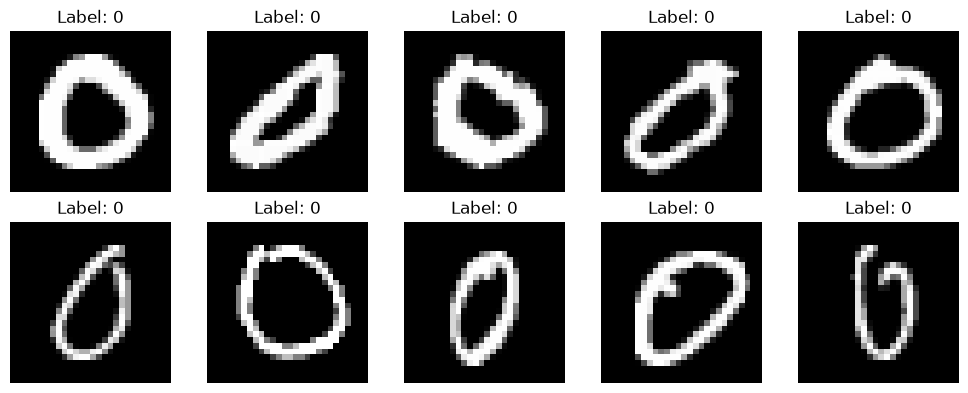

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for i, ax in enumerate(axes.flat):
    ax.imshow(x_train[i].squeeze(), cmap="gray")
    ax.set_title(f"Label: {y_train[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [5]:
EPOCHS = 100
BATCH_SIZE = 32

results = {}

In [6]:
def plot_history(history, title="Training History"):
    epochs = range(1, len(history.history["loss"]) + 1)

    # Accuracy
    plt.figure(figsize=(7, 5))
    plt.plot(epochs, history.history["accuracy"], label="Training Accuracy")
    plt.plot(epochs, history.history["val_accuracy"], label="Validation Accuracy")

    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title(title + " - Accuracy")
    plt.legend()
    plt.grid()
    plt.show()

    # Loss
    plt.figure(figsize=(7, 5))
    plt.plot(epochs, history.history["loss"], label="Training Loss")
    plt.plot(epochs, history.history["val_loss"], label="Validation Loss")

    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(title + " - Loss")
    plt.legend()
    plt.grid()
    plt.show()

In [7]:
def evaluate_model(name, model, history):

    train_loss, train_acc = model.evaluate(
        x_train,
        y_train,
        verbose=0
    )

    val_loss, val_acc = model.evaluate(
        x_val,
        y_val,
        verbose=0
    )

    test_loss, test_acc = model.evaluate(
        x_test,
        y_test,
        verbose=0
    )

    best_val_acc = max(history.history["val_accuracy"])

    gap = train_acc - val_acc

    results[name] = {
        "Train Accuracy": train_acc,
        "Validation Accuracy": val_acc,
        "Best Validation Accuracy": best_val_acc,
        "Test Accuracy": test_acc,
        "Train-Val Gap": gap
    }

    print("=" * 50)
    print(name)
    print("=" * 50)

    print(f"Train Accuracy      : {train_acc:.4f}")
    print(f"Validation Accuracy : {val_acc:.4f}")
    print(f"Best Val Accuracy   : {best_val_acc:.4f}")
    print(f"Test Accuracy       : {test_acc:.4f}")
    print(f"Train-Val Gap       : {gap:.4f}")

In [8]:
def create_baseline_model():

    tf.keras.backend.clear_session()

    model = keras.Sequential([

        layers.Input(shape=(28, 28, 1)),

        # -------------------------
        # Convolution Block 1
        # -------------------------

        layers.Conv2D(
            64,
            kernel_size=3,
            padding="same",
            activation="relu",
            kernel_initializer=fixed_kernel(0),
            bias_initializer="zeros"
        ),

        layers.Conv2D(
            64,
            kernel_size=3,
            padding="same",
            activation="relu",
            kernel_initializer=fixed_kernel(1),
            bias_initializer="zeros"
        ),

        layers.MaxPooling2D(pool_size=2),

        # -------------------------
        # Convolution Block 2
        # -------------------------

        layers.Conv2D(
            128,
            kernel_size=3,
            padding="same",
            activation="relu",
            kernel_initializer=fixed_kernel(2),
            bias_initializer="zeros"
        ),

        layers.Conv2D(
            128,
            kernel_size=3,
            padding="same",
            activation="relu",
            kernel_initializer=fixed_kernel(3),
            bias_initializer="zeros"
        ),

        layers.MaxPooling2D(pool_size=2),

        # -------------------------
        # Large Fully Connected Layers
        # -------------------------

        layers.Flatten(),

        layers.Dense(
            2048,
            activation="relu",
            kernel_initializer=fixed_kernel(4),
            bias_initializer="zeros"
        ),

        layers.Dense(
            1024,
            activation="relu",
            kernel_initializer=fixed_kernel(5),
            bias_initializer="zeros"
        ),

        layers.Dense(
            512,
            activation="relu",
            kernel_initializer=fixed_kernel(6),
            bias_initializer="zeros"
        ),

        # -------------------------
        # Output
        # -------------------------

        layers.Dense(
            10,
            activation="softmax",
            kernel_initializer=fixed_kernel(7),
            bias_initializer="zeros"
        )
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=0.001
        ),

        loss="sparse_categorical_crossentropy",

        metrics=["accuracy"]
    )

    return model

# Baseline CNN

首先建立一個沒有使用任何 Overfitting 改善方法的 Baseline CNN。

Baseline Model **不使用**：

- L2 Regularization
- Dropout
- Data Augmentation
- Early Stopping
- Batch Normalization

同時，我們會刻意使用相對較大的 CNN，例如加入多層 Convolutional Layer 與 Dense Layer。

由於 Training Data 只有少量樣本，而模型具有大量可訓練參數，因此模型很容易記住 Training Data。

Baseline Model 將作為後續所有方法的比較基準。

In [9]:
baseline_model = create_baseline_model()

baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2048)           │    12,847,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1024)           │     2,098,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,734,218 (60.02 MB)

 Trainable params: 15,734,218 (60.02 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
# Check: creating the baseline twice yields identical initial weights.
reference_weights = [w.copy() for w in baseline_model.get_weights()]
second_model = create_baseline_model()
assert all(np.array_equal(a, b) for a, b in zip(reference_weights, second_model.get_weights()))
del second_model
print("PASS: Baseline initialization is identical across repeated model creations.")

PASS: Baseline initialization is identical across repeated model creations.


In [11]:
train_ds = (
    tf.data.Dataset.from_tensor_slices((x_train, y_train))
    .shuffle(buffer_size=len(x_train), seed=2026, reshuffle_each_iteration=True)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

baseline_history = baseline_model.fit(
    train_ds,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    verbose=1
)


Epoch 1/100


/Users/c2838/NCHU/115-1 中興作業/computer_vision/c3_hw/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step - accuracy: 0.0950 - loss: 2.3253

2026-10-03 19:34:51.249878: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 623ms/step - accuracy: 0.0950 - loss: 2.3253 - val_accuracy: 0.3382 - val_loss: 2.2682
Epoch 2/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 538ms/step - accuracy: 0.3500 - loss: 2.0483 - val_accuracy: 0.4016 - val_loss: 1.4893
Epoch 3/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 552ms/step - accuracy: 0.6200 - loss: 1.1782 - val_accuracy: 0.5150 - val_loss: 1.2127
Epoch 4/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 547ms/step - accuracy: 0.7200 - loss: 0.7228 - val_accuracy: 0.8292 - val_loss: 0.5794
Epoch 5/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 556ms/step - accuracy: 0.8500 - loss: 0.3984 - val_accuracy: 0.8304 - val_loss: 0.5788
Epoch 6/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 562ms/step - accuracy: 0.8950 - loss: 0.3394 - val_accuracy: 0.7942 - val_loss: 0.7291
Epoch 7/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 694ms/step - accuracy: 0.9200 - loss: 0.2193 - val_accuracy: 0.8452 - val_loss: 0.5616
Epoch 8/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 560ms/step - accuracy: 0.9400 - loss: 0.1750 - val_accuracy: 0.8478 - val_loss: 0.6

# Observing Overfitting

訓練完成後，可以透過 Training Curve 判斷模型是否產生 Overfitting。

主要觀察兩組指標：

## Accuracy

比較：

- Training Accuracy
- Validation Accuracy

如果 Training Accuracy 持續增加，而 Validation Accuracy 停止增加，代表模型可能開始 Overfitting。

特別是當：

`Training Accuracy >> Validation Accuracy`

時，通常代表模型在 Training Data 上表現很好，但泛化能力不足。

---

## Loss

比較：

- Training Loss
- Validation Loss

典型的 Overfitting 現象為：

- Training Loss 持續下降
- Validation Loss 先下降後上升

當 Validation Loss 開始上升時，代表模型雖然仍持續改善 Training Data 的預測結果，但在未看過的資料上的表現已經開始下降。

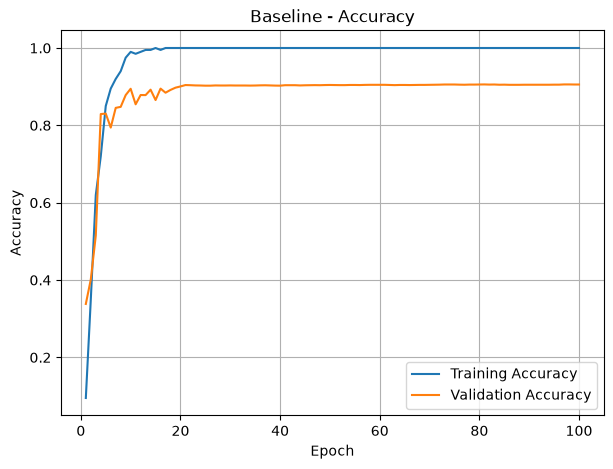

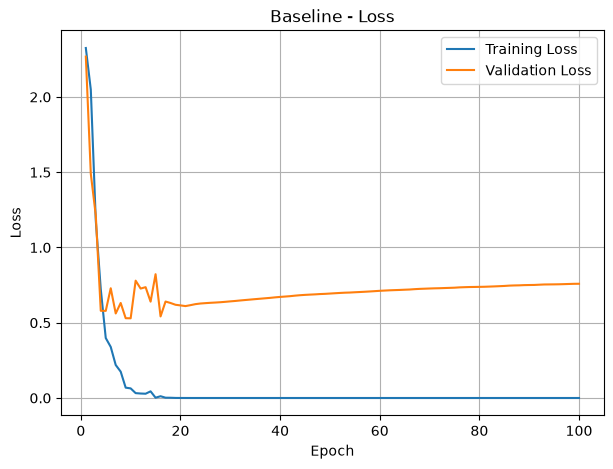

In [12]:
plot_history(
    baseline_history,
    "Baseline"
)

# Train-Validation Gap

我們也可以利用 Training Accuracy 與 Validation Accuracy 的差距觀察模型的 Overfitting 程度。

定義：

`Train-Val Gap = Training Accuracy - Validation Accuracy`

如果 Train-Val Gap 很大，代表模型在 Training Data 與 Validation Data 之間存在較大的效能落差。

例如：

`Training Accuracy = 0.99`

`Validation Accuracy = 0.91`

則：

`Train-Val Gap = 0.08`

一般而言，較大的 Train-Val Gap 可能代表較明顯的 Overfitting。

In [13]:
evaluate_model(
    "Baseline",
    baseline_model,
    baseline_history
)

2026-10-03 19:42:13.508887: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


Baseline
Train Accuracy      : 1.0000
Validation Accuracy : 0.9056
Best Val Accuracy   : 0.9058
Test Accuracy       : 0.9209
Train-Val Gap       : 0.0944


# Part 1 — L2 Regularization

L2 Regularization 是常見的 Regularization 方法。

L2 Regularization 會在原本的 Loss Function 中加入一個 Weight Penalty，使模型避免產生過大的 Weight。

其概念可以表示為：

`Total Loss = Original Loss + λ × Σ(w²)`

其中：

- `w`：模型的 Weight
- `λ`：Regularization Strength

當 Weight 變得過大時，模型會受到額外的 Loss Penalty。

因此模型會傾向學習較小、較平滑的 Weight，而不是過度依賴少數特徵來記住 Training Data。

# L2 Regularization Strength

L2 Regularization 中的重要 Hyperparameter 為：

`λ`

也就是 Regularization Strength。

例如可以比較：

- `0.0001`
- `0.001`
- `0.01`

如果 L2 太小，可能無法有效改善 Overfitting。

但如果 L2 太大，模型會受到過強限制，可能無法有效學習 Training Data，進而產生 **Underfitting**。

因此 Regularization Strength 必須在模型學習能力與泛化能力之間取得平衡。

In [41]:
def create_l2_model(weight_decay):
    # 沿用範例模型架構與固定初始化，建立全新的模型。
    model = create_baseline_model()

    # 重新編譯：保留原本訓練設定，只加入 optimizer weight decay。
    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=0.001,
            weight_decay=weight_decay
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

## Part 1 L2 Regularization 訓練流程 (weight_decay = 1e-4)

In [ ]:
class BestValidationAccuracy(keras.callbacks.Callback):
    # 初始化參數
    def on_train_begin(self, logs=None):
        self.best_accuracy = -np.inf
        self.best_epoch = None
        self.best_weights = None

    # 依照最佳 val_accuracy 來儲存最佳模型
    def on_epoch_end(self, epoch, logs=None):
        val_accuracy = float(logs["val_accuracy"])

        if val_accuracy > self.best_accuracy:
            self.best_accuracy = val_accuracy
            self.best_epoch = epoch + 1
            self.best_weights = self.model.get_weights()


# 每次執行都從全新的模型開始
L2_WEIGHT_DECAY = 1e-4
l2_model = create_l2_model(weight_decay=L2_WEIGHT_DECAY)

# 保留範例的 Training Dataset 設定
l2_train_ds = (
    tf.data.Dataset.from_tensor_slices((x_train, y_train))
    .shuffle(
        buffer_size=len(x_train),
        seed=2026,
        reshuffle_each_iteration=True
    )
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

l2_best = BestValidationAccuracy()

l2_history = l2_model.fit(
    l2_train_ds,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    callbacks=[l2_best],
    verbose=2
)

# 訓練完成後，載回 Validation Accuracy 最佳的權重。
l2_model.set_weights(l2_best.best_weights)

print("\n=== Part 1: Weight Decay Trial 1 ===")
print(f"Weight decay: {L2_WEIGHT_DECAY}")
print(f"Completed epochs: {len(l2_history.history['loss'])}")
print(f"Best Validation Accuracy: {l2_best.best_accuracy:.2%}")
print(f"Best Epoch: {l2_best.best_epoch}")
print("Best validation weights restored.")

Epoch 1/100


2026-10-04 00:17:49.245763: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


7/7 - 4s - 628ms/step - accuracy: 0.0950 - loss: 2.3253 - val_accuracy: 0.3382 - val_loss: 2.2682
Epoch 2/100
7/7 - 3s - 455ms/step - accuracy: 0.3500 - loss: 2.0484 - val_accuracy: 0.4016 - val_loss: 1.4892
Epoch 3/100
7/7 - 3s - 461ms/step - accuracy: 0.6200 - loss: 1.1784 - val_accuracy: 0.5162 - val_loss: 1.2109
Epoch 4/100
7/7 - 3s - 485ms/step - accuracy: 0.7200 - loss: 0.7209 - val_accuracy: 0.8298 - val_loss: 0.5809
Epoch 5/100
7/7 - 3s - 482ms/step - accuracy: 0.8500 - loss: 0.3979 - val_accuracy: 0.8272 - val_loss: 0.5867
Epoch 6/100
7/7 - 4s - 559ms/step - accuracy: 0.8850 - loss: 0.3393 - val_accuracy: 0.7934 - val_loss: 0.7407
Epoch 7/100
7/7 - 4s - 504ms/step - accuracy: 0.9150 - loss: 0.2254 - val_accuracy: 0.8494 - val_loss: 0.5454
Epoch 8/100
7/7 - 4s - 581ms/step - accuracy: 0.9350 - loss: 0.1842 - val_accuracy: 0.8532 - val_loss: 0.5984
Epoch 9/100
7/7 - 3s - 498ms/step - accuracy: 0.9650 - loss: 0.0767 - val_accuracy: 0.8756 - val_loss: 0.5304
Epoch 10/100
7/7 - 4s 

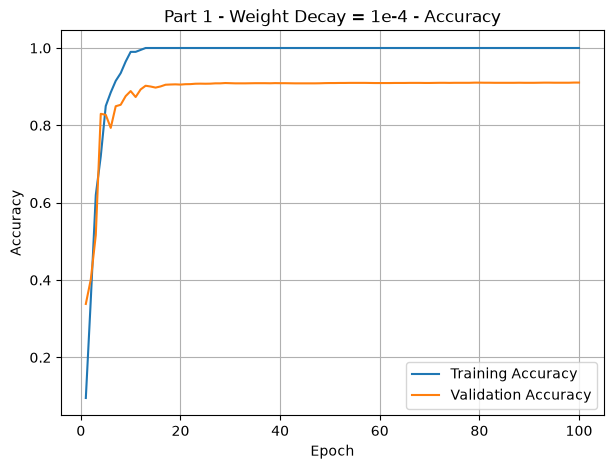

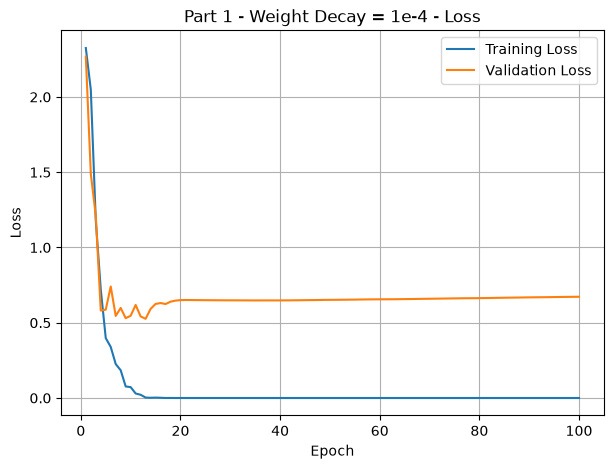

In [34]:
plot_history(
    l2_history,
    title="Part 1 - Weight Decay = 1e-4"
)

## Part 1 L2 Regularization 訓練流程 (weight_decay = 1e-3)

Epoch 1/100


2026-10-04 00:26:29.657799: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


7/7 - 5s - 694ms/step - accuracy: 0.0950 - loss: 2.3253 - val_accuracy: 0.3382 - val_loss: 2.2682
Epoch 2/100
7/7 - 6s - 837ms/step - accuracy: 0.3500 - loss: 2.0488 - val_accuracy: 0.4038 - val_loss: 1.4829
Epoch 3/100
7/7 - 6s - 796ms/step - accuracy: 0.6100 - loss: 1.1752 - val_accuracy: 0.5150 - val_loss: 1.2099
Epoch 4/100
7/7 - 6s - 823ms/step - accuracy: 0.7200 - loss: 0.7266 - val_accuracy: 0.8284 - val_loss: 0.5809
Epoch 5/100
7/7 - 7s - 947ms/step - accuracy: 0.8450 - loss: 0.4162 - val_accuracy: 0.8346 - val_loss: 0.5681
Epoch 6/100
7/7 - 8s - 1s/step - accuracy: 0.9000 - loss: 0.3442 - val_accuracy: 0.8060 - val_loss: 0.6933
Epoch 7/100
7/7 - 6s - 819ms/step - accuracy: 0.9200 - loss: 0.2111 - val_accuracy: 0.8322 - val_loss: 0.6112
Epoch 8/100
7/7 - 7s - 989ms/step - accuracy: 0.9450 - loss: 0.1746 - val_accuracy: 0.8600 - val_loss: 0.5800
Epoch 9/100
7/7 - 5s - 761ms/step - accuracy: 0.9850 - loss: 0.0564 - val_accuracy: 0.8978 - val_loss: 0.4478
Epoch 10/100
7/7 - 6s - 8

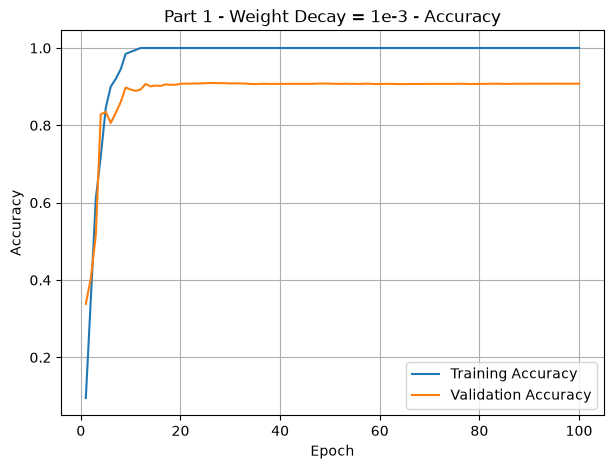

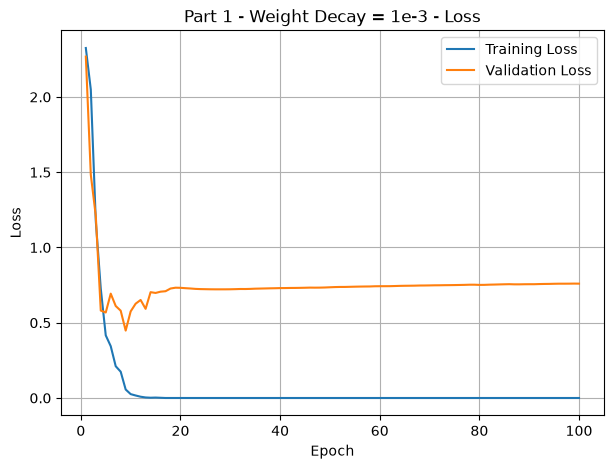

In [35]:
# 第二次實驗：將 weight decay 改成 1e-3。
# 使用新的變數，保留第一次實驗的模型與訓練紀錄。
L2_WEIGHT_DECAY_2 = 1e-3
l2_model_2 = create_l2_model(weight_decay=L2_WEIGHT_DECAY_2)

l2_train_ds_2 = (
    tf.data.Dataset.from_tensor_slices((x_train, y_train))
    .shuffle(
        buffer_size=len(x_train),
        seed=2026,
        reshuffle_each_iteration=True
    )
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

l2_best_2 = BestValidationAccuracy()

l2_history_2 = l2_model_2.fit(
    l2_train_ds_2,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    callbacks=[l2_best_2],
    verbose=2
)

# 恢復第二次實驗中，驗證準確率最高的權重。
l2_model_2.set_weights(l2_best_2.best_weights)

print("\n=== Part 1: Weight Decay Trial 2 ===")
print(f"Weight decay: {L2_WEIGHT_DECAY_2}")
print(f"Completed epochs: {len(l2_history_2.history['loss'])}")
print(f"Best Validation Accuracy: {l2_best_2.best_accuracy:.2%}")
print(f"Best Epoch: {l2_best_2.best_epoch}")
print("Best validation weights restored.")

plot_history(
    l2_history_2,
    title="Part 1 - Weight Decay = 1e-3"
)

In [36]:
# 只依 Validation Accuracy 選擇設定。
# 若兩者相同，保留第一個設定。
is_l2_best_2_val_accuracy_better = l2_best_2.best_accuracy > l2_best.best_accuracy

l2_selected_weight_decay = L2_WEIGHT_DECAY_2 if is_l2_best_2_val_accuracy_better else L2_WEIGHT_DECAY
l2_selected_model = l2_model_2 if is_l2_best_2_val_accuracy_better else l2_model
l2_selected_history = l2_history_2 if is_l2_best_2_val_accuracy_better else l2_history
l2_selected_best = l2_best_2 if is_l2_best_2_val_accuracy_better else l2_best

# 確保評估的是最佳驗證準確率當下的權重。
l2_selected_model.set_weights(l2_selected_best.best_weights)

print(f"Selected weight decay: {l2_selected_weight_decay}")
print(f"Best Epoch: {l2_selected_best.best_epoch}")
print(
    f"Best Validation Accuracy: "
    f"{l2_selected_best.best_accuracy:.2%}"
)

# 沿用老師的函式，評估選定模型並記錄至 results。
evaluate_model(
    "Part 1 - Weight Decay",
    l2_selected_model,
    l2_selected_history
)

results["Part 1 - Weight Decay"]["Weight Decay"] = (
    l2_selected_weight_decay
)
results["Part 1 - Weight Decay"]["Best Epoch"] = (
    l2_selected_best.best_epoch
)

Selected weight decay: 0.0001
Best Epoch: 99
Best Validation Accuracy: 91.06%


2026-10-04 00:38:48.586786: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


Part 1 - Weight Decay
Train Accuracy      : 1.0000
Validation Accuracy : 0.9106
Best Val Accuracy   : 0.9106
Test Accuracy       : 0.9290
Train-Val Gap       : 0.0894


## 本次實作補充與結果

本次依題目要求，在 Adam optimizer 中設定 `weight_decay`，比較 `0.0001` 與 `0.001`，模型架構及其他訓練設定保持一致。上方的 L2 公式是一般概念介紹；本程式採用 optimizer 的權重衰減，Adam 中此方法與直接在 loss 加入 L2 penalty 有差異，訓練顯示的 loss 來自原本的分類損失。依最佳 Validation Accuracy 選擇 `weight_decay=0.0001`，最佳驗證準確率為 91.06%，最佳 epoch 為 99，Test Accuracy 為 92.90%。

# Part 2 — Dropout

Dropout 是 Neural Network 中常見的 Regularization 方法。

在 Training 階段，Dropout 會隨機將部分 Neuron 的輸出設為 0。

例如：

`Dropout Rate = 0.5`

代表每次 Training 時，大約有 50% 的 Neuron 會被暫時關閉。

因此模型無法一直依賴固定的一組 Neuron 進行預測。

模型必須學習更加分散且穩健的 Feature Representation。

# Dropout Rate

Dropout Rate 是重要的 Hyperparameter。

例如：

- `0.2`
- `0.5`
- `0.8`

Dropout Rate 太低時，可能無法有效降低 Overfitting。

但 Dropout Rate 太高時，大量 Neuron 被關閉，可能使模型沒有足夠能力學習資料。

因此過強的 Dropout 也可能造成 **Underfitting**。

## Part 2 Dropout 訓練流程 (drop_rate = 0.5)

In [37]:
def create_dropout_model(dropout_rate):
    # 建立全新的 baseline，沿用範例的架構與固定初始化
    base_model = create_baseline_model()

    model = keras.Sequential([
        layers.Input(shape=(28, 28, 1))
    ])

    dropout_index = 0

    # 先加入最終輸出層以外的各層
    for layer in base_model.layers[:-1]:
        model.add(layer)

        # 在每個 hidden Dense 的 activation 後加入 Dropout
        if isinstance(layer, layers.Dense):
            dropout_index += 1
            model.add(
                layers.Dropout(
                    rate=dropout_rate,
                    seed=3000 + dropout_index,
                    name=f"dropout_{dropout_index}"
                )
            )

    # 最後加入原本的輸出層，確保後面不放 Dropout
    model.add(base_model.layers[-1])

    # 沿用 baseline 的 optimizer 設定
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

DROPOUT_RATE = 0.5
dropout_model = create_dropout_model(dropout_rate=DROPOUT_RATE)

dropout_model.summary()
print("Parameters:", dropout_model.count_params())
print("Dropout rate:", DROPOUT_RATE)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2048)           │    12,847,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1024)           │     2,098,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,734,218 (60.02 MB)

 Trainable params: 15,734,218 (60.02 MB)

 Non-trainable params: 0 (0.00 B)

Parameters: 15734218
Dropout rate: 0.5


Epoch 1/100


/Users/c2838/NCHU/115-1 中興作業/computer_vision/c3_hw/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
2026-10-04 01:56:32.290690: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. 

7/7 - 6s - 807ms/step - accuracy: 0.0700 - loss: 2.3364 - val_accuracy: 0.0974 - val_loss: 2.2991
Epoch 2/100
7/7 - 4s - 584ms/step - accuracy: 0.0900 - loss: 2.2975 - val_accuracy: 0.1610 - val_loss: 2.2839
Epoch 3/100
7/7 - 3s - 425ms/step - accuracy: 0.0900 - loss: 2.2918 - val_accuracy: 0.1268 - val_loss: 2.2523
Epoch 4/100
7/7 - 3s - 445ms/step - accuracy: 0.1200 - loss: 2.2228 - val_accuracy: 0.1024 - val_loss: 2.0595
Epoch 5/100
7/7 - 3s - 482ms/step - accuracy: 0.3100 - loss: 1.9261 - val_accuracy: 0.6018 - val_loss: 1.3381
Epoch 6/100
7/7 - 4s - 528ms/step - accuracy: 0.5450 - loss: 1.4710 - val_accuracy: 0.5476 - val_loss: 1.3346
Epoch 7/100
7/7 - 4s - 575ms/step - accuracy: 0.6050 - loss: 1.1357 - val_accuracy: 0.7590 - val_loss: 0.7262
Epoch 8/100
7/7 - 3s - 452ms/step - accuracy: 0.7450 - loss: 0.7630 - val_accuracy: 0.8204 - val_loss: 0.6401
Epoch 9/100
7/7 - 3s - 484ms/step - accuracy: 0.8100 - loss: 0.5947 - val_accuracy: 0.8670 - val_loss: 0.4743
Epoch 10/100
7/7 - 3s 

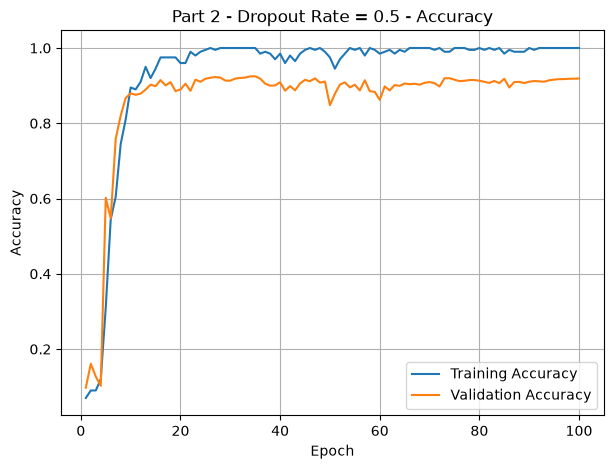

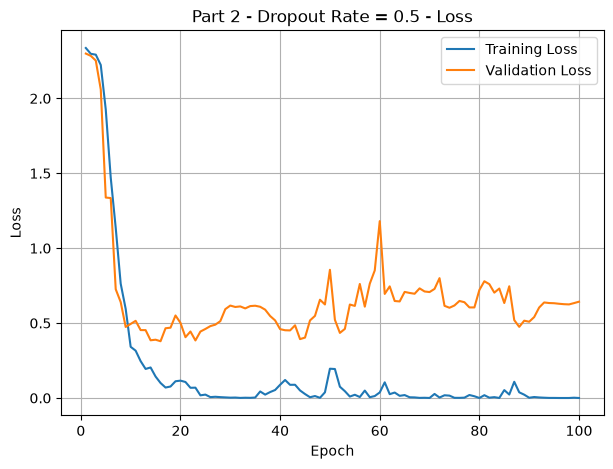

In [42]:
# 重新建立模型，確保每次執行都從固定的初始權重開始。
dropout_model = create_dropout_model(dropout_rate=DROPOUT_RATE)

# 沿用老師的訓練資料流程，重新建立 shuffle 狀態。
dropout_train_ds = (
    tf.data.Dataset.from_tensor_slices((x_train, y_train))
    .shuffle(
        buffer_size=len(x_train),
        seed=2026,
        reshuffle_each_iteration=True
    )
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

# 沿用 Part 1 的 Callback，記錄最佳驗證準確率。
dropout_best = BestValidationAccuracy()

dropout_history = dropout_model.fit(
    dropout_train_ds,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    callbacks=[dropout_best],
    verbose=2
)

# 訓練完成後，恢復最佳驗證準確率當下的權重。
dropout_model.set_weights(dropout_best.best_weights)

print("\n=== Part 2: Dropout Trial ===")
print(f"Dropout rate: {DROPOUT_RATE}")
print(f"Completed epochs: {len(dropout_history.history['loss'])}")
print(f"Best Validation Accuracy: {dropout_best.best_accuracy:.2%}")
print(f"Best Epoch: {dropout_best.best_epoch}")
print("Best validation weights restored.")

plot_history(
    dropout_history,
    title=f"Part 2 - Dropout Rate = {DROPOUT_RATE}"
)

## Part 2 Dropout 訓練流程 (drop_rate = 0.2)

Epoch 1/100


2026-10-04 02:07:27.034196: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


7/7 - 5s - 666ms/step - accuracy: 0.0750 - loss: 2.3330 - val_accuracy: 0.2224 - val_loss: 2.2913
Epoch 2/100
7/7 - 3s - 468ms/step - accuracy: 0.2050 - loss: 2.2379 - val_accuracy: 0.1610 - val_loss: 2.0803
Epoch 3/100
7/7 - 3s - 477ms/step - accuracy: 0.4100 - loss: 1.5772 - val_accuracy: 0.5276 - val_loss: 1.4044
Epoch 4/100
7/7 - 3s - 479ms/step - accuracy: 0.6500 - loss: 1.0645 - val_accuracy: 0.7220 - val_loss: 0.8167
Epoch 5/100
7/7 - 3s - 478ms/step - accuracy: 0.8300 - loss: 0.5505 - val_accuracy: 0.7572 - val_loss: 0.9554
Epoch 6/100
7/7 - 3s - 491ms/step - accuracy: 0.8250 - loss: 0.6043 - val_accuracy: 0.8078 - val_loss: 0.6159
Epoch 7/100
7/7 - 3s - 472ms/step - accuracy: 0.8950 - loss: 0.3400 - val_accuracy: 0.8780 - val_loss: 0.4190
Epoch 8/100
7/7 - 3s - 490ms/step - accuracy: 0.9600 - loss: 0.1310 - val_accuracy: 0.8540 - val_loss: 0.6855
Epoch 9/100
7/7 - 4s - 542ms/step - accuracy: 0.9500 - loss: 0.1501 - val_accuracy: 0.8664 - val_loss: 0.6546
Epoch 10/100
7/7 - 5s 

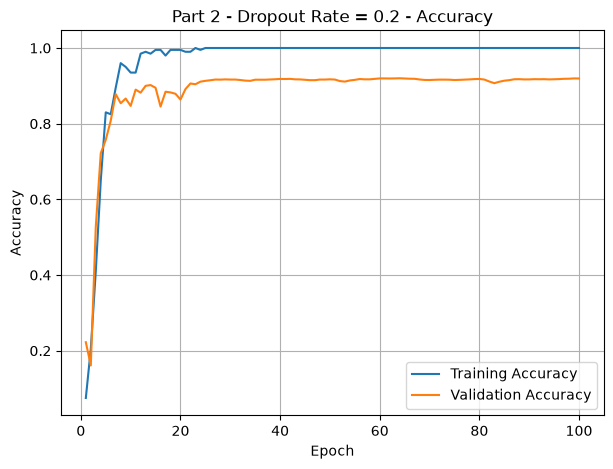

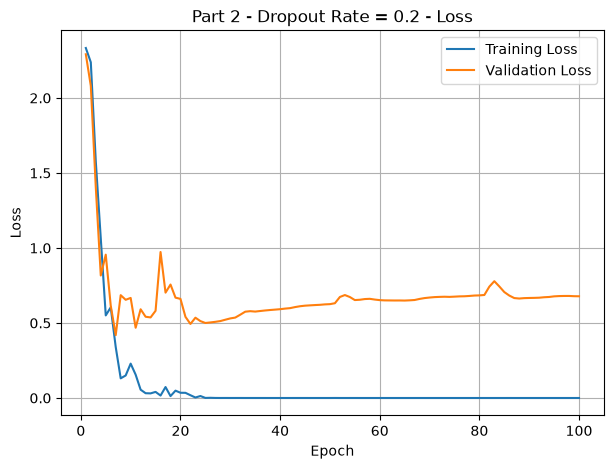

In [43]:
# 第二次實驗：降低 Dropout rate，保留第一次實驗的紀錄。
DROPOUT_RATE_2 = 0.2
dropout_model_2 = create_dropout_model(
    dropout_rate=DROPOUT_RATE_2
)

# 重新建立資料集，維持相同的資料輸入條件。
dropout_train_ds_2 = (
    tf.data.Dataset.from_tensor_slices((x_train, y_train))
    .shuffle(
        buffer_size=len(x_train),
        seed=2026,
        reshuffle_each_iteration=True
    )
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

dropout_best_2 = BestValidationAccuracy()

dropout_history_2 = dropout_model_2.fit(
    dropout_train_ds_2,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    callbacks=[dropout_best_2],
    verbose=2
)

dropout_model_2.set_weights(dropout_best_2.best_weights)

print("\n=== Part 2: Dropout Trial 2 ===")
print(f"Dropout rate: {DROPOUT_RATE_2}")
print(f"Completed epochs: {len(dropout_history_2.history['loss'])}")
print(f"Best Validation Accuracy: {dropout_best_2.best_accuracy:.2%}")
print(f"Best Epoch: {dropout_best_2.best_epoch}")
print("Best validation weights restored.")

plot_history(
    dropout_history_2,
    title=f"Part 2 - Dropout Rate = {DROPOUT_RATE_2}"
)

In [44]:
# 只依 Validation Accuracy 選擇設定
# 若兩者相同，保留第一個設定
is_dropout_best_2_val_accuracy_better = dropout_best_2.best_accuracy > dropout_best.best_accuracy
dropout_selected_rate = DROPOUT_RATE_2 if is_dropout_best_2_val_accuracy_better else DROPOUT_RATE
dropout_selected_model = dropout_model_2 if is_dropout_best_2_val_accuracy_better else dropout_model
dropout_selected_history = dropout_history_2 if is_dropout_best_2_val_accuracy_better else dropout_history
dropout_selected_best = dropout_best_2 if is_dropout_best_2_val_accuracy_better else dropout_best


# 恢復選定設定中，驗證準確率最高的權重
dropout_selected_model.set_weights(
    dropout_selected_best.best_weights
)

print(f"Selected Dropout rate: {dropout_selected_rate}")
print(f"Best Epoch: {dropout_selected_best.best_epoch}")
print(
    f"Best Validation Accuracy: "
    f"{dropout_selected_best.best_accuracy:.2%}"
)

# 評估選定模型，取得 Part 2 的最終 Test Accuracy
evaluate_model(
    "Part 2 - Dropout",
    dropout_selected_model,
    dropout_selected_history
)

results["Part 2 - Dropout"]["Dropout Rate"] = dropout_selected_rate
results["Part 2 - Dropout"]["Best Epoch"] = (
    dropout_selected_best.best_epoch
)

Selected Dropout rate: 0.5
Best Epoch: 35
Best Validation Accuracy: 92.48%


2026-10-04 02:22:57.699664: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


Part 2 - Dropout
Train Accuracy      : 1.0000
Validation Accuracy : 0.9248
Best Val Accuracy   : 0.9248
Test Accuracy       : 0.9354
Train-Val Gap       : 0.0752


## 本次實驗設計與結果

Dropout 放在三個隱藏 Dense 層的 ReLU activation 後，最終分類輸出層保持原樣，目的是減少模型對少數隱藏特徵的依賴。本次比較 `0.5` 與 `0.2`，依最佳 Validation Accuracy 選擇 `0.5`，最佳驗證準確率為 92.48%，最佳 epoch 為 35，Test Accuracy 為 93.54%。Train–Validation Gap 為 7.52 個百分點，低於本機 baseline 的 9.44 個百分點，但仍存在泛化差距。

# Part 3 — Data Augmentation

Data Augmentation 的概念是利用原始圖片產生具有合理變化的新 Training Samples。

例如對 MNIST 圖片進行：

- Rotation
- Translation
- Zoom

假設原本只有 1,000 張 Training Images，透過 Data Augmentation，模型每個 Epoch 都可能看到稍微不同版本的圖片。

因此模型比較難直接記住原始 Training Images。

## 選擇的 Data Augmentation 方法 - Translation
本實驗選擇隨機平移（Translation）。手寫數字在圖片中的位置可能略有不同，因此透過小幅平移，讓模型學習在位置改變後仍辨識同一個數字，減少對固定座標的依賴。本次水平與垂直位移範圍皆設定為圖片尺寸的 ±10%，約為 ±2.8 個像素，平移後空出的區域以黑色填補。

未選擇 Rotation，是考量較大角度的旋轉可能改變數字的方向特徵，例如部分手寫的 6 與 9 可能因此產生辨識歧義。不過，小角度旋轉仍可模擬手寫傾斜，是合理的候選方法；本次先以主要改變位置的小幅平移作為實驗。

未選擇 Zoom，並非認為縮放不適合數字辨識。小幅縮放可模擬不同的書寫大小，但放大過多可能裁切關鍵筆畫，縮小過多則可能降低低解析度圖片中的筆畫細節。本次優先測試位置變化，因此先選擇 Translation。

本實驗僅對 Training Set 套用隨機平移，Validation Set 與 Test Set 保留原本的資料處理。以上為方法選擇的設計理由，尚未透過實驗比較 Rotation、Translation 與 Zoom 的優劣；Translation 的實際效果將依 Validation 表現評估。

| 參數 | 設定與意義 |
|---|---|
| `height_factor=0.1` | 垂直方向隨機移動 −10%～+10% |
| `width_factor=0.1` | 水平方向隨機移動 −10%～+10% |
| `fill_mode="constant"` | 平移後空出的區域填入固定值 |
| `fill_value=0.0` | 填入黑色，配合正規化後的 MNIST 背景 |
| `interpolation="bilinear"` | 移動涉及非整數座標時，以雙線性插值計算像素 |


Augmentation method: RandomTranslation
Height factor: ±10%
Width factor: ±10%
Fill mode: constant; fill value: 0.0
Interpolation: bilinear


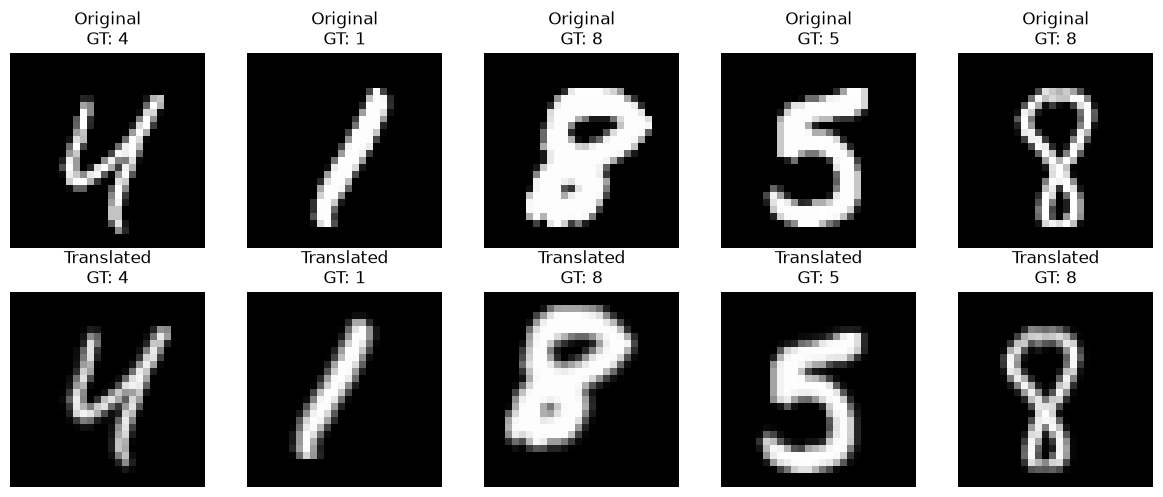

In [ ]:
TRANSLATION_FACTOR = 0.1


def create_translation_augmentation(translation_factor):
    return layers.RandomTranslation(
        height_factor=translation_factor,
        width_factor=translation_factor,
        fill_mode="constant",
        fill_value=0.0,
        interpolation="bilinear",
        seed=4101
    )


#  隨機選取 5 張訓練圖片，不重複抽樣
preview_rng = np.random.default_rng(4200)
preview_indices = preview_rng.choice(
    len(x_train),
    size=5,
    replace=False
)

# 預覽使用獨立的增強層，後續訓練會另外建立
preview_augmentation = create_translation_augmentation(
    TRANSLATION_FACTOR
)

preview_images = preview_augmentation(
    x_train[preview_indices],
    training=True
).numpy()

print("Augmentation method: RandomTranslation")
print(f"Height factor: ±{TRANSLATION_FACTOR:.0%}")
print(f"Width factor: ±{TRANSLATION_FACTOR:.0%}")
print("Fill mode: constant; fill value: 0.0")
print("Interpolation: bilinear")

# 上排原圖，下排增強後的圖片。
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for column, sample_index in enumerate(preview_indices):
    label = int(y_train[sample_index])

    axes[0, column].imshow(
        x_train[sample_index, :, :, 0],
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[0, column].set_title(f"Original\nGT: {label}")
    axes[0, column].axis("off")

    axes[1, column].imshow(
        preview_images[column, :, :, 0],
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[1, column].set_title(f"Translated\nGT: {label}")
    axes[1, column].axis("off")

plt.tight_layout()
plt.show()


In [59]:
def create_data_augmentation_model(translation_factor):
    # 建立全新的 baseline，沿用範例架構與固定初始化
    base_model = create_baseline_model()

    # 在原本的 CNN 前加入隨機平移
    # 獨立增強層，讓訓練不受預覽的隨機狀態影響
    model = keras.Sequential([
        layers.Input(shape=(28, 28, 1)),
        create_translation_augmentation(translation_factor)
    ])

    # 依序加入 baseline 的所有運算層。
    for layer in base_model.layers:
        model.add(layer)

    # 沿用 baseline 的訓練設定。
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


augmentation_model = create_data_augmentation_model(
    translation_factor=TRANSLATION_FACTOR
)

augmentation_model.summary()
print("Parameters:", augmentation_model.count_params())
print("Translation factor:", TRANSLATION_FACTOR)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_translation              │ (None, 28, 28, 1)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2048)           │    12,847,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1024)           │     2,098,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,734,218 (60.02 MB)

 Trainable params: 15,734,218 (60.02 MB)

 Non-trainable params: 0 (0.00 B)

Parameters: 15734218
Translation factor: 0.1


Epoch 1/100


/Users/c2838/NCHU/115-1 中興作業/computer_vision/c3_hw/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
2026-10-04 03:12:43.233267: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. 

7/7 - 5s - 701ms/step - accuracy: 0.0700 - loss: 2.3318 - val_accuracy: 0.0986 - val_loss: 2.2962
Epoch 2/100
7/7 - 3s - 438ms/step - accuracy: 0.1150 - loss: 2.2756 - val_accuracy: 0.0974 - val_loss: 2.2537
Epoch 3/100
7/7 - 3s - 442ms/step - accuracy: 0.2050 - loss: 2.0891 - val_accuracy: 0.4194 - val_loss: 1.6178
Epoch 4/100
7/7 - 3s - 441ms/step - accuracy: 0.4000 - loss: 1.6074 - val_accuracy: 0.4636 - val_loss: 1.3620
Epoch 5/100
7/7 - 3s - 446ms/step - accuracy: 0.5050 - loss: 1.4621 - val_accuracy: 0.6914 - val_loss: 0.8940
Epoch 6/100
7/7 - 3s - 435ms/step - accuracy: 0.6200 - loss: 1.0006 - val_accuracy: 0.6888 - val_loss: 0.9030
Epoch 7/100
7/7 - 3s - 442ms/step - accuracy: 0.7050 - loss: 0.8167 - val_accuracy: 0.8398 - val_loss: 0.5165
Epoch 8/100
7/7 - 3s - 444ms/step - accuracy: 0.7950 - loss: 0.5986 - val_accuracy: 0.8358 - val_loss: 0.5173
Epoch 9/100
7/7 - 3s - 449ms/step - accuracy: 0.7950 - loss: 0.4632 - val_accuracy: 0.8442 - val_loss: 0.5136
Epoch 10/100
7/7 - 3s 

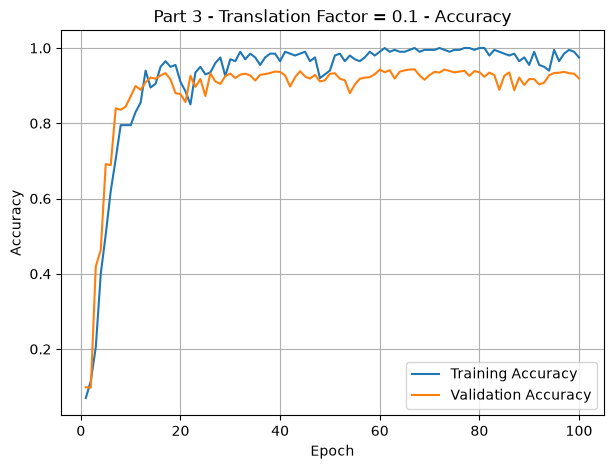

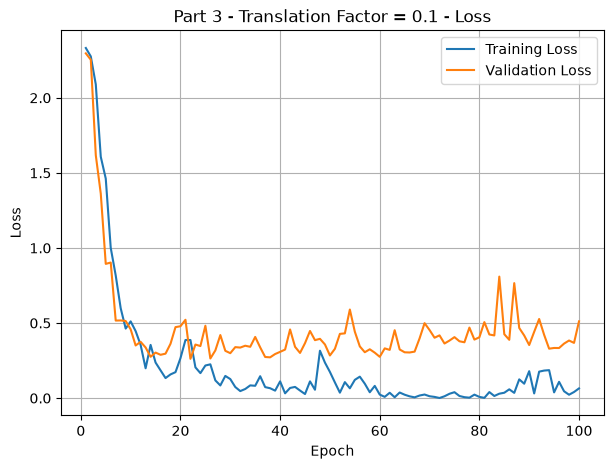

In [60]:
# 沿用範例的訓練資料流程
# 隨機平移已放在模型內，因此這裡不需要再套用增強
augmentation_train_ds = (
    tf.data.Dataset.from_tensor_slices((x_train, y_train))
    .shuffle(
        buffer_size=len(x_train),
        seed=2026,
        reshuffle_each_iteration=True
    )
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

# 記錄 Validation Accuracy 最高的模型權重。
augmentation_best = BestValidationAccuracy()

augmentation_history = augmentation_model.fit(
    augmentation_train_ds,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    callbacks=[augmentation_best],
    verbose=2
)

# 訓練完成後，恢復最佳驗證準確率當下的權重。
augmentation_model.set_weights(augmentation_best.best_weights)

print("\n=== Part 3: Translation Trial ===")
print(f"Translation factor: {TRANSLATION_FACTOR}")
print(f"Completed epochs: {len(augmentation_history.history['loss'])}")
print(f"Best Validation Accuracy: {augmentation_best.best_accuracy:.2%}")
print(f"Best Epoch: {augmentation_best.best_epoch}")
print("Best validation weights restored.")

plot_history(
    augmentation_history,
    title=f"Part 3 - Translation Factor = {TRANSLATION_FACTOR}"
)

In [ ]:
print(f"Selected Translation factor: {TRANSLATION_FACTOR}")
print(f"Best Epoch: {augmentation_best.best_epoch}")
print(
    f"Best Validation Accuracy: "
    f"{augmentation_best.best_accuracy:.2%}"
)

# 使用老師提供的函式，取得 Train、Validation 與 Test Accuracy。
evaluate_model(
    "Part 3 - Translation",
    augmentation_model,
    augmentation_history
)

results["Part 3 - Translation"]["Translation Factor"] = (
    TRANSLATION_FACTOR
)
results["Part 3 - Translation"]["Best Epoch"] = (
    augmentation_best.best_epoch
)

Selected Translation factor: 0.1
Best Epoch: 67
Best Validation Accuracy: 94.32%


2026-10-04 03:25:10.610911: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


Part 3 - Translation
Train Accuracy      : 1.0000
Validation Accuracy : 0.9432
Best Val Accuracy   : 0.9432
Test Accuracy       : 0.9510
Train-Val Gap       : 0.0568


## 本次實驗設計與結果

本 Part 僅使用 Translation，水平與垂直位移範圍為圖片尺寸的 ±10%，不與其他改進方法併用。最佳 Validation Accuracy 為 94.32%，最佳 epoch 為 67，Test Accuracy 為 95.10%，Train–Validation Gap 為 5.68 個百分點。此結果支持小幅位置變化對本次資料有幫助；本 Part 的結論限於 Translation，Rotation 與其他組合的比較另列於 Part 6。

# Part 4 — Early Stopping

Early Stopping 與 L2、Dropout 不同。

它不會直接修改 Neural Network Architecture。

Early Stopping 的概念是：

> 當 Validation Performance 不再改善時，停止 Training。

在模型 Training 初期：

- Training Loss 下降
- Validation Loss 下降

但當模型開始 Overfitting 後：

- Training Loss 仍然下降
- Validation Loss 開始上升

因此可以監控 Validation Loss，在模型尚未嚴重 Overfitting 前停止 Training。

## Part 4 early stopping 訓練流程 (patience = 10)

In [64]:
def create_early_stopping_model():
    # 沿用範例的架構、固定初始化與編譯設定。
    return create_baseline_model()

EARLY_STOPPING_PATIENCE = 10

early_stopping_model = create_early_stopping_model()

early_stopping_callback = keras.callbacks.EarlyStopping(
    monitor="val_loss", #  每個 epoch 結束後檢查 val loss
    mode="min", # val loss 越低越㪋
    min_delta=0.0, # 只要損失較低就算改善
    patience=EARLY_STOPPING_PATIENCE,
    restore_best_weights=True, # 訓練結束後，自動恢復最低 val loss 時的權重
    verbose=1 # 顯示停止與恢復權重的訊息
)

early_stopping_model.summary()

print("Parameters:", early_stopping_model.count_params())
print("Monitor:", early_stopping_callback.monitor)
print("Patience:", EARLY_STOPPING_PATIENCE)
print(
    "Restore best weights:",
    early_stopping_callback.restore_best_weights
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2048)           │    12,847,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1024)           │     2,098,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,734,218 (60.02 MB)

 Trainable params: 15,734,218 (60.02 MB)

 Non-trainable params: 0 (0.00 B)

Parameters: 15734218
Monitor: val_loss
Patience: 10
Restore best weights: True


Epoch 1/100


/Users/c2838/NCHU/115-1 中興作業/computer_vision/c3_hw/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
2026-10-04 15:22:32.339732: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. 

7/7 - 6s - 851ms/step - accuracy: 0.0950 - loss: 2.3253 - val_accuracy: 0.3382 - val_loss: 2.2682
Epoch 2/100
7/7 - 4s - 504ms/step - accuracy: 0.3500 - loss: 2.0483 - val_accuracy: 0.4016 - val_loss: 1.4893
Epoch 3/100
7/7 - 3s - 467ms/step - accuracy: 0.6200 - loss: 1.1782 - val_accuracy: 0.5150 - val_loss: 1.2127
Epoch 4/100
7/7 - 3s - 475ms/step - accuracy: 0.7200 - loss: 0.7228 - val_accuracy: 0.8292 - val_loss: 0.5794
Epoch 5/100
7/7 - 3s - 458ms/step - accuracy: 0.8500 - loss: 0.3984 - val_accuracy: 0.8304 - val_loss: 0.5788
Epoch 6/100
7/7 - 3s - 446ms/step - accuracy: 0.8950 - loss: 0.3394 - val_accuracy: 0.7942 - val_loss: 0.7291
Epoch 7/100
7/7 - 3s - 449ms/step - accuracy: 0.9200 - loss: 0.2193 - val_accuracy: 0.8452 - val_loss: 0.5616
Epoch 8/100
7/7 - 3s - 462ms/step - accuracy: 0.9400 - loss: 0.1750 - val_accuracy: 0.8478 - val_loss: 0.6313
Epoch 9/100
7/7 - 3s - 447ms/step - accuracy: 0.9750 - loss: 0.0687 - val_accuracy: 0.8782 - val_loss: 0.5301
Epoch 10/100
7/7 - 3s 

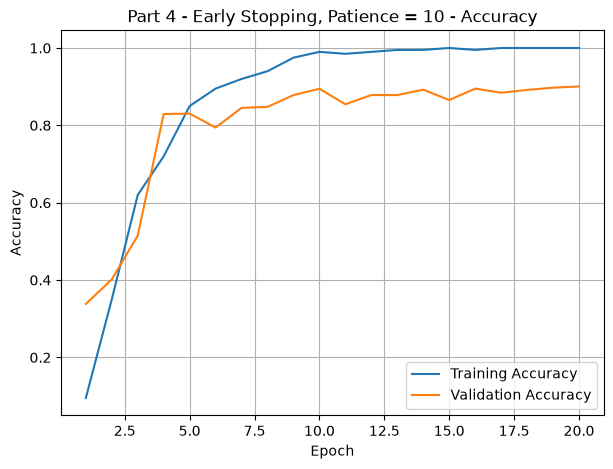

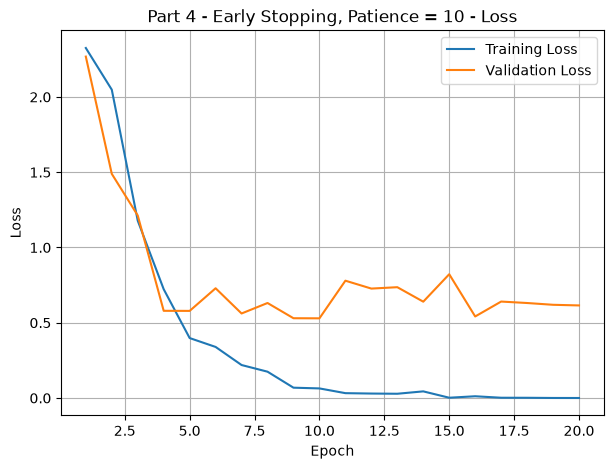

In [65]:
# 沿用範例的資料輸入流程，建立本次實驗的訓練資料集
early_stopping_train_ds = (
    tf.data.Dataset.from_tensor_slices((x_train, y_train))
    .shuffle(
        buffer_size=len(x_train),
        seed=2026,
        reshuffle_each_iteration=True
    )
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

# EPOCHS 是訓練上限；Early Stopping 可以在到達上限前停止
early_stopping_history = early_stopping_model.fit(
    early_stopping_train_ds,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    callbacks=[early_stopping_callback],
    verbose=2
)

# 從完整紀錄找出 Validation Loss 最低的 epoch
# np.argmin() 回傳從 0 開始的位置，所以加 1 轉成 epoch 編號
early_stopping_best_epoch = (
    int(np.argmin(early_stopping_history.history["val_loss"])) + 1
)

early_stopping_best_val_loss = float(
    early_stopping_history.history["val_loss"][
        early_stopping_best_epoch - 1
    ]
)

early_stopping_completed_epochs = len(
    early_stopping_history.history["loss"]
)

print("\n=== Part 4: Early Stopping Trial ===")
print(f"Patience: {EARLY_STOPPING_PATIENCE}")
print(f"Completed epochs: {early_stopping_completed_epochs}")

# callback 的 stopped_epoch 從 0 開始；
# 大於 0 代表這次有觸發提前停止。
if early_stopping_callback.stopped_epoch > 0:
    print(
        "Early Stopping triggered at epoch: "
        f"{early_stopping_callback.stopped_epoch + 1}"
    )
else:
    print("Early Stopping was not triggered.")

print(f"Best Validation Loss: {early_stopping_best_val_loss:.6f}")
print(f"Best Epoch: {early_stopping_best_epoch}")
print("Best validation loss weights restored by EarlyStopping.")

plot_history(
    early_stopping_history,
    title=f"Part 4 - Early Stopping, Patience = {EARLY_STOPPING_PATIENCE}"
)

## Part 4 early stopping 訓練流程 (patience = 5)

Epoch 1/100


2026-10-04 15:25:22.355623: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


7/7 - 5s - 671ms/step - accuracy: 0.0950 - loss: 2.3253 - val_accuracy: 0.3382 - val_loss: 2.2682
Epoch 2/100
7/7 - 3s - 494ms/step - accuracy: 0.3500 - loss: 2.0483 - val_accuracy: 0.4016 - val_loss: 1.4893
Epoch 3/100
7/7 - 3s - 487ms/step - accuracy: 0.6200 - loss: 1.1782 - val_accuracy: 0.5150 - val_loss: 1.2127
Epoch 4/100
7/7 - 3s - 483ms/step - accuracy: 0.7200 - loss: 0.7228 - val_accuracy: 0.8292 - val_loss: 0.5794
Epoch 5/100
7/7 - 3s - 476ms/step - accuracy: 0.8500 - loss: 0.3984 - val_accuracy: 0.8304 - val_loss: 0.5788
Epoch 6/100
7/7 - 3s - 485ms/step - accuracy: 0.8950 - loss: 0.3394 - val_accuracy: 0.7942 - val_loss: 0.7291
Epoch 7/100
7/7 - 3s - 482ms/step - accuracy: 0.9200 - loss: 0.2193 - val_accuracy: 0.8452 - val_loss: 0.5616
Epoch 8/100
7/7 - 3s - 486ms/step - accuracy: 0.9400 - loss: 0.1750 - val_accuracy: 0.8478 - val_loss: 0.6313
Epoch 9/100
7/7 - 3s - 490ms/step - accuracy: 0.9750 - loss: 0.0687 - val_accuracy: 0.8782 - val_loss: 0.5301
Epoch 10/100
7/7 - 3s 

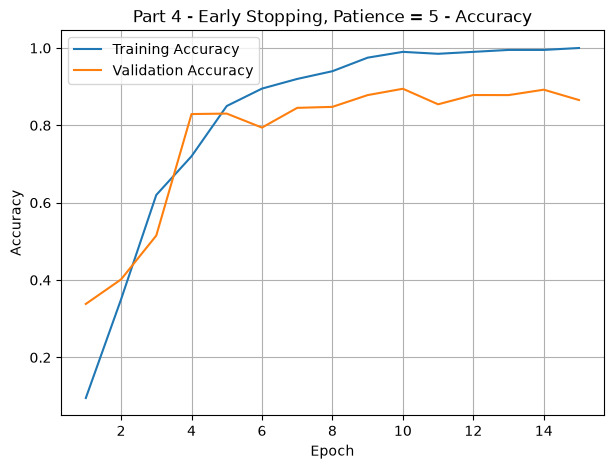

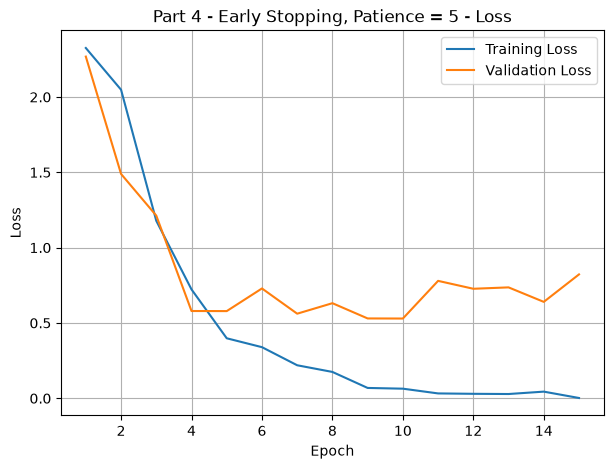

In [66]:
EARLY_STOPPING_PATIENCE_2 = 5

# 第二個實驗使用全新模型，從固定初始化重新開始
early_stopping_model_2 = create_early_stopping_model()

# 使用獨立的 callback，避免沿用第一個實驗的狀態
early_stopping_callback_2 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    mode="min",
    min_delta=0.0,
    patience=EARLY_STOPPING_PATIENCE_2,
    restore_best_weights=True,
    verbose=1
)

# 重新建立資料集，沿用相同的 shuffle 與 batch 設定
early_stopping_train_ds_2 = (
    tf.data.Dataset.from_tensor_slices((x_train, y_train))
    .shuffle(
        buffer_size=len(x_train),
        seed=2026,
        reshuffle_each_iteration=True
    )
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

early_stopping_history_2 = early_stopping_model_2.fit(
    early_stopping_train_ds_2,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    callbacks=[early_stopping_callback_2],
    verbose=2
)

early_stopping_best_epoch_2 = (
    int(np.argmin(early_stopping_history_2.history["val_loss"])) + 1
)

early_stopping_best_val_loss_2 = float(
    early_stopping_history_2.history["val_loss"][
        early_stopping_best_epoch_2 - 1
    ]
)

early_stopping_completed_epochs_2 = len(
    early_stopping_history_2.history["loss"]
)

print("\n=== Part 4: Early Stopping Trial 2 ===")
print(f"Patience: {EARLY_STOPPING_PATIENCE_2}")
print(f"Completed epochs: {early_stopping_completed_epochs_2}")

if early_stopping_callback_2.stopped_epoch > 0:
    print(
        "Early Stopping triggered at epoch: "
        f"{early_stopping_callback_2.stopped_epoch + 1}"
    )
else:
    print("Early Stopping was not triggered.")

print(f"Best Validation Loss: {early_stopping_best_val_loss_2:.6f}")
print(f"Best Epoch: {early_stopping_best_epoch_2}")
print("Best validation loss weights restored by EarlyStopping.")

plot_history(
    early_stopping_history_2,
    title=f"Part 4 - Early Stopping, Patience = {EARLY_STOPPING_PATIENCE_2}"
)

In [ ]:
# 優先比較最低 Validation Loss
# 若相同，再比較完成的 epoch 數，選擇訓練較短的實驗
is_early_stopping_trial_2_better = (
    early_stopping_best_val_loss_2 < early_stopping_best_val_loss
    or (
        early_stopping_best_val_loss_2 == early_stopping_best_val_loss
        and early_stopping_completed_epochs_2
        < early_stopping_completed_epochs
    )
)

early_stopping_selected_patience = (
    EARLY_STOPPING_PATIENCE_2
    if is_early_stopping_trial_2_better
    else EARLY_STOPPING_PATIENCE
)

early_stopping_selected_model = (
    early_stopping_model_2
    if is_early_stopping_trial_2_better
    else early_stopping_model
)

early_stopping_selected_history = (
    early_stopping_history_2
    if is_early_stopping_trial_2_better
    else early_stopping_history
)

early_stopping_selected_callback = (
    early_stopping_callback_2
    if is_early_stopping_trial_2_better
    else early_stopping_callback
)

early_stopping_selected_best_epoch = (
    early_stopping_best_epoch_2
    if is_early_stopping_trial_2_better
    else early_stopping_best_epoch
)

early_stopping_selected_best_val_loss = (
    early_stopping_best_val_loss_2
    if is_early_stopping_trial_2_better
    else early_stopping_best_val_loss
)

# 若沒有觸發 Early Stopping，以 None 表示。
early_stopping_selected_stop_epoch = (
    early_stopping_selected_callback.stopped_epoch + 1
    if early_stopping_selected_callback.stopped_epoch > 0
    else None
)

print(f"Selected Patience: {early_stopping_selected_patience}")

if early_stopping_selected_stop_epoch is not None:
    print(
        "Early Stopping triggered at epoch: "
        f"{early_stopping_selected_stop_epoch}"
    )
else:
    print("Early Stopping was not triggered.")

print(
    f"Best Validation Loss: "
    f"{early_stopping_selected_best_val_loss:.6f}"
)
print(f"Best Epoch: {early_stopping_selected_best_epoch}")

# 每個實驗的 callback 都已恢復該實驗最低 Validation Loss 時的權重
evaluate_model(
    "Part 4 - Early Stopping",
    early_stopping_selected_model,
    early_stopping_selected_history
)

results["Part 4 - Early Stopping"]["Patience"] = (
    early_stopping_selected_patience
)
results["Part 4 - Early Stopping"]["Stop Epoch"] = (
    early_stopping_selected_stop_epoch
)
results["Part 4 - Early Stopping"]["Best Validation Loss"] = (
    early_stopping_selected_best_val_loss
)
results["Part 4 - Early Stopping"]["Best Epoch"] = (
    early_stopping_selected_best_epoch
)

Selected Patience: 5
Early Stopping triggered at epoch: 15
Best Validation Loss: 0.529457
Best Epoch: 10


2026-10-04 15:32:09.381654: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


Part 4 - Early Stopping
Train Accuracy      : 0.9900
Validation Accuracy : 0.8946
Best Val Accuracy   : 0.8946
Test Accuracy       : 0.9064
Train-Val Gap       : 0.0954


## 本次實驗設計與結果

本 Part 按題目要求監控 `val_loss`，比較 patience 10 與 5，並由 EarlyStopping 還原最低 Validation Loss 的權重。兩組最低 Validation Loss 同為 0.529457，皆出現在 epoch 10，因此選擇訓練較短的 patience 5，於 epoch 15 觸發停止。還原後 Test Accuracy 為 90.64%；最低 Validation Loss 與最高 Validation Accuracy 的 epoch 不一定相同，因此此 Part 的選擇依據與其他 Part 有別。

# Part 5 — Batch Normalization

Batch Normalization 主要目的是改善 Neural Network 的 Training Stability 與 Convergence。

它會對 Intermediate Features 進行 Normalization，使不同 Layer 的輸入分布更加穩定。

常見流程為：

`Convolution`

↓

`Batch Normalization`

↓

`ReLU`

---

# Batch Normalization and Overfitting

需要注意：

**Batch Normalization 並不是專門為了解決 Overfitting 所提出的方法。**

它主要用於：

- 穩定 Training
- 改善 Gradient Flow
- 加速模型收斂
- 降低不同 Layer 之間 Distribution Shift 的影響

但由於 Batch Normalization 在 Training 時使用 Mini-Batch Statistics，因此有時也會產生一定程度的 Regularization Effect。

因此本實驗會觀察 Batch Normalization 是否對模型的 Generalization Performance 產生影響。

## Part 5 Betch Normalization 訓練流程 (BN_MOMENTUM = 0.99)

In [68]:
def create_batchnorm_model():
    # 建立全新的 baseline，取得範例的層設定與固定初始化。
    base_model = create_baseline_model()

    model = keras.Sequential([
        layers.Input(shape=(28, 28, 1))
    ])

    conv_index = 0

    for layer in base_model.layers:
        if isinstance(layer, layers.Conv2D):
            conv_index += 1

            # 保留原本的卷積設定，只將內建 ReLU 改成線性輸出。
            conv_config = layer.get_config() # 取得該層的設定
            conv_config["activation"] = "linear" # 讓卷積先輸出原始計算結果，把 ReLU 留到 BN 之後

            model.add(
                layers.Conv2D.from_config(conv_config) # 依修改後的設定建立新的卷積層
            )

            # 使用 Keras 預設的 momentum 與 epsilon。
            model.add(
                layers.BatchNormalization(
                    axis=-1,
                    momentum=0.99,
                    epsilon=0.001,
                    name=f"batchnorm_{conv_index}"
                )
            )

            # 在 Batch Normalization 之後執行 ReLU。
            model.add(
                layers.ReLU(name=f"relu_{conv_index}")
            )

        else:
            # Pooling、Flatten、Dense 依照範例順序加入。
            model.add(layer)

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


batchnorm_model = create_batchnorm_model()

batchnorm_model.summary()

print("Parameters:", batchnorm_model.count_params())
print(
    "Batch Normalization layers:",
    sum(
        isinstance(layer, layers.BatchNormalization)
        for layer in batchnorm_model.layers
    )
)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batchnorm_1                     │ (None, 28, 28, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_1 (ReLU)                   │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batchnorm_2                     │ (None, 28, 28, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_2 (ReLU)                   │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batchnorm_3                     │ (None, 14, 14, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_3 (ReLU)                   │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batchnorm_4                     │ (None, 14, 14, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_4 (ReLU)                   │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2048)           │    12,847,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1024)           │     2,098,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,735,754 (60.03 MB)

 Trainable params: 15,734,986 (60.02 MB)

 Non-trainable params: 768 (3.00 KB)

Parameters: 15735754
Batch Normalization layers: 4


Epoch 1/100


2026-10-04 15:54:03.678617: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


7/7 - 5s - 768ms/step - accuracy: 0.1200 - loss: 14.9074 - val_accuracy: 0.1858 - val_loss: 2.5541
Epoch 2/100
7/7 - 3s - 486ms/step - accuracy: 0.1550 - loss: 4.6529 - val_accuracy: 0.1000 - val_loss: 2.2625
Epoch 3/100
7/7 - 3s - 470ms/step - accuracy: 0.2000 - loss: 2.3187 - val_accuracy: 0.3128 - val_loss: 2.1282
Epoch 4/100
7/7 - 3s - 483ms/step - accuracy: 0.3500 - loss: 1.9271 - val_accuracy: 0.3668 - val_loss: 2.0049
Epoch 5/100
7/7 - 3s - 486ms/step - accuracy: 0.5150 - loss: 1.4200 - val_accuracy: 0.3756 - val_loss: 1.9918
Epoch 6/100
7/7 - 3s - 466ms/step - accuracy: 0.7000 - loss: 1.0979 - val_accuracy: 0.1514 - val_loss: 2.2601
Epoch 7/100
7/7 - 3s - 478ms/step - accuracy: 0.7500 - loss: 0.7663 - val_accuracy: 0.1252 - val_loss: 2.4827
Epoch 8/100
7/7 - 3s - 478ms/step - accuracy: 0.7950 - loss: 0.5976 - val_accuracy: 0.1286 - val_loss: 2.3518
Epoch 9/100
7/7 - 3s - 494ms/step - accuracy: 0.8550 - loss: 0.4734 - val_accuracy: 0.1188 - val_loss: 2.8478
Epoch 10/100
7/7 - 3s

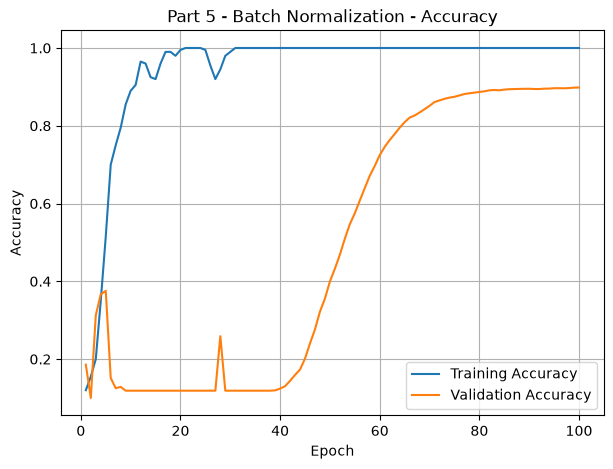

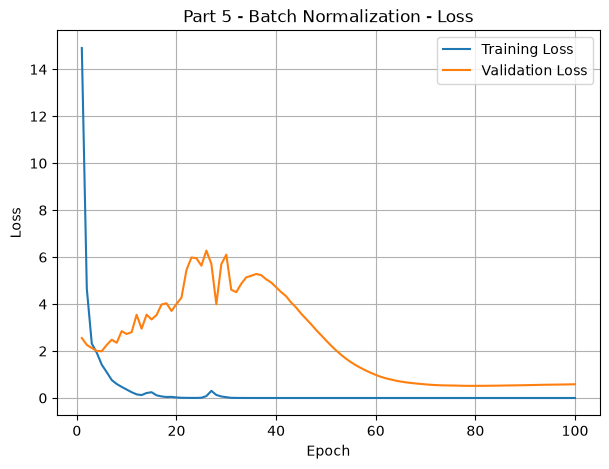

In [69]:
# 沿用範例的資料輸入流程，建立本次實驗的訓練資料集
batchnorm_train_ds = (
    tf.data.Dataset.from_tensor_slices((x_train, y_train))
    .shuffle(
        buffer_size=len(x_train),
        seed=2026,
        reshuffle_each_iteration=True
    )
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

# 記錄 Validation Accuracy 最高時的模型權重
batchnorm_best = BestValidationAccuracy()

batchnorm_history = batchnorm_model.fit(
    batchnorm_train_ds,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    callbacks=[batchnorm_best],
    verbose=2
)

# 恢復最佳驗證準確率時的完整模型權重與 BN 統計量
batchnorm_model.set_weights(
    batchnorm_best.best_weights
)

print("\n=== Part 5: Batch Normalization ===")
print(f"Completed epochs: {len(batchnorm_history.history['loss'])}")
print(f"Best Validation Accuracy: {batchnorm_best.best_accuracy:.2%}")
print(f"Best Epoch: {batchnorm_best.best_epoch}")
print("Best validation weights restored.")

plot_history(
    batchnorm_history,
    title="Part 5 - Batch Normalization"
)

## Part 5 Betch Normalization 訓練流程 (BN_MOMENTUM = 0.9)

In [ ]:
BN_MOMENTUM = 0.99
BN_MOMENTUM_2 = 0.9

# 為第二個實驗建立全新模型
batchnorm_model_2 = create_batchnorm_model()

# 在開始訓練前，設定新模型中四層 BN 的 momentum
for layer in batchnorm_model_2.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.momentum = BN_MOMENTUM_2

print("Parameters:", batchnorm_model_2.count_params())

for layer in batchnorm_model_2.layers:
    if isinstance(layer, layers.BatchNormalization):
        print(f"{layer.name}: momentum={layer.momentum}")

Parameters: 15735754
batchnorm_1: momentum=0.9
batchnorm_2: momentum=0.9
batchnorm_3: momentum=0.9
batchnorm_4: momentum=0.9


Epoch 1/100


2026-10-04 16:20:41.483585: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


7/7 - 6s - 823ms/step - accuracy: 0.1200 - loss: 14.9074 - val_accuracy: 0.1866 - val_loss: 4.1814
Epoch 2/100
7/7 - 4s - 518ms/step - accuracy: 0.1550 - loss: 4.6529 - val_accuracy: 0.0976 - val_loss: 2.6426
Epoch 3/100
7/7 - 4s - 541ms/step - accuracy: 0.2000 - loss: 2.3187 - val_accuracy: 0.1188 - val_loss: 2.7039
Epoch 4/100
7/7 - 3s - 493ms/step - accuracy: 0.3500 - loss: 1.9271 - val_accuracy: 0.1226 - val_loss: 2.5966
Epoch 5/100
7/7 - 3s - 481ms/step - accuracy: 0.5150 - loss: 1.4200 - val_accuracy: 0.2780 - val_loss: 2.0636
Epoch 6/100
7/7 - 3s - 484ms/step - accuracy: 0.7000 - loss: 1.0979 - val_accuracy: 0.3398 - val_loss: 1.8538
Epoch 7/100
7/7 - 4s - 614ms/step - accuracy: 0.7500 - loss: 0.7663 - val_accuracy: 0.5900 - val_loss: 1.2253
Epoch 8/100
7/7 - 4s - 533ms/step - accuracy: 0.7950 - loss: 0.5976 - val_accuracy: 0.7272 - val_loss: 0.8522
Epoch 9/100
7/7 - 4s - 525ms/step - accuracy: 0.8550 - loss: 0.4734 - val_accuracy: 0.7510 - val_loss: 0.7569
Epoch 10/100
7/7 - 4s

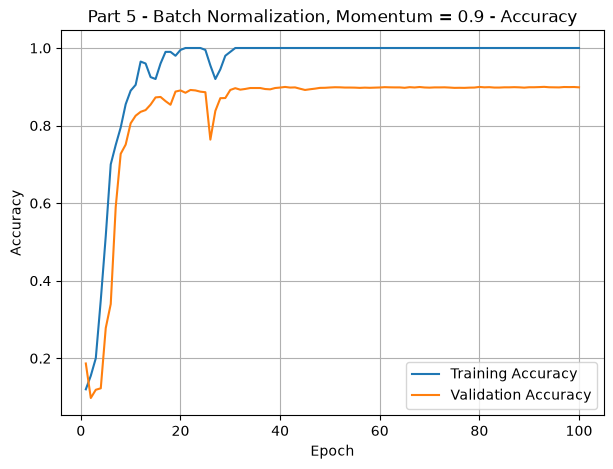

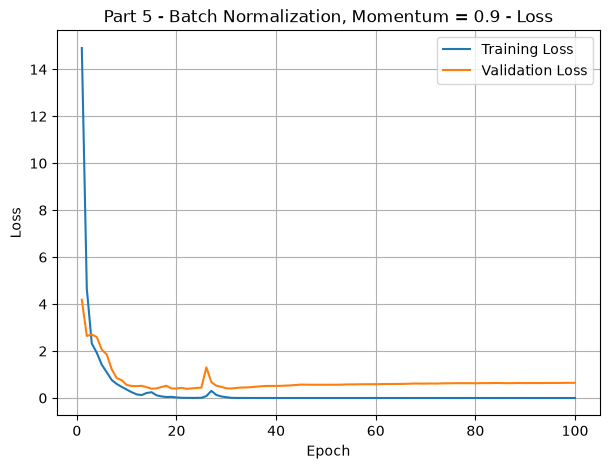

In [71]:
# 建立第二個實驗的資料集，使用相同的 shuffle 與 batch 設定
batchnorm_train_ds_2 = (
    tf.data.Dataset.from_tensor_slices((x_train, y_train))
    .shuffle(
        buffer_size=len(x_train),
        seed=2026,
        reshuffle_each_iteration=True
    )
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

# 使用獨立的 callback，記錄第二個實驗的最佳驗證準確率
batchnorm_best_2 = BestValidationAccuracy()

batchnorm_history_2 = batchnorm_model_2.fit(
    batchnorm_train_ds_2,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    callbacks=[batchnorm_best_2],
    verbose=2
)

# 恢復最佳 epoch 的權重，包括 BN 的移動平均與移動變異數
batchnorm_model_2.set_weights(
    batchnorm_best_2.best_weights
)

print("\n=== Part 5: Batch Normalization Trial 2 ===")
print(f"BN momentum: {BN_MOMENTUM_2}")
print(f"Completed epochs: {len(batchnorm_history_2.history['loss'])}")
print(f"Best Validation Accuracy: {batchnorm_best_2.best_accuracy:.2%}")
print(f"Best Epoch: {batchnorm_best_2.best_epoch}")
print("Best validation weights restored.")

plot_history(
    batchnorm_history_2,
    title=f"Part 5 - Batch Normalization, Momentum = {BN_MOMENTUM_2}"
)

In [72]:
# 依最佳 Validation Accuracy 選擇設定。
# 若相同，保留第一個實驗。
is_batchnorm_trial_2_better = (
    batchnorm_best_2.best_accuracy > batchnorm_best.best_accuracy
)

batchnorm_selected_momentum = (
    BN_MOMENTUM_2
    if is_batchnorm_trial_2_better
    else BN_MOMENTUM
)

batchnorm_selected_model = (
    batchnorm_model_2
    if is_batchnorm_trial_2_better
    else batchnorm_model
)

batchnorm_selected_history = (
    batchnorm_history_2
    if is_batchnorm_trial_2_better
    else batchnorm_history
)

batchnorm_selected_best = (
    batchnorm_best_2
    if is_batchnorm_trial_2_better
    else batchnorm_best
)

print(f"Selected BN momentum: {batchnorm_selected_momentum}")
print(f"Best Epoch: {batchnorm_selected_best.best_epoch}")
print(
    "Best Validation Accuracy: "
    f"{batchnorm_selected_best.best_accuracy:.2%}"
)

# 訓練 cell 已恢復各自的最佳權重與 BN 統計量，直接評估。
evaluate_model(
    "Part 5 - Batch Normalization",
    batchnorm_selected_model,
    batchnorm_selected_history
)

results["Part 5 - Batch Normalization"]["BN Momentum"] = (
    batchnorm_selected_momentum
)
results["Part 5 - Batch Normalization"]["Best Epoch"] = (
    batchnorm_selected_best.best_epoch
)

Selected BN momentum: 0.9
Best Epoch: 93
Best Validation Accuracy: 89.98%


2026-10-04 16:46:51.986485: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


Part 5 - Batch Normalization
Train Accuracy      : 1.0000
Validation Accuracy : 0.8998
Best Val Accuracy   : 0.8998
Test Accuracy       : 0.9132
Train-Val Gap       : 0.1002


## 本次實驗設計與結果

本 Part 在四個 Conv 後加入 Batch Normalization 與獨立 ReLU，維持老師原本每兩個 Conv 後才 Pooling 的架構，其餘層保持一致。本次比較 BN momentum 0.99 與 0.9，依最佳 Validation Accuracy 選擇 0.9，最佳驗證準確率為 89.98%，最佳 epoch 為 93，Test Accuracy 為 91.32%。Momentum 調整的是推論所用移動統計量的更新速度；本次 BN 設定未改善最終辨識準確率，因此 Part 6 的最終模型未採用 BN。程式使用 Keras 的 `fit()`、`evaluate()`，由框架自動切換訓練與推論行為。

# Part 6 — Combine Methods

前面五個 Part 都是「一次只加入一種方法」，藉此觀察每種方法各自的效果。

實務上，我們通常會同時使用多種方法。

在這個 Part，請你自行決定要組合哪些方法，並設計一個你認為最能減少 Overfitting 的模型。

可以使用的方法：

- L2 Regularization
- Dropout
- Data Augmentation
- Early Stopping
- Batch Normalization

可以參考前面 Part 1 ~ Part 5 的程式碼

## Trial 1 — Translation + Dropout 0.5 + Weight Decay

In [73]:
COMBINED_WEIGHT_DECAY = 1e-4
COMBINED_DROPOUT_RATE = 0.5
COMBINED_TRANSLATION_FACTOR = 0.1


def create_combined_model(
    weight_decay,
    dropout_rate,
    translation_factor
):
    # 從範例的固定初始化建立全新 baseline。
    base_model = create_baseline_model()

    # 在 CNN 前加入獨立的隨機平移層。
    model = keras.Sequential([
        layers.Input(shape=(28, 28, 1)),
        create_translation_augmentation(translation_factor)
    ])

    dropout_index = 0

    # 先加入輸出層之前的所有層。
    for layer in base_model.layers[:-1]:
        model.add(layer)

        # 在三層隱藏 Dense 的 ReLU 輸出後加入 Dropout。
        if isinstance(layer, layers.Dense):
            dropout_index += 1

            model.add(
                layers.Dropout(
                    rate=dropout_rate,
                    seed=3000 + dropout_index,
                    name=f"combined_dropout_{dropout_index}"
                )
            )

    # 最後加入原本的分類輸出層。
    model.add(base_model.layers[-1])

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=0.001,
            weight_decay=weight_decay
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


combined_model = create_combined_model(
    weight_decay=COMBINED_WEIGHT_DECAY,
    dropout_rate=COMBINED_DROPOUT_RATE,
    translation_factor=COMBINED_TRANSLATION_FACTOR
)

combined_model.summary()

print("Parameters:", combined_model.count_params())
print(f"Learning rate: {0.001:.4f}")
print(f"Weight decay: {COMBINED_WEIGHT_DECAY}")
print(f"Dropout rate: {COMBINED_DROPOUT_RATE}")
print(f"Translation factor: {COMBINED_TRANSLATION_FACTOR}")

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_translation              │ (None, 28, 28, 1)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2048)           │    12,847,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ combined_dropout_1 (Dropout)    │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1024)           │     2,098,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ combined_dropout_2 (Dropout)    │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ combined_dropout_3 (Dropout)    │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,734,218 (60.02 MB)

 Trainable params: 15,734,218 (60.02 MB)

 Non-trainable params: 0 (0.00 B)

Parameters: 15734218
Learning rate: 0.0010
Weight decay: 0.0001
Dropout rate: 0.5
Translation factor: 0.1


Epoch 1/100


2026-10-04 16:51:54.633555: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


7/7 - 5s - 693ms/step - accuracy: 0.0750 - loss: 2.3376 - val_accuracy: 0.0974 - val_loss: 2.3014
Epoch 2/100
7/7 - 3s - 455ms/step - accuracy: 0.1050 - loss: 2.3000 - val_accuracy: 0.0974 - val_loss: 2.2950
Epoch 3/100
7/7 - 3s - 475ms/step - accuracy: 0.1000 - loss: 2.3111 - val_accuracy: 0.1024 - val_loss: 2.2960
Epoch 4/100
7/7 - 3s - 454ms/step - accuracy: 0.0850 - loss: 2.3002 - val_accuracy: 0.1022 - val_loss: 2.2881
Epoch 5/100
7/7 - 3s - 478ms/step - accuracy: 0.0900 - loss: 2.2895 - val_accuracy: 0.1022 - val_loss: 2.2544
Epoch 6/100
7/7 - 3s - 485ms/step - accuracy: 0.1450 - loss: 2.2678 - val_accuracy: 0.1790 - val_loss: 2.2034
Epoch 7/100
7/7 - 3s - 482ms/step - accuracy: 0.1700 - loss: 2.2054 - val_accuracy: 0.4622 - val_loss: 2.1344
Epoch 8/100
7/7 - 3s - 458ms/step - accuracy: 0.2700 - loss: 2.0769 - val_accuracy: 0.5170 - val_loss: 1.6503
Epoch 9/100
7/7 - 3s - 463ms/step - accuracy: 0.3250 - loss: 1.8422 - val_accuracy: 0.6760 - val_loss: 1.3835
Epoch 10/100
7/7 - 3s 

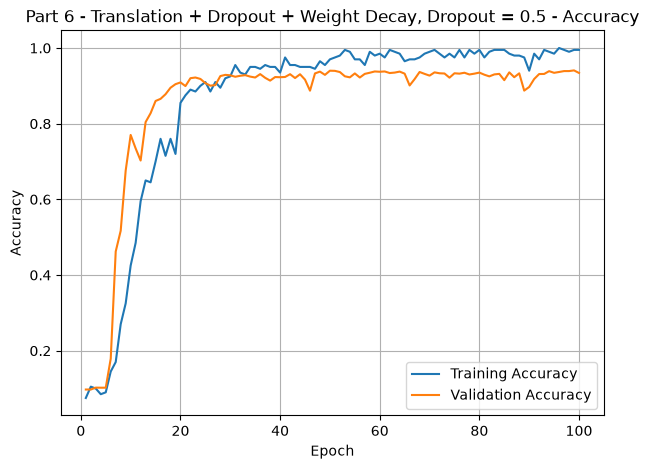

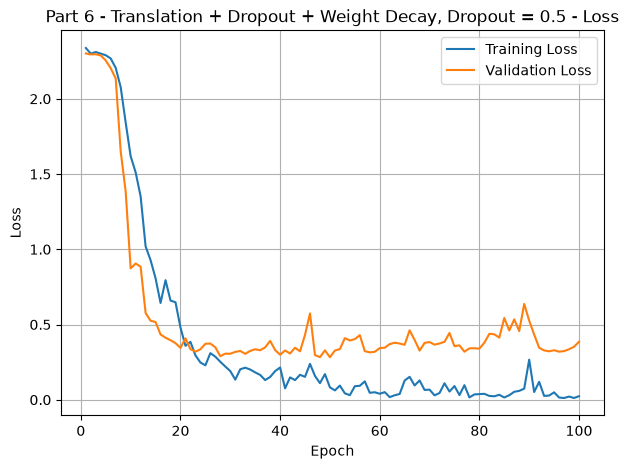

In [74]:
# 沿用範例的資料流程。
# Translation 已放在模型內，因此資料集不需要另外做增強。
combined_train_ds = (
    tf.data.Dataset.from_tensor_slices((x_train, y_train))
    .shuffle(
        buffer_size=len(x_train),
        seed=2026,
        reshuffle_each_iteration=True
    )
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

# 記錄組合模型的最佳 Validation Accuracy 與對應權重。
combined_best = BestValidationAccuracy()

combined_history = combined_model.fit(
    combined_train_ds,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    callbacks=[combined_best],
    verbose=2
)

# 恢復最佳驗證準確率時的權重。
combined_model.set_weights(
    combined_best.best_weights
)

print("\n=== Part 6: Combined Methods Trial 1 ===")
print(f"Weight decay: {COMBINED_WEIGHT_DECAY}")
print(f"Dropout rate: {COMBINED_DROPOUT_RATE}")
print(f"Translation factor: {COMBINED_TRANSLATION_FACTOR}")
print(f"Completed epochs: {len(combined_history.history['loss'])}")
print(f"Best Validation Accuracy: {combined_best.best_accuracy:.2%}")
print(f"Best Epoch: {combined_best.best_epoch}")
print("Best validation weights restored.")

plot_history(
    combined_history,
    title=(
        "Part 6 - Translation + Dropout + Weight Decay"
        f", Dropout = {COMBINED_DROPOUT_RATE}"
    )
)

## Trial 2 — Dropout 0.2

In [75]:
COMBINED_WEIGHT_DECAY_2 = COMBINED_WEIGHT_DECAY
COMBINED_DROPOUT_RATE_2 = 0.2
COMBINED_TRANSLATION_FACTOR_2 = COMBINED_TRANSLATION_FACTOR

# 從固定初始化建立第二個獨立模型。
combined_model_2 = create_combined_model(
    weight_decay=COMBINED_WEIGHT_DECAY_2,
    dropout_rate=COMBINED_DROPOUT_RATE_2,
    translation_factor=COMBINED_TRANSLATION_FACTOR_2
)

combined_model_2.summary()

print("Parameters:", combined_model_2.count_params())
print(f"Weight decay: {COMBINED_WEIGHT_DECAY_2}")
print(f"Dropout rate: {COMBINED_DROPOUT_RATE_2}")
print(f"Translation factor: {COMBINED_TRANSLATION_FACTOR_2}")

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_translation              │ (None, 28, 28, 1)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2048)           │    12,847,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ combined_dropout_1 (Dropout)    │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1024)           │     2,098,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ combined_dropout_2 (Dropout)    │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ combined_dropout_3 (Dropout)    │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,734,218 (60.02 MB)

 Trainable params: 15,734,218 (60.02 MB)

 Non-trainable params: 0 (0.00 B)

Parameters: 15734218
Weight decay: 0.0001
Dropout rate: 0.2
Translation factor: 0.1


Epoch 1/100


2026-10-04 17:06:26.161430: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


7/7 - 6s - 791ms/step - accuracy: 0.0600 - loss: 2.3333 - val_accuracy: 0.1680 - val_loss: 2.2983
Epoch 2/100
7/7 - 3s - 474ms/step - accuracy: 0.1350 - loss: 2.2909 - val_accuracy: 0.0976 - val_loss: 2.2854
Epoch 3/100
7/7 - 3s - 473ms/step - accuracy: 0.1600 - loss: 2.2810 - val_accuracy: 0.1836 - val_loss: 2.2362
Epoch 4/100
7/7 - 3s - 462ms/step - accuracy: 0.2150 - loss: 2.1736 - val_accuracy: 0.4730 - val_loss: 1.6265
Epoch 5/100
7/7 - 3s - 489ms/step - accuracy: 0.4250 - loss: 1.6272 - val_accuracy: 0.5492 - val_loss: 1.2748
Epoch 6/100
7/7 - 3s - 478ms/step - accuracy: 0.5400 - loss: 1.3116 - val_accuracy: 0.6678 - val_loss: 0.9649
Epoch 7/100
7/7 - 4s - 534ms/step - accuracy: 0.6150 - loss: 0.9548 - val_accuracy: 0.8214 - val_loss: 0.5795
Epoch 8/100
7/7 - 4s - 505ms/step - accuracy: 0.7400 - loss: 0.7778 - val_accuracy: 0.8034 - val_loss: 0.5851
Epoch 9/100
7/7 - 3s - 491ms/step - accuracy: 0.7550 - loss: 0.6595 - val_accuracy: 0.8694 - val_loss: 0.4281
Epoch 10/100
7/7 - 4s 

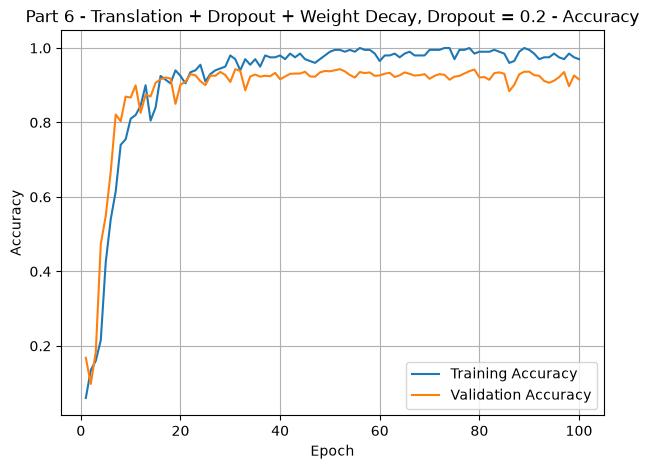

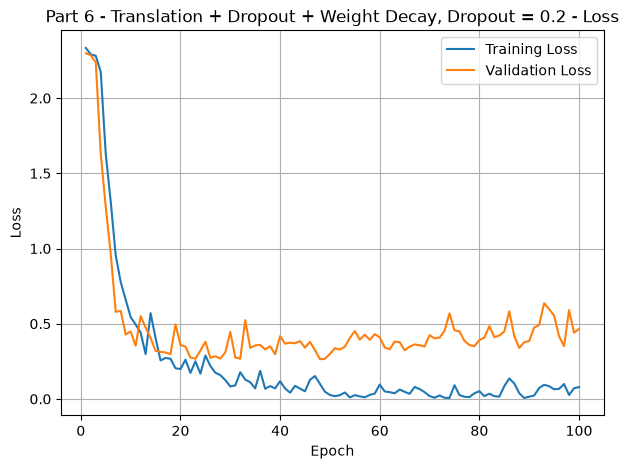

In [76]:
# 建立第二個組合的資料集，沿用相同的 shuffle 與 batch 設定。
combined_train_ds_2 = (
    tf.data.Dataset.from_tensor_slices((x_train, y_train))
    .shuffle(
        buffer_size=len(x_train),
        seed=2026,
        reshuffle_each_iteration=True
    )
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

# 獨立記錄第二個組合的最佳驗證準確率。
combined_best_2 = BestValidationAccuracy()

combined_history_2 = combined_model_2.fit(
    combined_train_ds_2,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    callbacks=[combined_best_2],
    verbose=2
)

# 恢復最佳驗證準確率時的權重。
combined_model_2.set_weights(
    combined_best_2.best_weights
)

print("\n=== Part 6: Combined Methods Trial 2 ===")
print(f"Weight decay: {COMBINED_WEIGHT_DECAY_2}")
print(f"Dropout rate: {COMBINED_DROPOUT_RATE_2}")
print(f"Translation factor: {COMBINED_TRANSLATION_FACTOR_2}")
print(f"Completed epochs: {len(combined_history_2.history['loss'])}")
print(f"Best Validation Accuracy: {combined_best_2.best_accuracy:.2%}")
print(f"Best Epoch: {combined_best_2.best_epoch}")
print("Best validation weights restored.")

plot_history(
    combined_history_2,
    title=(
        "Part 6 - Translation + Dropout + Weight Decay"
        f", Dropout = {COMBINED_DROPOUT_RATE_2}"
    )
)

## Trial 3 — Early Stopping 對照

In [ ]:
COMBINED_WEIGHT_DECAY_3 = 1e-4
COMBINED_DROPOUT_RATE_3 = 0.2
COMBINED_TRANSLATION_FACTOR_3 = 0.1
COMBINED_PATIENCE_3 = 10

# 建立全新對照模型，使用相同的固定初始化
combined_model_3 = create_combined_model(
    weight_decay=COMBINED_WEIGHT_DECAY_3,
    dropout_rate=COMBINED_DROPOUT_RATE_3,
    translation_factor=COMBINED_TRANSLATION_FACTOR_3
)

# Part 6 依 Validation Accuracy 決定停止與恢復權重
combined_early_stopping_3 = keras.callbacks.EarlyStopping(
    monitor="val_accuracy",
    mode="max",
    min_delta=0.0,
    patience=COMBINED_PATIENCE_3,
    restore_best_weights=True,
    verbose=1
)

print("Parameters:", combined_model_3.count_params())
print(f"Weight decay: {COMBINED_WEIGHT_DECAY_3}")
print(f"Dropout rate: {COMBINED_DROPOUT_RATE_3}")
print(f"Translation factor: {COMBINED_TRANSLATION_FACTOR_3}")
print("Early Stopping monitor:", combined_early_stopping_3.monitor)
print("Patience:", COMBINED_PATIENCE_3)

Parameters: 15734218
Weight decay: 0.0001
Dropout rate: 0.2
Translation factor: 0.1
Early Stopping monitor: val_accuracy
Patience: 10


Epoch 1/100


2026-10-04 17:29:47.718275: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


7/7 - 5s - 739ms/step - accuracy: 0.0600 - loss: 2.3333 - val_accuracy: 0.1680 - val_loss: 2.2983
Epoch 2/100
7/7 - 3s - 473ms/step - accuracy: 0.1350 - loss: 2.2909 - val_accuracy: 0.0976 - val_loss: 2.2854
Epoch 3/100
7/7 - 3s - 496ms/step - accuracy: 0.1600 - loss: 2.2810 - val_accuracy: 0.1836 - val_loss: 2.2362
Epoch 4/100
7/7 - 3s - 494ms/step - accuracy: 0.2150 - loss: 2.1736 - val_accuracy: 0.4730 - val_loss: 1.6265
Epoch 5/100
7/7 - 3s - 472ms/step - accuracy: 0.4250 - loss: 1.6272 - val_accuracy: 0.5492 - val_loss: 1.2748
Epoch 6/100
7/7 - 3s - 475ms/step - accuracy: 0.5400 - loss: 1.3116 - val_accuracy: 0.6678 - val_loss: 0.9649
Epoch 7/100
7/7 - 3s - 475ms/step - accuracy: 0.6150 - loss: 0.9548 - val_accuracy: 0.8214 - val_loss: 0.5795
Epoch 8/100
7/7 - 3s - 465ms/step - accuracy: 0.7400 - loss: 0.7778 - val_accuracy: 0.8034 - val_loss: 0.5851
Epoch 9/100
7/7 - 3s - 468ms/step - accuracy: 0.7550 - loss: 0.6595 - val_accuracy: 0.8694 - val_loss: 0.4281
Epoch 10/100
7/7 - 3s 

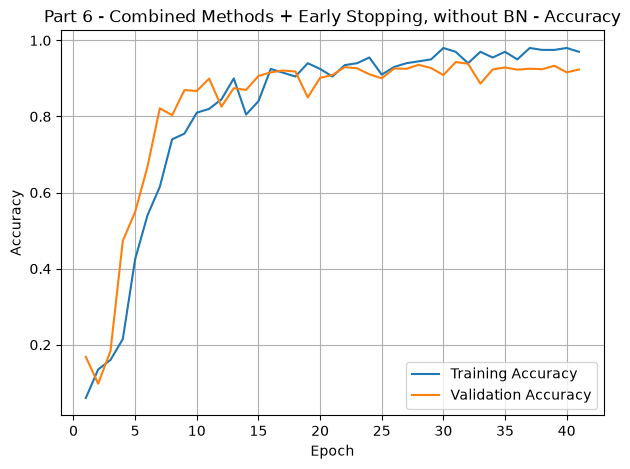

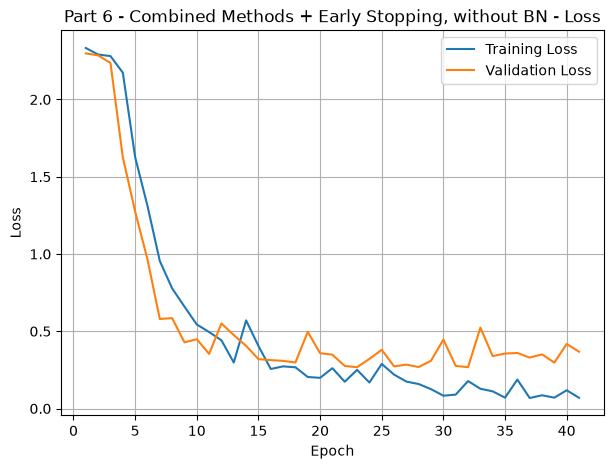

In [79]:
# 建立本次對照實驗的資料集，沿用相同的資料流程
combined_train_ds_3 = (
    tf.data.Dataset.from_tensor_slices((x_train, y_train))
    .shuffle(
        buffer_size=len(x_train),
        seed=2026,
        reshuffle_each_iteration=True
    )
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

# 記錄最佳驗證準確率與 epoch，供後續實驗比較
combined_best_3 = BestValidationAccuracy()

combined_history_3 = combined_model_3.fit(
    combined_train_ds_3,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    callbacks=[
        combined_best_3,
        combined_early_stopping_3
    ],
    verbose=2
)

print("\n=== Part 6: Combined Methods Trial 3 ===")
print(f"Weight decay: {COMBINED_WEIGHT_DECAY_3}")
print(f"Dropout rate: {COMBINED_DROPOUT_RATE_3}")
print(f"Translation factor: {COMBINED_TRANSLATION_FACTOR_3}")
print(f"Patience: {COMBINED_PATIENCE_3}")
print(f"Completed epochs: {len(combined_history_3.history['loss'])}")

if combined_early_stopping_3.stopped_epoch > 0:
    print(
        "Early Stopping triggered at epoch: "
        f"{combined_early_stopping_3.stopped_epoch + 1}"
    )
else:
    print("Early Stopping was not triggered.")

print(f"Best Validation Accuracy: {combined_best_3.best_accuracy:.2%}")
print(f"Best Epoch: {combined_best_3.best_epoch}")
print("Best validation accuracy weights restored by EarlyStopping.")

plot_history(
    combined_history_3,
    title="Part 6 - Combined Methods + Early Stopping, without BN"
)

## Trial 4 — 加入 BN，完整 100 epochs

In [89]:
COMBINED_WEIGHT_DECAY_4 = COMBINED_WEIGHT_DECAY_3
COMBINED_DROPOUT_RATE_4 = COMBINED_DROPOUT_RATE_3
COMBINED_TRANSLATION_FACTOR_4 = COMBINED_TRANSLATION_FACTOR_3
COMBINED_BN_MOMENTUM_4 = 0.9


def create_combined_batchnorm_model(
    weight_decay,
    dropout_rate,
    translation_factor,
    bn_momentum
):
    # 建立全新的組合模型，取得其層設定與固定初始化
    base_model = create_combined_model(
        weight_decay=weight_decay,
        dropout_rate=dropout_rate,
        translation_factor=translation_factor
    )

    model = keras.Sequential([
        layers.Input(shape=(28, 28, 1))
    ])

    conv_index = 0

    for layer in base_model.layers:
        if isinstance(layer, layers.Conv2D):
            conv_index += 1

            # 將原本 Conv 內建的 ReLU 拆出，改成 Conv → BN → ReLU
            conv_config = layer.get_config()
            conv_config["activation"] = "linear"

            model.add(
                layers.Conv2D.from_config(conv_config)
            )

            model.add(
                layers.BatchNormalization(
                    axis=-1,
                    momentum=bn_momentum,
                    epsilon=0.001,
                    name=f"combined_batchnorm_{conv_index}"
                )
            )

            model.add(
                layers.ReLU(
                    name=f"combined_relu_{conv_index}"
                )
            )

        else:
            # 沿用 Translation、Pooling、Flatten、Dense 與 Dropout
            model.add(layer)

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=0.001,
            weight_decay=weight_decay
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


combined_model_4 = create_combined_batchnorm_model(
    weight_decay=COMBINED_WEIGHT_DECAY_4,
    dropout_rate=COMBINED_DROPOUT_RATE_4,
    translation_factor=COMBINED_TRANSLATION_FACTOR_4,
    bn_momentum=COMBINED_BN_MOMENTUM_4
)

combined_model_4.summary()

print("Parameters:", combined_model_4.count_params())
print(f"Weight decay: {COMBINED_WEIGHT_DECAY_4}")
print(f"Dropout rate: {COMBINED_DROPOUT_RATE_4}")
print(f"Translation factor: {COMBINED_TRANSLATION_FACTOR_4}")
print(f"BN momentum: {COMBINED_BN_MOMENTUM_4}")
print(
    "Batch Normalization layers:",
    sum(
        isinstance(layer, layers.BatchNormalization)
        for layer in combined_model_4.layers
    )
)

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_translation              │ (None, 28, 28, 1)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ combined_batchnorm_1            │ (None, 28, 28, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ combined_relu_1 (ReLU)          │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ combined_batchnorm_2            │ (None, 28, 28, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ combined_relu_2 (ReLU)          │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ combined_batchnorm_3            │ (None, 14, 14, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ combined_relu_3 (ReLU)          │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ combined_batchnorm_4            │ (None, 14, 14, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ combined_relu_4 (ReLU)          │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2048)           │    12,847,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ combined_dropout_1 (Dropout)    │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1024)           │     2,098,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ combined_dropout_2 (Dropout)    │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ combined_dropout_3 (Dropout)    │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 15,735,754 (60.03 MB)

 Trainable params: 15,734,986 (60.02 MB)

 Non-trainable params: 768 (3.00 KB)

Parameters: 15735754
Weight decay: 0.0001
Dropout rate: 0.2
Translation factor: 0.1
BN momentum: 0.9
Batch Normalization layers: 4


Epoch 1/100


2026-10-04 18:29:08.259051: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


7/7 - 6s - 892ms/step - accuracy: 0.0850 - loss: 12.9929 - val_accuracy: 0.0974 - val_loss: 3.4837
Epoch 2/100
7/7 - 4s - 577ms/step - accuracy: 0.1300 - loss: 5.5173 - val_accuracy: 0.0928 - val_loss: 2.6510
Epoch 3/100
7/7 - 4s - 548ms/step - accuracy: 0.1100 - loss: 2.7079 - val_accuracy: 0.1188 - val_loss: 2.4727
Epoch 4/100
7/7 - 4s - 595ms/step - accuracy: 0.1500 - loss: 2.4716 - val_accuracy: 0.1234 - val_loss: 2.3848
Epoch 5/100
7/7 - 4s - 592ms/step - accuracy: 0.1600 - loss: 2.2266 - val_accuracy: 0.1268 - val_loss: 2.4222
Epoch 6/100
7/7 - 4s - 571ms/step - accuracy: 0.2800 - loss: 2.0617 - val_accuracy: 0.1536 - val_loss: 2.4142
Epoch 7/100
7/7 - 4s - 605ms/step - accuracy: 0.3250 - loss: 1.8636 - val_accuracy: 0.2160 - val_loss: 2.2209
Epoch 8/100
7/7 - 6s - 852ms/step - accuracy: 0.3950 - loss: 1.6914 - val_accuracy: 0.3916 - val_loss: 1.7226
Epoch 9/100
7/7 - 4s - 624ms/step - accuracy: 0.4700 - loss: 1.4678 - val_accuracy: 0.4008 - val_loss: 1.8666
Epoch 10/100
7/7 - 4s

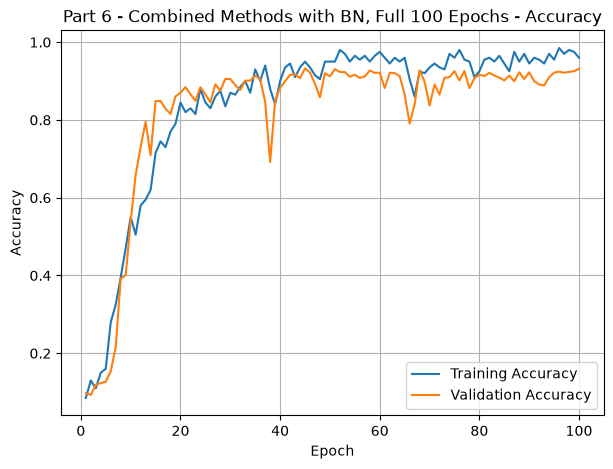

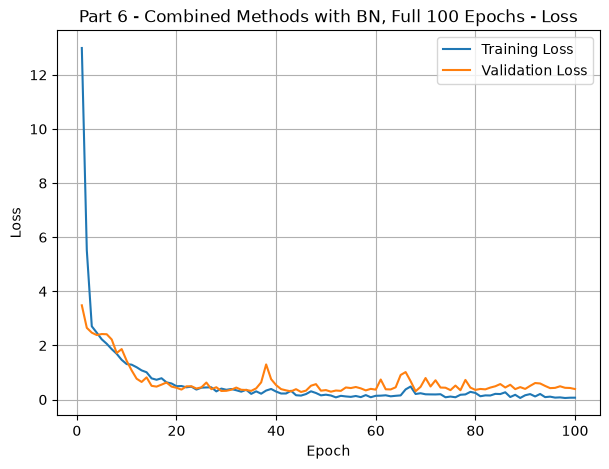

In [90]:
# 重新建立資料集，使用相同的 shuffle 與 batch 設定。
combined_train_ds_4 = (
    tf.data.Dataset.from_tensor_slices((x_train, y_train))
    .shuffle(
        buffer_size=len(x_train),
        seed=2026,
        reshuffle_each_iteration=True
    )
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

# 記錄最佳驗證準確率，但不提前停止訓練。
combined_best_4 = BestValidationAccuracy()

combined_history_4 = combined_model_4.fit(
    combined_train_ds_4,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    callbacks=[combined_best_4],
    verbose=2
)

# 恢復最佳 epoch 的權重，包含 BN 的移動統計量。
combined_model_4.set_weights(
    combined_best_4.best_weights
)

print("\n=== Part 6: Combined Methods Trial 4, Full Training with BN ===")
print(f"Weight decay: {COMBINED_WEIGHT_DECAY_4}")
print(f"Dropout rate: {COMBINED_DROPOUT_RATE_4}")
print(f"Translation factor: {COMBINED_TRANSLATION_FACTOR_4}")
print(f"BN momentum: {COMBINED_BN_MOMENTUM_4}")
print("Early Stopping: disabled")
print(f"Completed epochs: {len(combined_history_4.history['loss'])}")
print(f"Best Validation Accuracy: {combined_best_4.best_accuracy:.2%}")
print(f"Best Epoch: {combined_best_4.best_epoch}")
print("Best validation weights and BN statistics restored.")

plot_history(
    combined_history_4,
    title="Part 6 - Combined Methods with BN, Full 100 Epochs"
)

In [91]:
bn_completed_epochs = len(combined_history_4.history["loss"])
bn_batches_per_epoch = int(np.ceil(len(x_train) / BATCH_SIZE))
bn_expected_updates = bn_completed_epochs * bn_batches_per_epoch

bn_actual_updates = int(
    combined_model_4.optimizer.iterations.numpy()
)

print("Completed epochs:", bn_completed_epochs)
print("Batches per epoch:", bn_batches_per_epoch)
print("Expected updates for a fresh model:", bn_expected_updates)
print("Actual optimizer updates:", bn_actual_updates)

Completed epochs: 100
Batches per epoch: 7
Expected updates for a fresh model: 700
Actual optimizer updates: 700


## Trial 5 — Translation 0.15

Augmentation method: RandomTranslation
Height factor: ±15%
Width factor: ±15%
Fill mode: constant; fill value: 0.0
Interpolation: bilinear


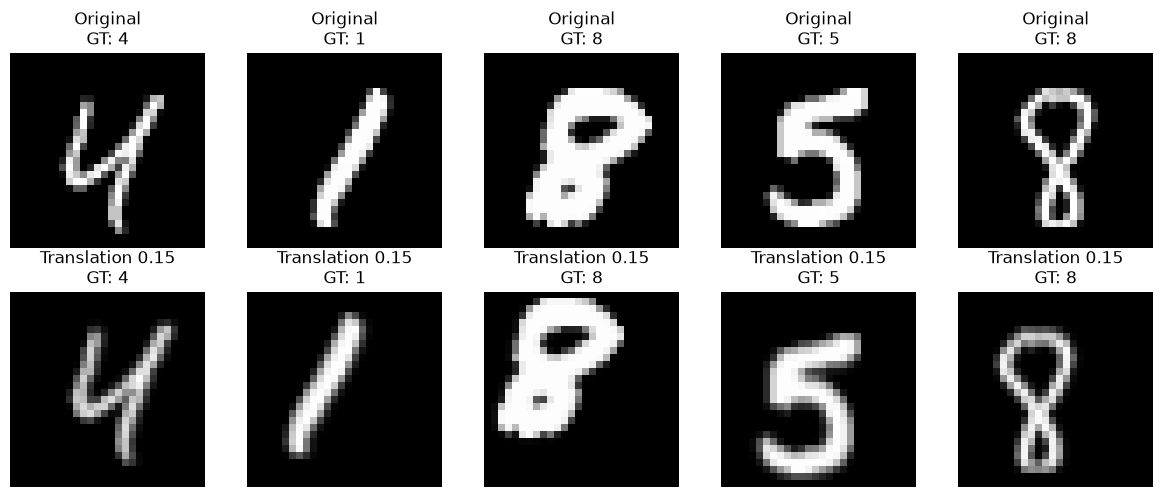

In [82]:
COMBINED_WEIGHT_DECAY_5 = COMBINED_WEIGHT_DECAY_3
COMBINED_DROPOUT_RATE_5 = COMBINED_DROPOUT_RATE_3
COMBINED_TRANSLATION_FACTOR_5 = 0.15
COMBINED_PATIENCE_5 = COMBINED_PATIENCE_3

# 預覽使用獨立的增強層。
# 後續訓練模型會另外建立自己的增強層。
preview_augmentation_5 = create_translation_augmentation(
    COMBINED_TRANSLATION_FACTOR_5
)

preview_images_5 = preview_augmentation_5(
    x_train[preview_indices],
    training=True
).numpy()

print("Augmentation method: RandomTranslation")
print(f"Height factor: ±{COMBINED_TRANSLATION_FACTOR_5:.0%}")
print(f"Width factor: ±{COMBINED_TRANSLATION_FACTOR_5:.0%}")
print("Fill mode: constant; fill value: 0.0")
print("Interpolation: bilinear")

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for column, sample_index in enumerate(preview_indices):
    label = int(y_train[sample_index])

    axes[0, column].imshow(
        x_train[sample_index, :, :, 0],
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[0, column].set_title(f"Original\nGT: {label}")
    axes[0, column].axis("off")

    axes[1, column].imshow(
        preview_images_5[column, :, :, 0],
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[1, column].set_title(f"Translation 0.15\nGT: {label}")
    axes[1, column].axis("off")

plt.tight_layout()
plt.show()

In [85]:
# 重新建立全新模型，從固定初始化開始
combined_model_5 = create_combined_model(
    weight_decay=COMBINED_WEIGHT_DECAY_5,
    dropout_rate=COMBINED_DROPOUT_RATE_5,
    translation_factor=COMBINED_TRANSLATION_FACTOR_5
)

combined_model_5.summary()

print("Parameters:", combined_model_5.count_params())
print(f"Weight decay: {COMBINED_WEIGHT_DECAY_5}")
print(f"Dropout rate: {COMBINED_DROPOUT_RATE_5}")
print(f"Translation factor: {COMBINED_TRANSLATION_FACTOR_5}")
print("Early Stopping: disabled")

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_translation              │ (None, 28, 28, 1)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2048)           │    12,847,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ combined_dropout_1 (Dropout)    │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1024)           │     2,098,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ combined_dropout_2 (Dropout)    │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ combined_dropout_3 (Dropout)    │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,734,218 (60.02 MB)

 Trainable params: 15,734,218 (60.02 MB)

 Non-trainable params: 0 (0.00 B)

Parameters: 15734218
Weight decay: 0.0001
Dropout rate: 0.2
Translation factor: 0.15
Early Stopping: disabled


Epoch 1/100


2026-10-04 17:51:08.183150: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


7/7 - 5s - 761ms/step - accuracy: 0.0500 - loss: 2.3355 - val_accuracy: 0.0956 - val_loss: 2.3008
Epoch 2/100
7/7 - 3s - 481ms/step - accuracy: 0.0850 - loss: 2.2983 - val_accuracy: 0.0974 - val_loss: 2.2924
Epoch 3/100
7/7 - 3s - 470ms/step - accuracy: 0.1200 - loss: 2.2907 - val_accuracy: 0.3268 - val_loss: 2.2760
Epoch 4/100
7/7 - 3s - 499ms/step - accuracy: 0.1000 - loss: 2.2566 - val_accuracy: 0.1420 - val_loss: 2.1617
Epoch 5/100
7/7 - 3s - 475ms/step - accuracy: 0.2550 - loss: 2.1007 - val_accuracy: 0.4620 - val_loss: 1.6151
Epoch 6/100
7/7 - 3s - 461ms/step - accuracy: 0.3650 - loss: 1.7488 - val_accuracy: 0.4302 - val_loss: 1.5909
Epoch 7/100
7/7 - 3s - 461ms/step - accuracy: 0.4100 - loss: 1.6258 - val_accuracy: 0.6116 - val_loss: 1.1147
Epoch 8/100
7/7 - 3s - 469ms/step - accuracy: 0.5050 - loss: 1.2885 - val_accuracy: 0.7546 - val_loss: 0.8145
Epoch 9/100
7/7 - 3s - 491ms/step - accuracy: 0.5700 - loss: 1.0926 - val_accuracy: 0.6994 - val_loss: 0.8158
Epoch 10/100
7/7 - 3s 

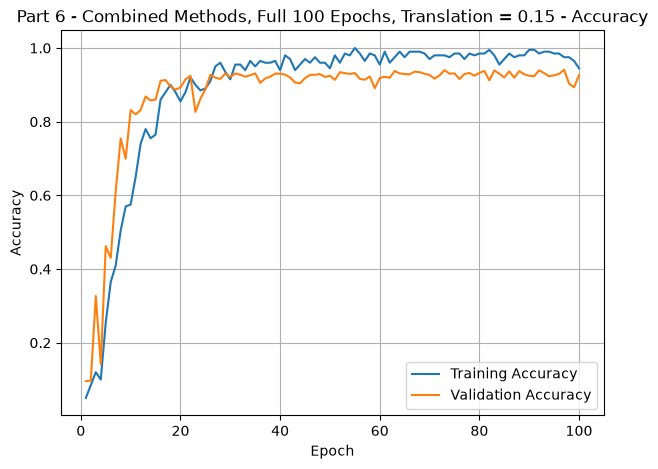

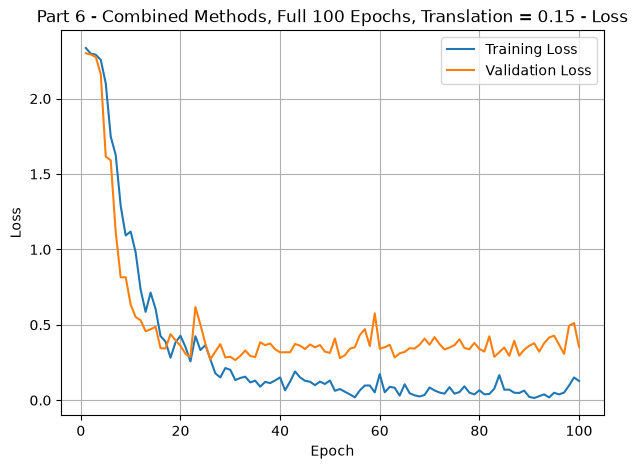

In [86]:
# 重新建立資料集，從相同的 shuffle 狀態開始。
combined_train_ds_5 = (
    tf.data.Dataset.from_tensor_slices((x_train, y_train))
    .shuffle(
        buffer_size=len(x_train),
        seed=2026,
        reshuffle_each_iteration=True
    )
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

# 記錄最佳驗證準確率，但不提前停止訓練。
combined_best_5 = BestValidationAccuracy()

combined_history_5 = combined_model_5.fit(
    combined_train_ds_5,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    callbacks=[combined_best_5],
    verbose=2
)

# 完整訓練後，恢復最高 Validation Accuracy 時的權重。
combined_model_5.set_weights(
    combined_best_5.best_weights
)

print("\n=== Part 6: Combined Methods Trial 5, Full Training ===")
print(f"Weight decay: {COMBINED_WEIGHT_DECAY_5}")
print(f"Dropout rate: {COMBINED_DROPOUT_RATE_5}")
print(f"Translation factor: {COMBINED_TRANSLATION_FACTOR_5}")
print("Early Stopping: disabled")
print(f"Completed epochs: {len(combined_history_5.history['loss'])}")
print(f"Best Validation Accuracy: {combined_best_5.best_accuracy:.2%}")
print(f"Best Epoch: {combined_best_5.best_epoch}")
print("Best validation weights restored.")

plot_history(
    combined_history_5,
    title=(
        "Part 6 - Combined Methods, Full 100 Epochs"
        f", Translation = {COMBINED_TRANSLATION_FACTOR_5}"
    )
)

## Trial 6 — Translation 0.2

Augmentation method: RandomTranslation
Height factor: ±20%
Width factor: ±20%
Fill mode: constant; fill value: 0.0
Interpolation: bilinear


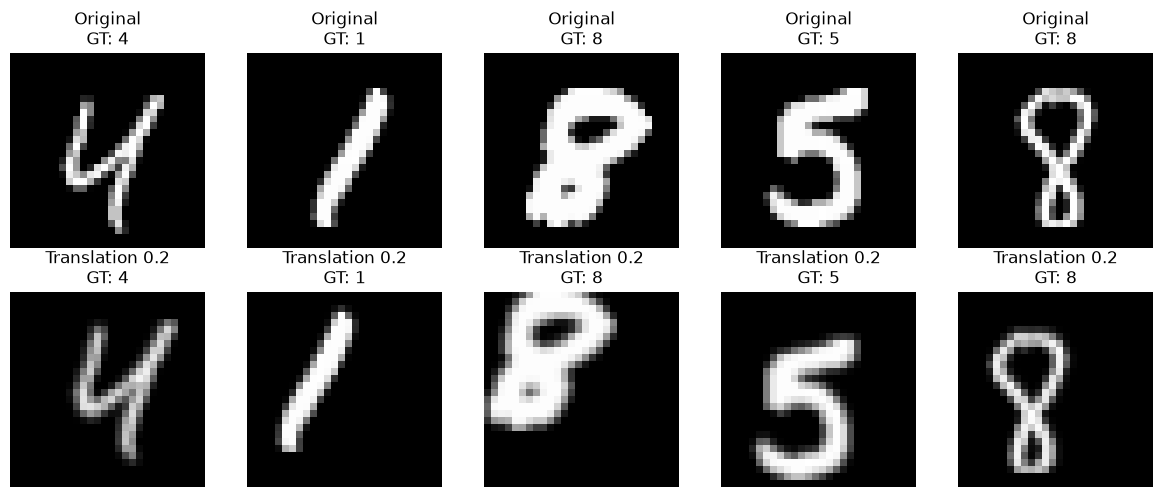

In [92]:
COMBINED_WEIGHT_DECAY_6 = COMBINED_WEIGHT_DECAY_5
COMBINED_DROPOUT_RATE_6 = COMBINED_DROPOUT_RATE_5
COMBINED_TRANSLATION_FACTOR_6 = 0.2

# 使用獨立的增強層預覽，後續模型會另外建立增強層。
preview_augmentation_6 = create_translation_augmentation(
    COMBINED_TRANSLATION_FACTOR_6
)

preview_images_6 = preview_augmentation_6(
    x_train[preview_indices],
    training=True
).numpy()

print("Augmentation method: RandomTranslation")
print(f"Height factor: ±{COMBINED_TRANSLATION_FACTOR_6:.0%}")
print(f"Width factor: ±{COMBINED_TRANSLATION_FACTOR_6:.0%}")
print("Fill mode: constant; fill value: 0.0")
print("Interpolation: bilinear")

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for column, sample_index in enumerate(preview_indices):
    label = int(y_train[sample_index])

    axes[0, column].imshow(
        x_train[sample_index, :, :, 0],
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[0, column].set_title(f"Original\nGT: {label}")
    axes[0, column].axis("off")

    axes[1, column].imshow(
        preview_images_6[column, :, :, 0],
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[1, column].set_title(f"Translation 0.2\nGT: {label}")
    axes[1, column].axis("off")

plt.tight_layout()
plt.show()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_translation              │ (None, 28, 28, 1)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2048)           │    12,847,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ combined_dropout_1 (Dropout)    │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1024)           │     2,098,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ combined_dropout_2 (Dropout)    │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ combined_dropout_3 (Dropout)    │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,734,218 (60.02 MB)

 Trainable params: 15,734,218 (60.02 MB)

 Non-trainable params: 0 (0.00 B)

Parameters: 15734218
Optimizer updates before training: 0
Epoch 1/100


2026-10-04 19:01:47.497556: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


7/7 - 5s - 778ms/step - accuracy: 0.0650 - loss: 2.3365 - val_accuracy: 0.0974 - val_loss: 2.3013
Epoch 2/100
7/7 - 5s - 679ms/step - accuracy: 0.1050 - loss: 2.2998 - val_accuracy: 0.0974 - val_loss: 2.2946
Epoch 3/100
7/7 - 5s - 731ms/step - accuracy: 0.1250 - loss: 2.3105 - val_accuracy: 0.1022 - val_loss: 2.2891
Epoch 4/100
7/7 - 5s - 646ms/step - accuracy: 0.1050 - loss: 2.2944 - val_accuracy: 0.1022 - val_loss: 2.2740
Epoch 5/100
7/7 - 7s - 1s/step - accuracy: 0.1050 - loss: 2.2659 - val_accuracy: 0.2046 - val_loss: 2.1990
Epoch 6/100
7/7 - 5s - 735ms/step - accuracy: 0.2300 - loss: 2.1849 - val_accuracy: 0.3740 - val_loss: 1.9929
Epoch 7/100
7/7 - 5s - 779ms/step - accuracy: 0.2450 - loss: 2.0297 - val_accuracy: 0.3356 - val_loss: 1.6641
Epoch 8/100
7/7 - 5s - 748ms/step - accuracy: 0.3250 - loss: 1.7848 - val_accuracy: 0.5476 - val_loss: 1.2680
Epoch 9/100
7/7 - 6s - 787ms/step - accuracy: 0.3950 - loss: 1.4643 - val_accuracy: 0.5556 - val_loss: 1.2308
Epoch 10/100
7/7 - 5s - 7

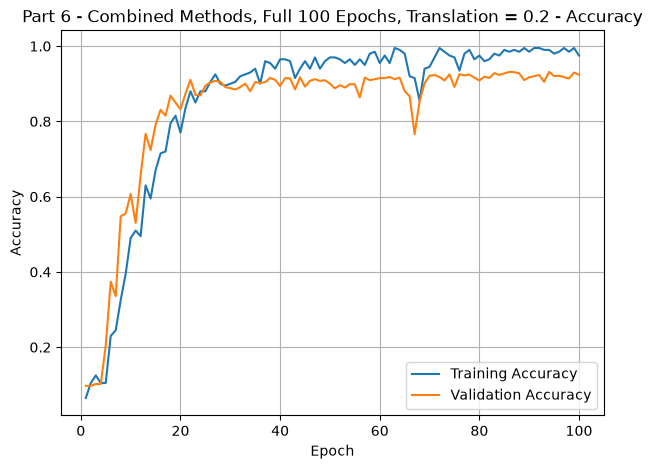

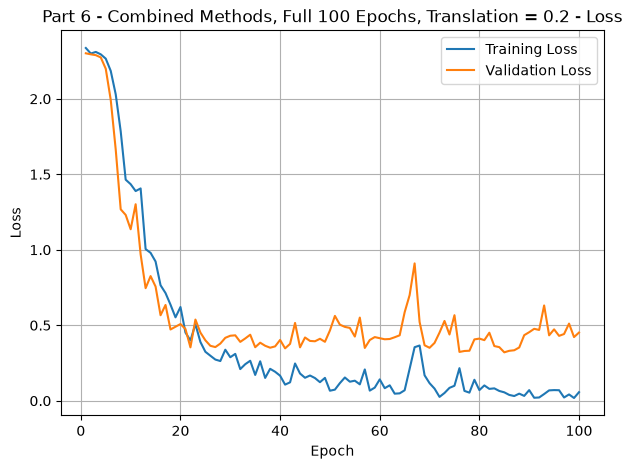

In [94]:
# 每次執行都先建立全新模型。
combined_model_6 = create_combined_model(
    weight_decay=COMBINED_WEIGHT_DECAY_6,
    dropout_rate=COMBINED_DROPOUT_RATE_6,
    translation_factor=COMBINED_TRANSLATION_FACTOR_6
)

combined_model_6.summary()

print("Parameters:", combined_model_6.count_params())
print(
    "Optimizer updates before training:",
    int(combined_model_6.optimizer.iterations.numpy())
)

# 重新建立資料集，沿用相同的 shuffle 與 batch 設定。
combined_train_ds_6 = (
    tf.data.Dataset.from_tensor_slices((x_train, y_train))
    .shuffle(
        buffer_size=len(x_train),
        seed=2026,
        reshuffle_each_iteration=True
    )
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

combined_best_6 = BestValidationAccuracy()

combined_history_6 = combined_model_6.fit(
    combined_train_ds_6,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    callbacks=[combined_best_6],
    verbose=2
)

# 恢復最高 Validation Accuracy 時的權重。
combined_model_6.set_weights(
    combined_best_6.best_weights
)

print("\n=== Part 6: Combined Methods Trial 6 ===")
print(f"Weight decay: {COMBINED_WEIGHT_DECAY_6}")
print(f"Dropout rate: {COMBINED_DROPOUT_RATE_6}")
print(f"Translation factor: {COMBINED_TRANSLATION_FACTOR_6}")
print("Early Stopping: disabled")
print(f"Completed epochs: {len(combined_history_6.history['loss'])}")
print(f"Best Validation Accuracy: {combined_best_6.best_accuracy:.2%}")
print(f"Best Epoch: {combined_best_6.best_epoch}")
print(
    "Optimizer updates after training:",
    int(combined_model_6.optimizer.iterations.numpy())
)
print("Best validation weights restored.")

plot_history(
    combined_history_6,
    title=(
        "Part 6 - Combined Methods, Full 100 Epochs"
        f", Translation = {COMBINED_TRANSLATION_FACTOR_6}"
    )
)

## Trial 7 — Translation 0.15 + BN

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_translation              │ (None, 28, 28, 1)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ combined_batchnorm_1            │ (None, 28, 28, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ combined_relu_1 (ReLU)          │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ combined_batchnorm_2            │ (None, 28, 28, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ combined_relu_2 (ReLU)          │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ combined_batchnorm_3            │ (None, 14, 14, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ combined_relu_3 (ReLU)          │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ combined_batchnorm_4            │ (None, 14, 14, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ combined_relu_4 (ReLU)          │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2048)           │    12,847,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ combined_dropout_1 (Dropout)    │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1024)           │     2,098,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ combined_dropout_2 (Dropout)    │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ combined_dropout_3 (Dropout)    │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 15,735,754 (60.03 MB)

 Trainable params: 15,734,986 (60.02 MB)

 Non-trainable params: 768 (3.00 KB)

Parameters: 15735754
Batch Normalization layers: 4
Optimizer updates before training: 0
Epoch 1/100


2026-10-04 19:10:46.923037: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


7/7 - 8s - 1s/step - accuracy: 0.0850 - loss: 12.6217 - val_accuracy: 0.0998 - val_loss: 3.7959
Epoch 2/100
7/7 - 6s - 927ms/step - accuracy: 0.1200 - loss: 4.1767 - val_accuracy: 0.1022 - val_loss: 2.6416
Epoch 3/100
7/7 - 6s - 826ms/step - accuracy: 0.0950 - loss: 2.6907 - val_accuracy: 0.1188 - val_loss: 2.5032
Epoch 4/100
7/7 - 6s - 894ms/step - accuracy: 0.1350 - loss: 2.5112 - val_accuracy: 0.1290 - val_loss: 2.3264
Epoch 5/100
7/7 - 6s - 847ms/step - accuracy: 0.1500 - loss: 2.3102 - val_accuracy: 0.1214 - val_loss: 2.4166
Epoch 6/100
7/7 - 6s - 864ms/step - accuracy: 0.2150 - loss: 2.1798 - val_accuracy: 0.1626 - val_loss: 2.2409
Epoch 7/100
7/7 - 6s - 886ms/step - accuracy: 0.2400 - loss: 2.1453 - val_accuracy: 0.1658 - val_loss: 2.4467
Epoch 8/100
7/7 - 6s - 841ms/step - accuracy: 0.1900 - loss: 2.1026 - val_accuracy: 0.3768 - val_loss: 1.9695
Epoch 9/100
7/7 - 6s - 895ms/step - accuracy: 0.2550 - loss: 2.0218 - val_accuracy: 0.3164 - val_loss: 1.9348
Epoch 10/100
7/7 - 6s - 

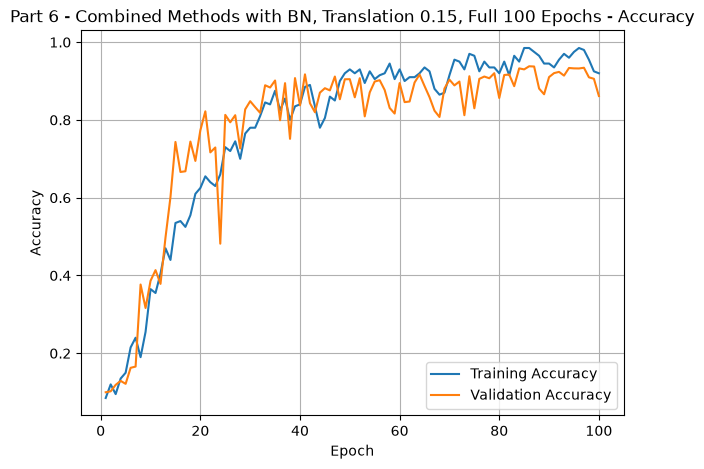

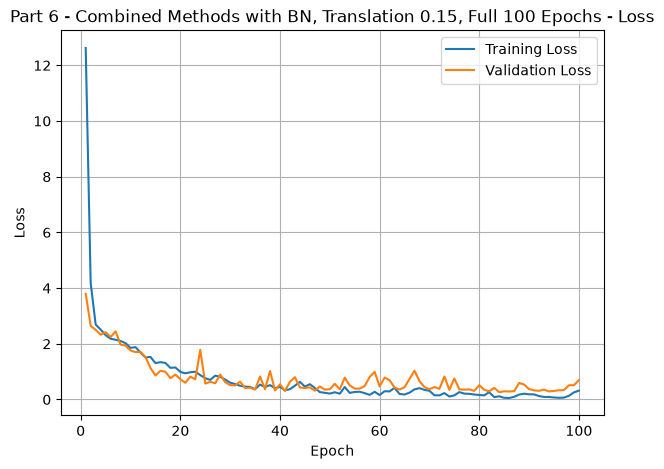

In [95]:
COMBINED_WEIGHT_DECAY_7 = COMBINED_WEIGHT_DECAY_5
COMBINED_DROPOUT_RATE_7 = COMBINED_DROPOUT_RATE_5
COMBINED_TRANSLATION_FACTOR_7 = 0.15
COMBINED_BN_MOMENTUM_7 = COMBINED_BN_MOMENTUM_4

# 每次執行都先建立全新 BN 模型。
combined_model_7 = create_combined_batchnorm_model(
    weight_decay=COMBINED_WEIGHT_DECAY_7,
    dropout_rate=COMBINED_DROPOUT_RATE_7,
    translation_factor=COMBINED_TRANSLATION_FACTOR_7,
    bn_momentum=COMBINED_BN_MOMENTUM_7
)

combined_model_7.summary()

print("Parameters:", combined_model_7.count_params())
print(
    "Batch Normalization layers:",
    sum(
        isinstance(layer, layers.BatchNormalization)
        for layer in combined_model_7.layers
    )
)
print(
    "Optimizer updates before training:",
    int(combined_model_7.optimizer.iterations.numpy())
)

# 重新建立資料集，沿用相同的 shuffle 與 batch 設定。
combined_train_ds_7 = (
    tf.data.Dataset.from_tensor_slices((x_train, y_train))
    .shuffle(
        buffer_size=len(x_train),
        seed=2026,
        reshuffle_each_iteration=True
    )
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

combined_best_7 = BestValidationAccuracy()

combined_history_7 = combined_model_7.fit(
    combined_train_ds_7,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    callbacks=[combined_best_7],
    verbose=2
)

# 恢復最佳 epoch 的權重，包含 BN 的移動統計量。
combined_model_7.set_weights(
    combined_best_7.best_weights
)

print("\n=== Part 6: Combined Methods Trial 7, Translation 0.15 with BN ===")
print(f"Weight decay: {COMBINED_WEIGHT_DECAY_7}")
print(f"Dropout rate: {COMBINED_DROPOUT_RATE_7}")
print(f"Translation factor: {COMBINED_TRANSLATION_FACTOR_7}")
print(f"BN momentum: {COMBINED_BN_MOMENTUM_7}")
print("Early Stopping: disabled")
print(f"Completed epochs: {len(combined_history_7.history['loss'])}")
print(f"Best Validation Accuracy: {combined_best_7.best_accuracy:.2%}")
print(f"Best Epoch: {combined_best_7.best_epoch}")
print(
    "Optimizer updates after training:",
    int(combined_model_7.optimizer.iterations.numpy())
)
print("Best validation weights and BN statistics restored.")

plot_history(
    combined_history_7,
    title="Part 6 - Combined Methods with BN, Translation 0.15, Full 100 Epochs"
)

## Trial 8 — Rotation 0.03 + Translation 0.1

以下比較圖使用獨立的增強物件，接著訓練第八次模型。

Augmentation methods: RandomRotation + RandomTranslation
Rotation range: ±10.8 degrees
Height translation: ±10%
Width translation: ±10%
Fill mode: constant; fill value: 0.0
Interpolation: bilinear


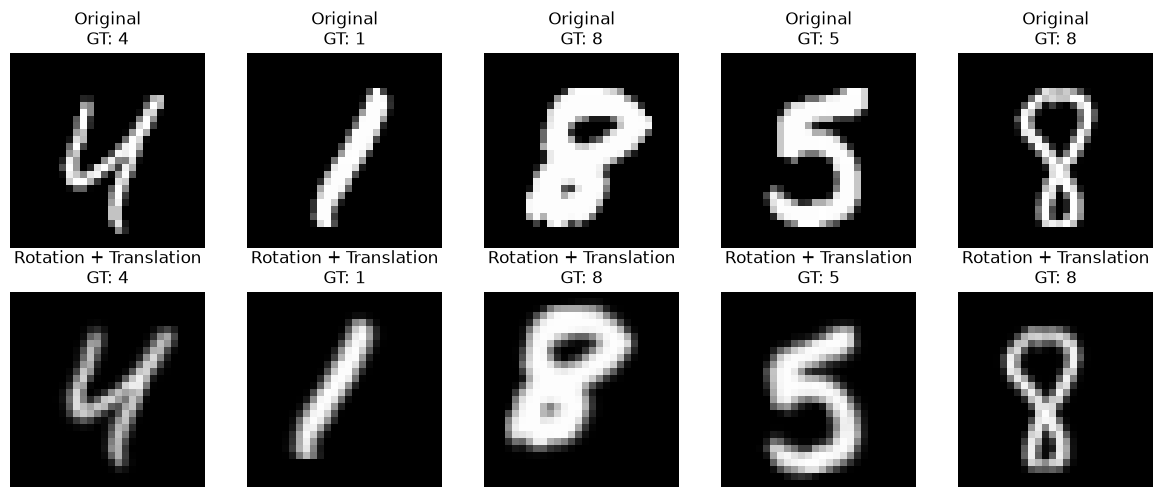

In [100]:
COMBINED_WEIGHT_DECAY_8 = COMBINED_WEIGHT_DECAY_2
COMBINED_DROPOUT_RATE_8 = COMBINED_DROPOUT_RATE_2
COMBINED_TRANSLATION_FACTOR_8 = COMBINED_TRANSLATION_FACTOR_2
COMBINED_ROTATION_FACTOR_8 = 0.03


def create_rotation_translation_augmentation(
    translation_factor,
    rotation_factor
):
    return keras.Sequential([
        # 先模擬小幅書寫傾斜。
        layers.RandomRotation(
            factor=rotation_factor,
            fill_mode="constant",
            fill_value=0.0,
            interpolation="bilinear",
            seed=4102
        ),

        # 再模擬圖片中的位置變化。
        create_translation_augmentation(translation_factor)
    ], name="rotation_translation_augmentation")


# 預覽使用獨立的增強物件，後續訓練模型會另外建立。
preview_augmentation_8 = create_rotation_translation_augmentation(
    translation_factor=COMBINED_TRANSLATION_FACTOR_8,
    rotation_factor=COMBINED_ROTATION_FACTOR_8
)

preview_images_8 = preview_augmentation_8(
    x_train[preview_indices],
    training=True
).numpy()

print("Augmentation methods: RandomRotation + RandomTranslation")
print(
    f"Rotation range: "
    f"±{COMBINED_ROTATION_FACTOR_8 * 360:.1f} degrees"
)
print(f"Height translation: ±{COMBINED_TRANSLATION_FACTOR_8:.0%}")
print(f"Width translation: ±{COMBINED_TRANSLATION_FACTOR_8:.0%}")
print("Fill mode: constant; fill value: 0.0")
print("Interpolation: bilinear")

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for column, sample_index in enumerate(preview_indices):
    label = int(y_train[sample_index])

    axes[0, column].imshow(
        x_train[sample_index, :, :, 0],
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[0, column].set_title(f"Original\nGT: {label}")
    axes[0, column].axis("off")

    axes[1, column].imshow(
        preview_images_8[column, :, :, 0],
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[1, column].set_title(f"Rotation + Translation\nGT: {label}")
    axes[1, column].axis("off")

plt.tight_layout()
plt.show()

Rotation factor: 0.02; range: ±7.2 degrees
Rotation factor: 0.03; range: ±10.8 degrees
Rotation factor: 0.04; range: ±14.4 degrees


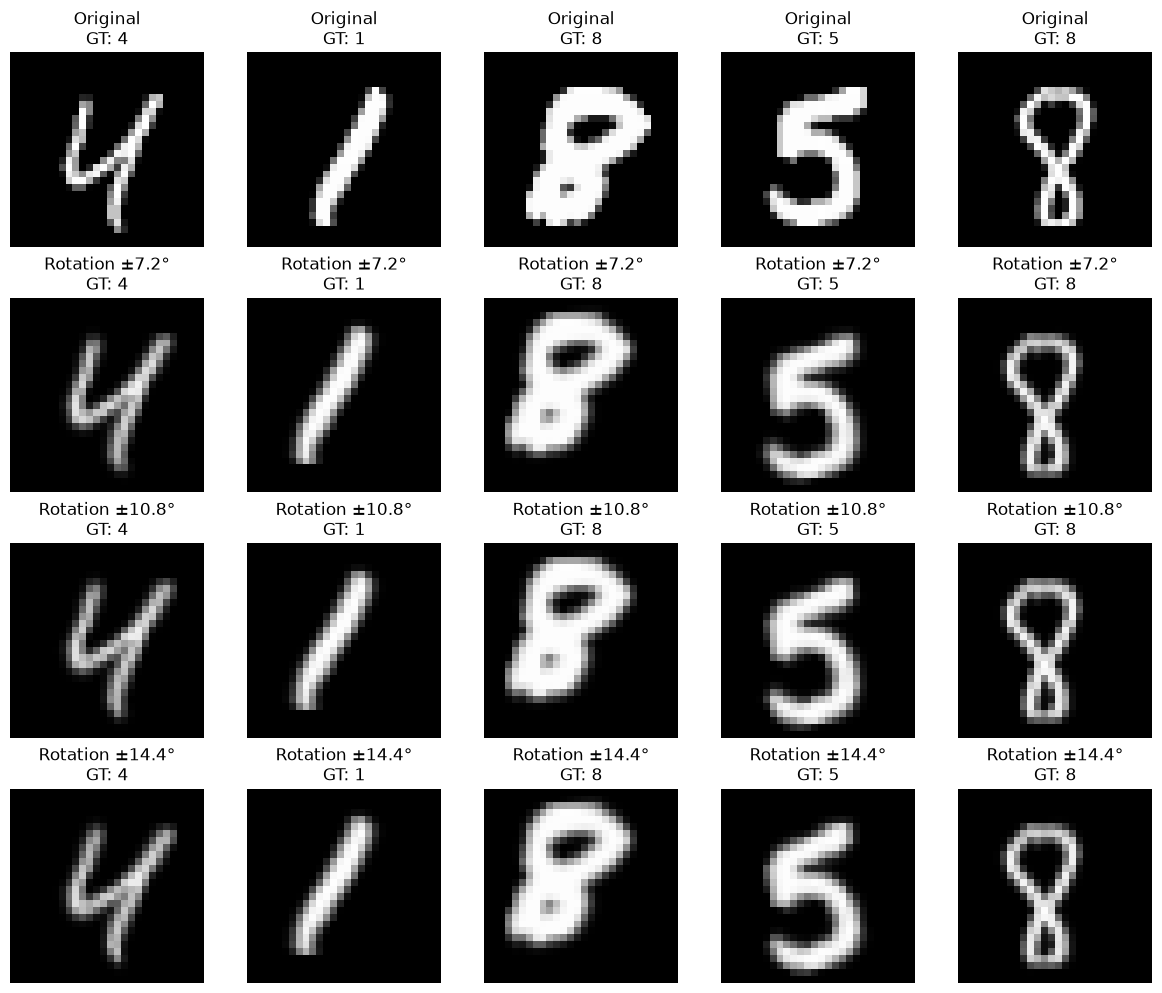

In [98]:
rotation_preview_factors = [0.02, 0.03, 0.04]

fig, axes = plt.subplots(
    1 + len(rotation_preview_factors),
    5,
    figsize=(12, 10)
)

# 第一排顯示同一組原始圖片。
for column, sample_index in enumerate(preview_indices):
    label = int(y_train[sample_index])

    axes[0, column].imshow(
        x_train[sample_index, :, :, 0],
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[0, column].set_title(f"Original\nGT: {label}")
    axes[0, column].axis("off")

# 其餘各排比較不同旋轉幅度，Translation 維持 0.1。
for row, rotation_factor in enumerate(
    rotation_preview_factors,
    start=1
):
    comparison_augmentation = create_rotation_translation_augmentation(
        translation_factor=COMBINED_TRANSLATION_FACTOR_8,
        rotation_factor=rotation_factor
    )

    comparison_images = comparison_augmentation(
        x_train[preview_indices],
        training=True
    ).numpy()

    print(
        f"Rotation factor: {rotation_factor:.2f}; "
        f"range: ±{rotation_factor * 360:.1f} degrees"
    )

    for column, sample_index in enumerate(preview_indices):
        label = int(y_train[sample_index])

        axes[row, column].imshow(
            comparison_images[column, :, :, 0],
            cmap="gray",
            vmin=0,
            vmax=1
        )
        axes[row, column].set_title(
            f"Rotation ±{rotation_factor * 360:.1f}°\nGT: {label}"
        )
        axes[row, column].axis("off")

plt.tight_layout()
plt.show()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rotation_translation_augmentat… │ (None, 28, 28, 1)      │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2048)           │    12,847,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rotation_combined_dropout_1     │ (None, 2048)           │             0 │
│ (Dropout)                       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1024)           │     2,098,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rotation_combined_dropout_2     │ (None, 1024)           │             0 │
│ (Dropout)                       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rotation_combined_dropout_3     │ (None, 512)            │             0 │
│ (Dropout)                       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,734,218 (60.02 MB)

 Trainable params: 15,734,218 (60.02 MB)

 Non-trainable params: 0 (0.00 B)

Parameters: 15734218
Weight decay: 0.0001
Dropout rate: 0.2
Translation factor: 0.1
Rotation factor: 0.03
Rotation range: ±10.8°
Initial optimizer updates: 0
Epoch 1/100


/Users/c2838/NCHU/115-1 中興作業/computer_vision/c3_hw/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step - accuracy: 0.0700 - loss: 2.3308 

2026-10-04 19:41:02.412857: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 565ms/step - accuracy: 0.0700 - loss: 2.3308 - val_accuracy: 0.1768 - val_loss: 2.2977
Epoch 2/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 526ms/step - accuracy: 0.1200 - loss: 2.2918 - val_accuracy: 0.1836 - val_loss: 2.3056
Epoch 3/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 527ms/step - accuracy: 0.1850 - loss: 2.2825 - val_accuracy: 0.3798 - val_loss: 2.2407
Epoch 4/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 529ms/step - accuracy: 0.2250 - loss: 2.1877 - val_accuracy: 0.5656 - val_loss: 1.6141
Epoch 5/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 541ms/step - accuracy: 0.4950 - loss: 1.6461 - val_accuracy: 0.5472 - val_loss: 1.4229
Epoch 6/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 533ms/step - accuracy: 0.5250 - loss: 1.4623 - val_accuracy: 0.6418 - val_loss: 1.1389
Epoch 7/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 562ms/step - accuracy: 0.5850 - loss: 1.1102 - val_accuracy: 0.7764 - val_loss: 0.7634
Epoch 8/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 577ms/step - accuracy: 0.7100 - loss: 0.8840 - val_accuracy: 0.7564 - val_loss: 0.7

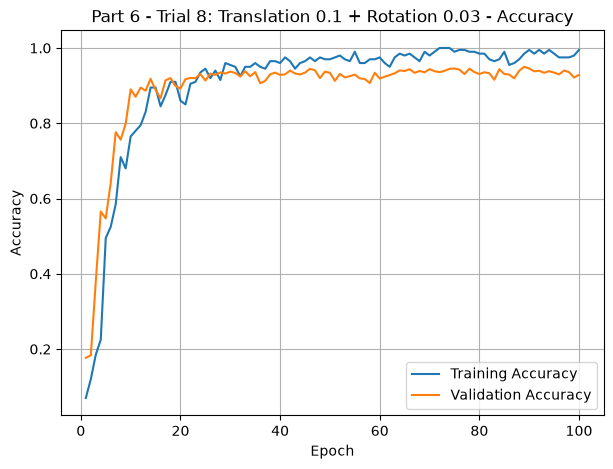

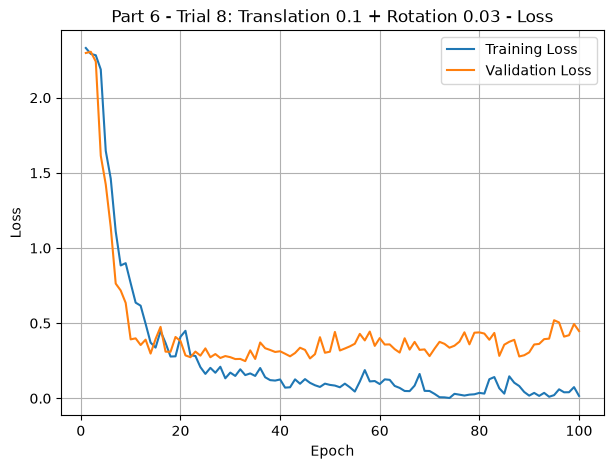

In [101]:
def create_rotation_translation_model(
    weight_decay,
    dropout_rate,
    translation_factor,
    rotation_factor
):
    # 建立全新的老師原始模型，沿用原本架構與固定初始化。
    base_model = create_baseline_model()

    model = keras.Sequential([
        layers.Input(shape=(28, 28, 1)),
        create_rotation_translation_augmentation(
            translation_factor=translation_factor,
            rotation_factor=rotation_factor
        )
    ])

    # 沿用原始模型的所有隱藏層。
    # 只在三個隱藏 Dense 層後加入 Dropout。
    dropout_index = 0

    for layer in base_model.layers[:-1]:
        model.add(layer)

        if isinstance(layer, layers.Dense):
            dropout_index += 1

            model.add(
                layers.Dropout(
                    rate=dropout_rate,
                    seed=3000 + dropout_index,
                    name=f"rotation_combined_dropout_{dropout_index}"
                )
            )

    # 原本的輸出層維持不變。
    model.add(base_model.layers[-1])

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=0.001,
            weight_decay=weight_decay
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


# 每次執行此 cell，都重新建立模型與資料集。
combined_model_8 = create_rotation_translation_model(
    weight_decay=COMBINED_WEIGHT_DECAY_8,
    dropout_rate=COMBINED_DROPOUT_RATE_8,
    translation_factor=COMBINED_TRANSLATION_FACTOR_8,
    rotation_factor=COMBINED_ROTATION_FACTOR_8
)

combined_model_8.summary()

print("Parameters:", combined_model_8.count_params())
print("Weight decay:", COMBINED_WEIGHT_DECAY_8)
print("Dropout rate:", COMBINED_DROPOUT_RATE_8)
print("Translation factor:", COMBINED_TRANSLATION_FACTOR_8)
print("Rotation factor:", COMBINED_ROTATION_FACTOR_8)
print(
    "Rotation range:",
    f"±{COMBINED_ROTATION_FACTOR_8 * 360:.1f}°"
)
print(
    "Initial optimizer updates:",
    int(combined_model_8.optimizer.iterations.numpy())
)

combined_train_ds_8 = (
    tf.data.Dataset.from_tensor_slices((x_train, y_train))
    .shuffle(
        buffer_size=len(x_train),
        seed=2026,
        reshuffle_each_iteration=True
    )
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

combined_best_8 = BestValidationAccuracy()

combined_history_8 = combined_model_8.fit(
    combined_train_ds_8,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    callbacks=[combined_best_8]
)

# 訓練完成後，還原 Validation Accuracy 最高的權重。
combined_model_8.set_weights(combined_best_8.best_weights)

completed_epochs_8 = len(combined_history_8.history["loss"])
batches_per_epoch_8 = (
    len(x_train) + BATCH_SIZE - 1
) // BATCH_SIZE

print("Completed epochs:", completed_epochs_8)
print(
    "Expected updates for a fresh model:",
    completed_epochs_8 * batches_per_epoch_8
)
print(
    "Actual optimizer updates:",
    int(combined_model_8.optimizer.iterations.numpy())
)
print(
    "Best Validation Accuracy:",
    f"{combined_best_8.best_accuracy:.2%}"
)
print("Best Epoch:", combined_best_8.best_epoch)
print("Best validation weights restored.")

plot_history(
    combined_history_8,
    "Part 6 - Trial 8: Translation 0.1 + Rotation 0.03"
)

## Trial 9 — Rotation 0.04，最終採用模型

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rotation_translation_augmentat… │ (None, 28, 28, 1)      │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2048)           │    12,847,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rotation_combined_dropout_1     │ (None, 2048)           │             0 │
│ (Dropout)                       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1024)           │     2,098,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rotation_combined_dropout_2     │ (None, 1024)           │             0 │
│ (Dropout)                       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rotation_combined_dropout_3     │ (None, 512)            │             0 │
│ (Dropout)                       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,734,218 (60.02 MB)

 Trainable params: 15,734,218 (60.02 MB)

 Non-trainable params: 0 (0.00 B)

Parameters: 15734218
Weight decay: 0.0001
Dropout rate: 0.2
Translation factor: 0.1
Rotation factor: 0.04
Rotation range: ±14.4°
Initial optimizer updates: 0
Epoch 1/100


2026-10-04 19:55:11.296904: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


7/7 - 5s - 767ms/step - accuracy: 0.0650 - loss: 2.3319 - val_accuracy: 0.2064 - val_loss: 2.2976
Epoch 2/100
7/7 - 4s - 515ms/step - accuracy: 0.1050 - loss: 2.2950 - val_accuracy: 0.1484 - val_loss: 2.2657
Epoch 3/100
7/7 - 4s - 520ms/step - accuracy: 0.1900 - loss: 2.2714 - val_accuracy: 0.3798 - val_loss: 2.2171
Epoch 4/100
7/7 - 4s - 547ms/step - accuracy: 0.2700 - loss: 2.1156 - val_accuracy: 0.5224 - val_loss: 1.4705
Epoch 5/100
7/7 - 3s - 470ms/step - accuracy: 0.4800 - loss: 1.5867 - val_accuracy: 0.5548 - val_loss: 1.3084
Epoch 6/100
7/7 - 3s - 490ms/step - accuracy: 0.5500 - loss: 1.3628 - val_accuracy: 0.6610 - val_loss: 0.9344
Epoch 7/100
7/7 - 3s - 475ms/step - accuracy: 0.5850 - loss: 1.0068 - val_accuracy: 0.7452 - val_loss: 0.6615
Epoch 8/100
7/7 - 3s - 461ms/step - accuracy: 0.6800 - loss: 0.8405 - val_accuracy: 0.7740 - val_loss: 0.6095
Epoch 9/100
7/7 - 3s - 489ms/step - accuracy: 0.7100 - loss: 0.7585 - val_accuracy: 0.8514 - val_loss: 0.4678
Epoch 10/100
7/7 - 4s 

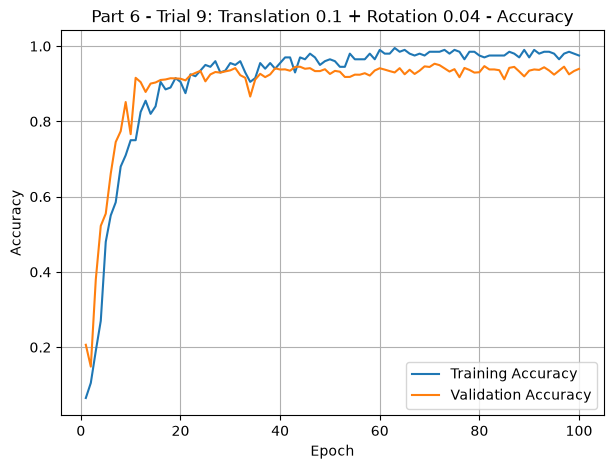

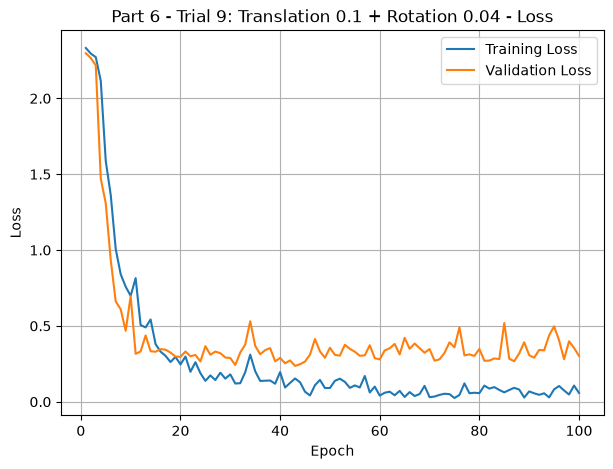

In [102]:
# 第九次只調整旋轉幅度，其餘沿用第八次設定。
COMBINED_WEIGHT_DECAY_9 = COMBINED_WEIGHT_DECAY_8
COMBINED_DROPOUT_RATE_9 = COMBINED_DROPOUT_RATE_8
COMBINED_TRANSLATION_FACTOR_9 = COMBINED_TRANSLATION_FACTOR_8
COMBINED_ROTATION_FACTOR_9 = 0.04

# 建立全新的模型與增強層，避免接續第八次訓練。
combined_model_9 = create_rotation_translation_model(
    weight_decay=COMBINED_WEIGHT_DECAY_9,
    dropout_rate=COMBINED_DROPOUT_RATE_9,
    translation_factor=COMBINED_TRANSLATION_FACTOR_9,
    rotation_factor=COMBINED_ROTATION_FACTOR_9
)

combined_model_9.summary()

print("Parameters:", combined_model_9.count_params())
print("Weight decay:", COMBINED_WEIGHT_DECAY_9)
print("Dropout rate:", COMBINED_DROPOUT_RATE_9)
print("Translation factor:", COMBINED_TRANSLATION_FACTOR_9)
print("Rotation factor:", COMBINED_ROTATION_FACTOR_9)
print(
    "Rotation range:",
    f"±{COMBINED_ROTATION_FACTOR_9 * 360:.1f}°"
)
print(
    "Initial optimizer updates:",
    int(combined_model_9.optimizer.iterations.numpy())
)

# 重新建立資料集，使用相同的 shuffle seed 與 batch size。
combined_train_ds_9 = (
    tf.data.Dataset.from_tensor_slices((x_train, y_train))
    .shuffle(
        buffer_size=len(x_train),
        seed=2026,
        reshuffle_each_iteration=True
    )
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

# 獨立記錄第九次的最佳驗證準確率與權重。
combined_best_9 = BestValidationAccuracy()

combined_history_9 = combined_model_9.fit(
    combined_train_ds_9,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    callbacks=[combined_best_9],
    verbose=2
)

# 還原最高 Validation Accuracy 的權重。
combined_model_9.set_weights(combined_best_9.best_weights)

completed_epochs_9 = len(combined_history_9.history["loss"])
batches_per_epoch_9 = (
    len(x_train) + BATCH_SIZE - 1
) // BATCH_SIZE

print("\n=== Part 6: Combined Methods Trial 9 ===")
print("Completed epochs:", completed_epochs_9)
print(
    "Expected updates for a fresh model:",
    completed_epochs_9 * batches_per_epoch_9
)
print(
    "Actual optimizer updates:",
    int(combined_model_9.optimizer.iterations.numpy())
)
print(
    "Best Validation Accuracy:",
    f"{combined_best_9.best_accuracy:.2%}"
)
print("Best Epoch:", combined_best_9.best_epoch)
print("Best validation weights restored.")

plot_history(
    combined_history_9,
    title="Part 6 - Trial 9: Translation 0.1 + Rotation 0.04"
)

## Trial 10 — Dropout 0.3

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rotation_translation_augmentat… │ (None, 28, 28, 1)      │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2048)           │    12,847,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rotation_combined_dropout_1     │ (None, 2048)           │             0 │
│ (Dropout)                       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1024)           │     2,098,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rotation_combined_dropout_2     │ (None, 1024)           │             0 │
│ (Dropout)                       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rotation_combined_dropout_3     │ (None, 512)            │             0 │
│ (Dropout)                       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,734,218 (60.02 MB)

 Trainable params: 15,734,218 (60.02 MB)

 Non-trainable params: 0 (0.00 B)

Parameters: 15734218
Weight decay: 0.0001
Dropout rate: 0.3
Translation factor: 0.1
Rotation factor: 0.04
Initial optimizer updates: 0
Epoch 1/100


2026-10-04 20:16:19.417208: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


7/7 - 6s - 895ms/step - accuracy: 0.0650 - loss: 2.3300 - val_accuracy: 0.1882 - val_loss: 2.2985
Epoch 2/100
7/7 - 4s - 548ms/step - accuracy: 0.1000 - loss: 2.2942 - val_accuracy: 0.1556 - val_loss: 2.2834
Epoch 3/100
7/7 - 4s - 557ms/step - accuracy: 0.1200 - loss: 2.2924 - val_accuracy: 0.1986 - val_loss: 2.2723
Epoch 4/100
7/7 - 4s - 518ms/step - accuracy: 0.1500 - loss: 2.2601 - val_accuracy: 0.1154 - val_loss: 2.1359
Epoch 5/100
7/7 - 4s - 514ms/step - accuracy: 0.1900 - loss: 2.0962 - val_accuracy: 0.5182 - val_loss: 1.5802
Epoch 6/100
7/7 - 4s - 519ms/step - accuracy: 0.4450 - loss: 1.6523 - val_accuracy: 0.5036 - val_loss: 1.3928
Epoch 7/100
7/7 - 4s - 534ms/step - accuracy: 0.5500 - loss: 1.3413 - val_accuracy: 0.6952 - val_loss: 0.9457
Epoch 8/100
7/7 - 4s - 544ms/step - accuracy: 0.6100 - loss: 1.1145 - val_accuracy: 0.6884 - val_loss: 0.8708
Epoch 9/100
7/7 - 4s - 533ms/step - accuracy: 0.5900 - loss: 1.0847 - val_accuracy: 0.8026 - val_loss: 0.6440
Epoch 10/100
7/7 - 4s 

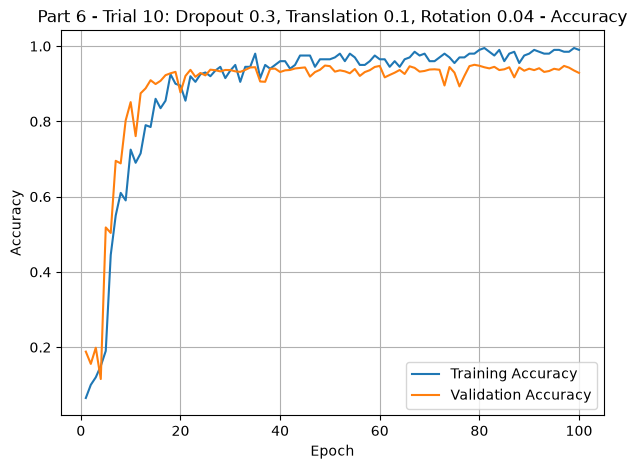

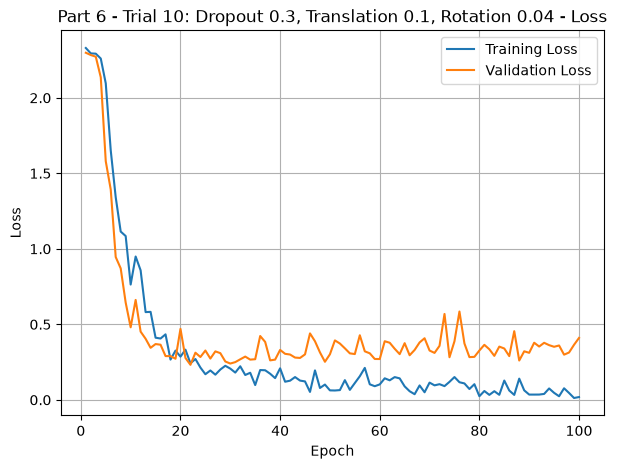

In [105]:
# 第十次只調整 Dropout，其餘沿用第九次。
COMBINED_WEIGHT_DECAY_10 = COMBINED_WEIGHT_DECAY_9
COMBINED_DROPOUT_RATE_10 = 0.3
COMBINED_TRANSLATION_FACTOR_10 = COMBINED_TRANSLATION_FACTOR_9
COMBINED_ROTATION_FACTOR_10 = COMBINED_ROTATION_FACTOR_9

# 建立全新的模型，避免接續先前的訓練。
combined_model_10 = create_rotation_translation_model(
    weight_decay=COMBINED_WEIGHT_DECAY_10,
    dropout_rate=COMBINED_DROPOUT_RATE_10,
    translation_factor=COMBINED_TRANSLATION_FACTOR_10,
    rotation_factor=COMBINED_ROTATION_FACTOR_10
)

combined_model_10.summary()

print("Parameters:", combined_model_10.count_params())
print("Weight decay:", COMBINED_WEIGHT_DECAY_10)
print("Dropout rate:", COMBINED_DROPOUT_RATE_10)
print("Translation factor:", COMBINED_TRANSLATION_FACTOR_10)
print("Rotation factor:", COMBINED_ROTATION_FACTOR_10)
print(
    "Initial optimizer updates:",
    int(combined_model_10.optimizer.iterations.numpy())
)

# 重新建立資料集，維持相同的洗牌與 batch 設定。
combined_train_ds_10 = (
    tf.data.Dataset.from_tensor_slices((x_train, y_train))
    .shuffle(
        buffer_size=len(x_train),
        seed=2026,
        reshuffle_each_iteration=True
    )
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

# 獨立記錄第十次的最佳驗證準確率與權重。
combined_best_10 = BestValidationAccuracy()

combined_history_10 = combined_model_10.fit(
    combined_train_ds_10,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    callbacks=[combined_best_10],
    verbose=2
)

# 還原最高 Validation Accuracy 的權重。
combined_model_10.set_weights(
    combined_best_10.best_weights
)

completed_epochs_10 = len(combined_history_10.history["loss"])
batches_per_epoch_10 = (
    len(x_train) + BATCH_SIZE - 1
) // BATCH_SIZE

print("\n=== Part 6: Combined Methods Trial 10 ===")
print("Completed epochs:", completed_epochs_10)
print(
    "Expected updates for a fresh model:",
    completed_epochs_10 * batches_per_epoch_10
)
print(
    "Actual optimizer updates:",
    int(combined_model_10.optimizer.iterations.numpy())
)
print(
    "Best Validation Accuracy:",
    f"{combined_best_10.best_accuracy:.2%}"
)
print("Best Epoch:", combined_best_10.best_epoch)
print("Best validation weights restored.")

plot_history(
    combined_history_10,
    title="Part 6 - Trial 10: Dropout 0.3, Translation 0.1, Rotation 0.04"
)

## Trial 11 — Dropout 0.4 + Zoom 0.05

Augmentation order: Zoom -> Rotation -> Translation
Zoom factor: 0.05
Aspect ratio: preserved
Rotation range: ±14.4°
Translation factor: 0.1
Fill mode: constant; fill value: 0.0
Interpolation: bilinear


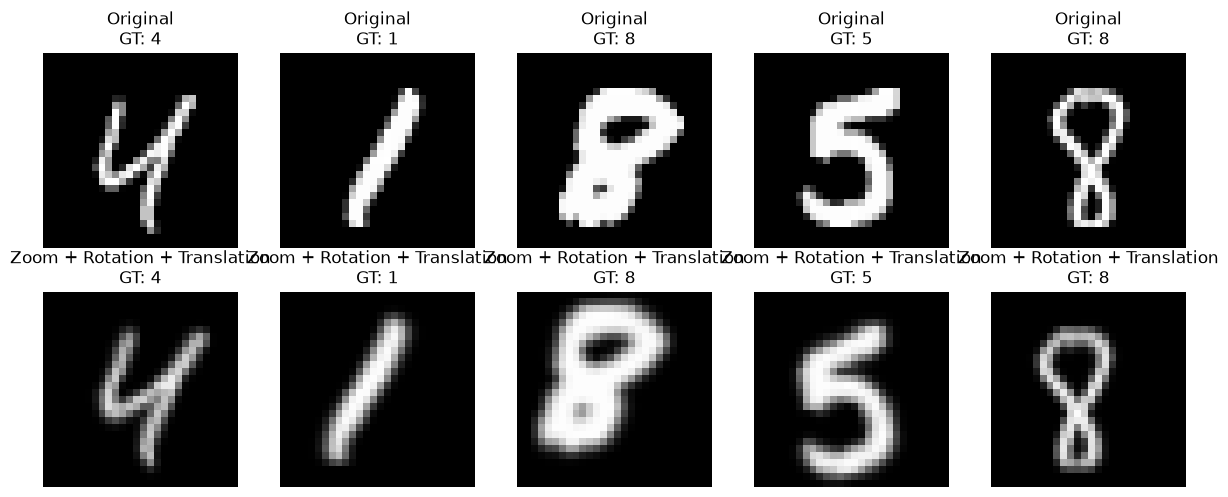

In [106]:
COMBINED_WEIGHT_DECAY_11 = COMBINED_WEIGHT_DECAY_9
COMBINED_DROPOUT_RATE_11 = 0.4
COMBINED_TRANSLATION_FACTOR_11 = COMBINED_TRANSLATION_FACTOR_9
COMBINED_ROTATION_FACTOR_11 = COMBINED_ROTATION_FACTOR_9
COMBINED_ZOOM_FACTOR_11 = 0.05


def create_zoom_augmentation(zoom_factor):
    return layers.RandomZoom(
        height_factor=zoom_factor,
        width_factor=None,
        fill_mode="constant",
        fill_value=0.0,
        interpolation="bilinear",
        seed=4103
    )


# 預覽使用獨立物件，避免消耗訓練增強層的隨機狀態。
preview_augmentation_11 = keras.Sequential([
    create_zoom_augmentation(COMBINED_ZOOM_FACTOR_11),
    create_rotation_translation_augmentation(
        translation_factor=COMBINED_TRANSLATION_FACTOR_11,
        rotation_factor=COMBINED_ROTATION_FACTOR_11
    )
])

preview_images_11 = preview_augmentation_11(
    x_train[preview_indices],
    training=True
).numpy()

print("Augmentation order: Zoom -> Rotation -> Translation")
print("Zoom factor:", COMBINED_ZOOM_FACTOR_11)
print("Aspect ratio: preserved")
print(
    "Rotation range:",
    f"±{COMBINED_ROTATION_FACTOR_11 * 360:.1f}°"
)
print("Translation factor:", COMBINED_TRANSLATION_FACTOR_11)
print("Fill mode: constant; fill value: 0.0")
print("Interpolation: bilinear")

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for column, sample_index in enumerate(preview_indices):
    label = int(y_train[sample_index])

    axes[0, column].imshow(
        x_train[sample_index, :, :, 0],
        cmap="gray", vmin=0, vmax=1
    )
    axes[0, column].set_title(f"Original\nGT: {label}")
    axes[0, column].axis("off")

    axes[1, column].imshow(
        preview_images_11[column, :, :, 0],
        cmap="gray", vmin=0, vmax=1
    )
    axes[1, column].set_title(f"Zoom + Rotation + Translation\nGT: {label}")
    axes[1, column].axis("off")

plt.tight_layout()
plt.show()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_zoom (RandomZoom)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rotation_translation_augmentat… │ (None, 28, 28, 1)      │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2048)           │    12,847,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rotation_combined_dropout_1     │ (None, 2048)           │             0 │
│ (Dropout)                       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1024)           │     2,098,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rotation_combined_dropout_2     │ (None, 1024)           │             0 │
│ (Dropout)                       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rotation_combined_dropout_3     │ (None, 512)            │             0 │
│ (Dropout)                       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,734,218 (60.02 MB)

 Trainable params: 15,734,218 (60.02 MB)

 Non-trainable params: 0 (0.00 B)

Parameters: 15734218
Weight decay: 0.0001
Dropout rate: 0.4
Translation factor: 0.1
Rotation factor: 0.04
Zoom factor: 0.05
Initial optimizer updates: 0
Epoch 1/100


2026-10-04 20:38:39.193919: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


7/7 - 6s - 787ms/step - accuracy: 0.0600 - loss: 2.3343 - val_accuracy: 0.0974 - val_loss: 2.3009
Epoch 2/100
7/7 - 3s - 476ms/step - accuracy: 0.0950 - loss: 2.3026 - val_accuracy: 0.1098 - val_loss: 2.2995
Epoch 3/100
7/7 - 3s - 484ms/step - accuracy: 0.0850 - loss: 2.3044 - val_accuracy: 0.1022 - val_loss: 2.2898
Epoch 4/100
7/7 - 3s - 493ms/step - accuracy: 0.0950 - loss: 2.2980 - val_accuracy: 0.1022 - val_loss: 2.2626
Epoch 5/100
7/7 - 3s - 483ms/step - accuracy: 0.0950 - loss: 2.2566 - val_accuracy: 0.1460 - val_loss: 2.1703
Epoch 6/100
7/7 - 4s - 508ms/step - accuracy: 0.1750 - loss: 2.1268 - val_accuracy: 0.4208 - val_loss: 1.8537
Epoch 7/100
7/7 - 3s - 481ms/step - accuracy: 0.3650 - loss: 1.8729 - val_accuracy: 0.5778 - val_loss: 1.3062
Epoch 8/100
7/7 - 4s - 519ms/step - accuracy: 0.5250 - loss: 1.5129 - val_accuracy: 0.6710 - val_loss: 0.9832
Epoch 9/100
7/7 - 4s - 599ms/step - accuracy: 0.5750 - loss: 1.2454 - val_accuracy: 0.7558 - val_loss: 0.7473
Epoch 10/100
7/7 - 4s 

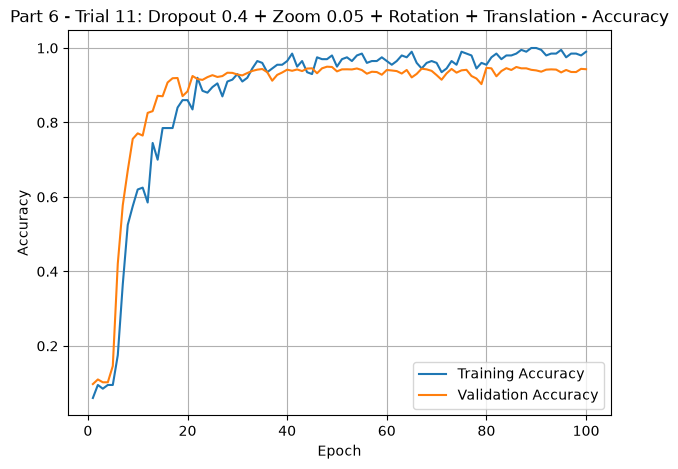

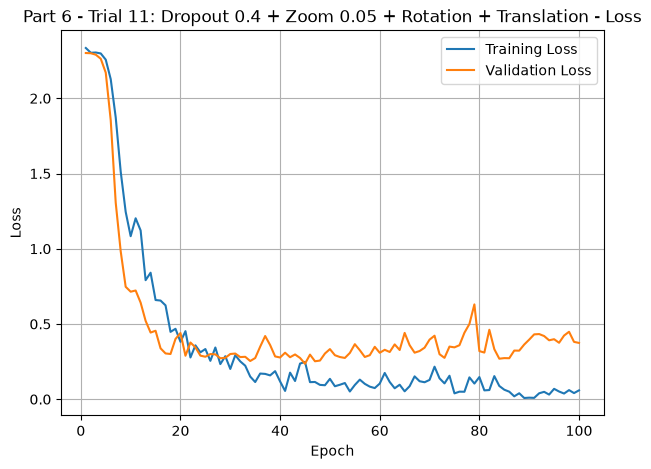

In [107]:
def create_zoom_combined_model(
    weight_decay,
    dropout_rate,
    translation_factor,
    rotation_factor,
    zoom_factor
):
    # 建立全新的既有組合模型，保留老師原始架構與初始化。
    base_model = create_rotation_translation_model(
        weight_decay=weight_decay,
        dropout_rate=dropout_rate,
        translation_factor=translation_factor,
        rotation_factor=rotation_factor
    )

    model = keras.Sequential([
        layers.Input(shape=(28, 28, 1)),
        create_zoom_augmentation(zoom_factor)
    ])

    # 包含既有的 Rotation、Translation、原始 CNN 與三個 Dropout。
    for layer in base_model.layers:
        model.add(layer)

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=0.001,
            weight_decay=weight_decay
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


combined_model_11 = create_zoom_combined_model(
    weight_decay=COMBINED_WEIGHT_DECAY_11,
    dropout_rate=COMBINED_DROPOUT_RATE_11,
    translation_factor=COMBINED_TRANSLATION_FACTOR_11,
    rotation_factor=COMBINED_ROTATION_FACTOR_11,
    zoom_factor=COMBINED_ZOOM_FACTOR_11
)

combined_model_11.summary()

print("Parameters:", combined_model_11.count_params())
print("Weight decay:", COMBINED_WEIGHT_DECAY_11)
print("Dropout rate:", COMBINED_DROPOUT_RATE_11)
print("Translation factor:", COMBINED_TRANSLATION_FACTOR_11)
print("Rotation factor:", COMBINED_ROTATION_FACTOR_11)
print("Zoom factor:", COMBINED_ZOOM_FACTOR_11)
print(
    "Initial optimizer updates:",
    int(combined_model_11.optimizer.iterations.numpy())
)

combined_train_ds_11 = (
    tf.data.Dataset.from_tensor_slices((x_train, y_train))
    .shuffle(
        buffer_size=len(x_train),
        seed=2026,
        reshuffle_each_iteration=True
    )
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

combined_best_11 = BestValidationAccuracy()

combined_history_11 = combined_model_11.fit(
    combined_train_ds_11,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    callbacks=[combined_best_11],
    verbose=2
)

combined_model_11.set_weights(
    combined_best_11.best_weights
)

completed_epochs_11 = len(combined_history_11.history["loss"])
batches_per_epoch_11 = (
    len(x_train) + BATCH_SIZE - 1
) // BATCH_SIZE

print("\n=== Part 6: Combined Methods Trial 11 ===")
print("Completed epochs:", completed_epochs_11)
print(
    "Expected updates for a fresh model:",
    completed_epochs_11 * batches_per_epoch_11
)
print(
    "Actual optimizer updates:",
    int(combined_model_11.optimizer.iterations.numpy())
)
print(
    "Best Validation Accuracy:",
    f"{combined_best_11.best_accuracy:.2%}"
)
print("Best Epoch:", combined_best_11.best_epoch)
print("Best validation weights restored.")

plot_history(
    combined_history_11,
    title="Part 6 - Trial 11: Dropout 0.4 + Zoom 0.05 + Rotation + Translation"
)

## Trial 12 — Dropout 0.3 + Zoom 0.05

Augmentation order: Zoom -> Rotation -> Translation
Zoom factor: 0.05
Aspect ratio: preserved
Rotation range: ±14.4°
Translation factor: 0.1
Fill mode: constant; fill value: 0.0
Interpolation: bilinear


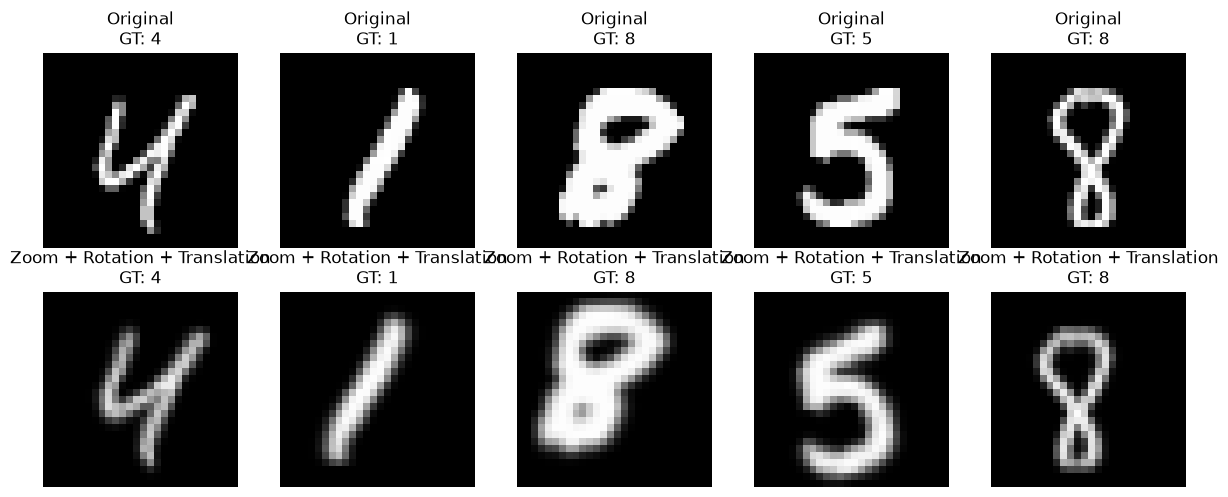

In [108]:
COMBINED_WEIGHT_DECAY_12 = COMBINED_WEIGHT_DECAY_9
COMBINED_DROPOUT_RATE_12 = 0.3
COMBINED_TRANSLATION_FACTOR_12 = COMBINED_TRANSLATION_FACTOR_9
COMBINED_ROTATION_FACTOR_12 = COMBINED_ROTATION_FACTOR_9
COMBINED_ZOOM_FACTOR_12 = 0.05


def create_zoom_augmentation(zoom_factor):
    return layers.RandomZoom(
        height_factor=zoom_factor,
        width_factor=None,
        fill_mode="constant",
        fill_value=0.0,
        interpolation="bilinear",
        seed=4103
    )


# 預覽使用獨立物件，避免消耗訓練增強層的隨機狀態。
preview_augmentation_12 = keras.Sequential([
    create_zoom_augmentation(COMBINED_ZOOM_FACTOR_12),
    create_rotation_translation_augmentation(
        translation_factor=COMBINED_TRANSLATION_FACTOR_12,
        rotation_factor=COMBINED_ROTATION_FACTOR_12
    )
])

preview_images_12 = preview_augmentation_12(
    x_train[preview_indices],
    training=True
).numpy()

print("Augmentation order: Zoom -> Rotation -> Translation")
print("Zoom factor:", COMBINED_ZOOM_FACTOR_12)
print("Aspect ratio: preserved")
print(
    "Rotation range:",
    f"±{COMBINED_ROTATION_FACTOR_12 * 360:.1f}°"
)
print("Translation factor:", COMBINED_TRANSLATION_FACTOR_12)
print("Fill mode: constant; fill value: 0.0")
print("Interpolation: bilinear")

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for column, sample_index in enumerate(preview_indices):
    label = int(y_train[sample_index])

    axes[0, column].imshow(
        x_train[sample_index, :, :, 0],
        cmap="gray", vmin=0, vmax=1
    )
    axes[0, column].set_title(f"Original\nGT: {label}")
    axes[0, column].axis("off")

    axes[1, column].imshow(
        preview_images_12[column, :, :, 0],
        cmap="gray", vmin=0, vmax=1
    )
    axes[1, column].set_title(f"Zoom + Rotation + Translation\nGT: {label}")
    axes[1, column].axis("off")

plt.tight_layout()
plt.show()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_zoom (RandomZoom)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rotation_translation_augmentat… │ (None, 28, 28, 1)      │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2048)           │    12,847,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rotation_combined_dropout_1     │ (None, 2048)           │             0 │
│ (Dropout)                       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1024)           │     2,098,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rotation_combined_dropout_2     │ (None, 1024)           │             0 │
│ (Dropout)                       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rotation_combined_dropout_3     │ (None, 512)            │             0 │
│ (Dropout)                       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,734,218 (60.02 MB)

 Trainable params: 15,734,218 (60.02 MB)

 Non-trainable params: 0 (0.00 B)

Parameters: 15734218
Weight decay: 0.0001
Dropout rate: 0.3
Translation factor: 0.1
Rotation factor: 0.04
Zoom factor: 0.05
Initial optimizer updates: 0
Epoch 1/100


/Users/c2838/NCHU/115-1 中興作業/computer_vision/c3_hw/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
2026-10-04 20:47:40.268561: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. 

7/7 - 5s - 783ms/step - accuracy: 0.0600 - loss: 2.3280 - val_accuracy: 0.0956 - val_loss: 2.2990
Epoch 2/100
7/7 - 3s - 476ms/step - accuracy: 0.1000 - loss: 2.2982 - val_accuracy: 0.1434 - val_loss: 2.2804
Epoch 3/100
7/7 - 3s - 487ms/step - accuracy: 0.1150 - loss: 2.2909 - val_accuracy: 0.2504 - val_loss: 2.2693
Epoch 4/100
7/7 - 4s - 509ms/step - accuracy: 0.1500 - loss: 2.2501 - val_accuracy: 0.1138 - val_loss: 2.1870
Epoch 5/100
7/7 - 4s - 515ms/step - accuracy: 0.2650 - loss: 2.1213 - val_accuracy: 0.4678 - val_loss: 1.6686
Epoch 6/100
7/7 - 3s - 496ms/step - accuracy: 0.4400 - loss: 1.7653 - val_accuracy: 0.6486 - val_loss: 1.1468
Epoch 7/100
7/7 - 3s - 492ms/step - accuracy: 0.5550 - loss: 1.2624 - val_accuracy: 0.7464 - val_loss: 0.7898
Epoch 8/100
7/7 - 4s - 513ms/step - accuracy: 0.6400 - loss: 1.0548 - val_accuracy: 0.7274 - val_loss: 0.7881
Epoch 9/100
7/7 - 4s - 501ms/step - accuracy: 0.6150 - loss: 0.9813 - val_accuracy: 0.8338 - val_loss: 0.5242
Epoch 10/100
7/7 - 4s 

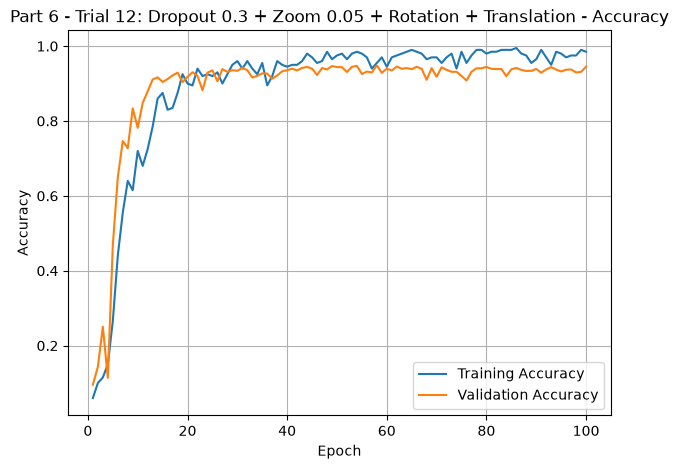

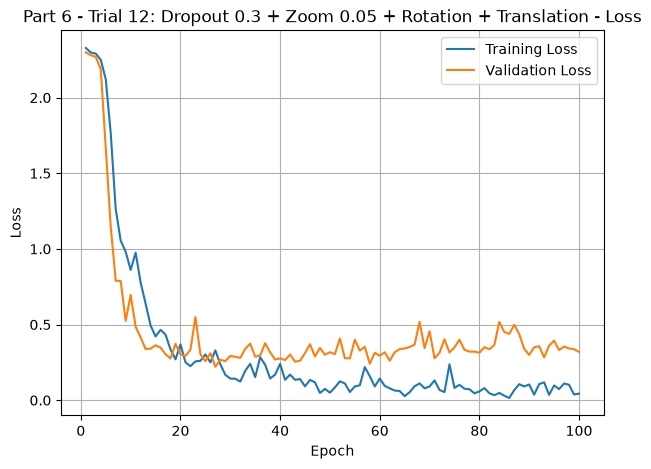

In [109]:
def create_zoom_combined_model(
    weight_decay,
    dropout_rate,
    translation_factor,
    rotation_factor,
    zoom_factor
):
    # 建立全新的既有組合模型，保留老師原始架構與初始化。
    base_model = create_rotation_translation_model(
        weight_decay=weight_decay,
        dropout_rate=dropout_rate,
        translation_factor=translation_factor,
        rotation_factor=rotation_factor
    )

    model = keras.Sequential([
        layers.Input(shape=(28, 28, 1)),
        create_zoom_augmentation(zoom_factor)
    ])

    # 包含既有的 Rotation、Translation、原始 CNN 與三個 Dropout。
    for layer in base_model.layers:
        model.add(layer)

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=0.001,
            weight_decay=weight_decay
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


combined_model_12 = create_zoom_combined_model(
    weight_decay=COMBINED_WEIGHT_DECAY_12,
    dropout_rate=COMBINED_DROPOUT_RATE_12,
    translation_factor=COMBINED_TRANSLATION_FACTOR_12,
    rotation_factor=COMBINED_ROTATION_FACTOR_12,
    zoom_factor=COMBINED_ZOOM_FACTOR_12
)

combined_model_12.summary()

print("Parameters:", combined_model_12.count_params())
print("Weight decay:", COMBINED_WEIGHT_DECAY_12)
print("Dropout rate:", COMBINED_DROPOUT_RATE_12)
print("Translation factor:", COMBINED_TRANSLATION_FACTOR_12)
print("Rotation factor:", COMBINED_ROTATION_FACTOR_12)
print("Zoom factor:", COMBINED_ZOOM_FACTOR_12)
print(
    "Initial optimizer updates:",
    int(combined_model_12.optimizer.iterations.numpy())
)

combined_train_ds_12 = (
    tf.data.Dataset.from_tensor_slices((x_train, y_train))
    .shuffle(
        buffer_size=len(x_train),
        seed=2026,
        reshuffle_each_iteration=True
    )
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

combined_best_12 = BestValidationAccuracy()

combined_history_12 = combined_model_12.fit(
    combined_train_ds_12,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    callbacks=[combined_best_12],
    verbose=2
)

combined_model_12.set_weights(
    combined_best_12.best_weights
)

completed_epochs_12 = len(combined_history_12.history["loss"])
batches_per_epoch_12 = (
    len(x_train) + BATCH_SIZE - 1
) // BATCH_SIZE

print("\n=== Part 6: Combined Methods Trial 12 ===")
print("Completed epochs:", completed_epochs_12)
print(
    "Expected updates for a fresh model:",
    completed_epochs_12 * batches_per_epoch_12
)
print(
    "Actual optimizer updates:",
    int(combined_model_12.optimizer.iterations.numpy())
)
print(
    "Best Validation Accuracy:",
    f"{combined_best_12.best_accuracy:.2%}"
)
print("Best Epoch:", combined_best_12.best_epoch)
print("Best validation weights restored.")

plot_history(
    combined_history_12,
    title="Part 6 - Trial 12: Dropout 0.3 + Zoom 0.05 + Rotation + Translation"
)

## Trial 13 — Rotation 0.05

Augmentation order: Rotation -> Translation
Rotation range: ±18.0°
Translation factor: 0.1
Dropout rate for training: 0.2
Weight decay: 0.0001
Zoom: disabled
Fill mode: constant; fill value: 0.0
Interpolation: bilinear


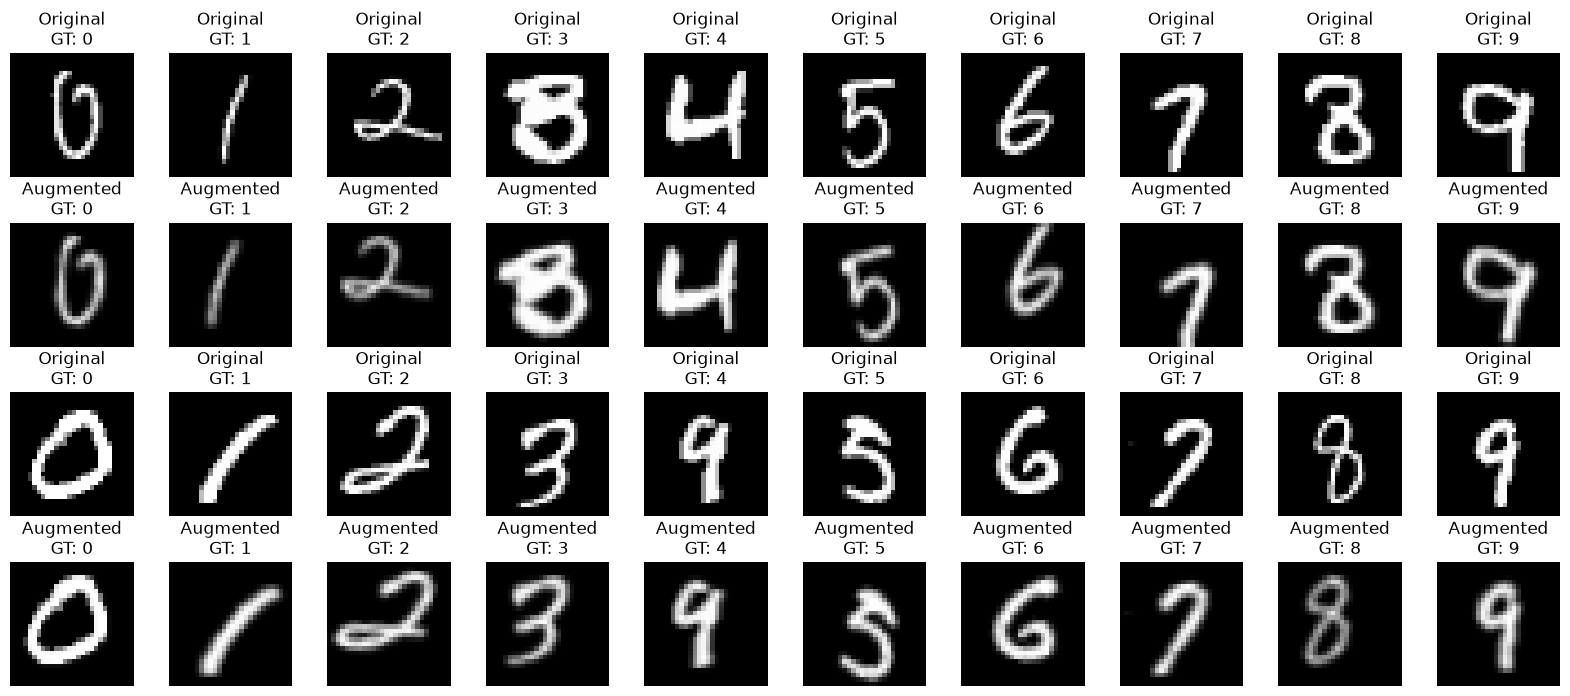

In [110]:
# 第十三次只增加 Rotation，其他設定沿用第九次。
COMBINED_WEIGHT_DECAY_13 = COMBINED_WEIGHT_DECAY_9
COMBINED_DROPOUT_RATE_13 = COMBINED_DROPOUT_RATE_9
COMBINED_TRANSLATION_FACTOR_13 = COMBINED_TRANSLATION_FACTOR_9
COMBINED_ROTATION_FACTOR_13 = 0.05

# 使用獨立的亂數產生器，每個數字抽兩張訓練圖片。
rotation_preview_rng_13 = np.random.default_rng(4313)

preview_indices_by_digit_13 = [
    rotation_preview_rng_13.choice(
        np.flatnonzero(y_train == digit),
        size=2,
        replace=False
    )
    for digit in range(10)
]

# 排成兩組，每組依序包含數字 0–9。
rotation_preview_indices_13 = np.array([
    preview_indices_by_digit_13[digit][group]
    for group in range(2)
    for digit in range(10)
])

# 預覽使用獨立增強層，之後訓練會重新建立。
preview_augmentation_13 = create_rotation_translation_augmentation(
    translation_factor=COMBINED_TRANSLATION_FACTOR_13,
    rotation_factor=COMBINED_ROTATION_FACTOR_13
)

preview_images_13 = preview_augmentation_13(
    x_train[rotation_preview_indices_13],
    training=True
).numpy()

print("Augmentation order: Rotation -> Translation")
print(
    "Rotation range:",
    f"±{COMBINED_ROTATION_FACTOR_13 * 360:.1f}°"
)
print("Translation factor:", COMBINED_TRANSLATION_FACTOR_13)
print("Dropout rate for training:", COMBINED_DROPOUT_RATE_13)
print("Weight decay:", COMBINED_WEIGHT_DECAY_13)
print("Zoom: disabled")
print("Fill mode: constant; fill value: 0.0")
print("Interpolation: bilinear")

fig, axes = plt.subplots(4, 10, figsize=(16, 7))

for group in range(2):
    for digit in range(10):
        position = group * 10 + digit
        sample_index = rotation_preview_indices_13[position]
        label = int(y_train[sample_index])

        original_axis = axes[group * 2, digit]
        augmented_axis = axes[group * 2 + 1, digit]

        original_axis.imshow(
            x_train[sample_index, :, :, 0],
            cmap="gray", vmin=0, vmax=1
        )
        original_axis.set_title(f"Original\nGT: {label}")
        original_axis.axis("off")

        augmented_axis.imshow(
            preview_images_13[position, :, :, 0],
            cmap="gray", vmin=0, vmax=1
        )
        augmented_axis.set_title(f"Augmented\nGT: {label}")
        augmented_axis.axis("off")

plt.tight_layout()
plt.show()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rotation_translation_augmentat… │ (None, 28, 28, 1)      │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2048)           │    12,847,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rotation_combined_dropout_1     │ (None, 2048)           │             0 │
│ (Dropout)                       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1024)           │     2,098,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rotation_combined_dropout_2     │ (None, 1024)           │             0 │
│ (Dropout)                       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rotation_combined_dropout_3     │ (None, 512)            │             0 │
│ (Dropout)                       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,734,218 (60.02 MB)

 Trainable params: 15,734,218 (60.02 MB)

 Non-trainable params: 0 (0.00 B)

Parameters: 15734218
Weight decay: 0.0001
Dropout rate: 0.2
Translation factor: 0.1
Rotation factor: 0.05
Rotation range: ±18.0°
Zoom: disabled
Initial optimizer updates: 0
Epoch 1/100


2026-10-04 21:05:14.414914: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


7/7 - 10s - 1s/step - accuracy: 0.0650 - loss: 2.3318 - val_accuracy: 0.1068 - val_loss: 2.2980
Epoch 2/100
7/7 - 6s - 881ms/step - accuracy: 0.1100 - loss: 2.2947 - val_accuracy: 0.1146 - val_loss: 2.2760
Epoch 3/100
7/7 - 6s - 919ms/step - accuracy: 0.1350 - loss: 2.2756 - val_accuracy: 0.4930 - val_loss: 2.2297
Epoch 4/100
7/7 - 6s - 911ms/step - accuracy: 0.2700 - loss: 2.1616 - val_accuracy: 0.5256 - val_loss: 1.5069
Epoch 5/100
7/7 - 6s - 891ms/step - accuracy: 0.4800 - loss: 1.6844 - val_accuracy: 0.4980 - val_loss: 1.4687
Epoch 6/100
7/7 - 6s - 922ms/step - accuracy: 0.5050 - loss: 1.4375 - val_accuracy: 0.6784 - val_loss: 0.8993
Epoch 7/100
7/7 - 7s - 957ms/step - accuracy: 0.6250 - loss: 0.9660 - val_accuracy: 0.7414 - val_loss: 0.7590
Epoch 8/100
7/7 - 7s - 968ms/step - accuracy: 0.6500 - loss: 1.0139 - val_accuracy: 0.7952 - val_loss: 0.5970
Epoch 9/100
7/7 - 7s - 957ms/step - accuracy: 0.6450 - loss: 0.9401 - val_accuracy: 0.8314 - val_loss: 0.6018
Epoch 10/100
7/7 - 6s - 

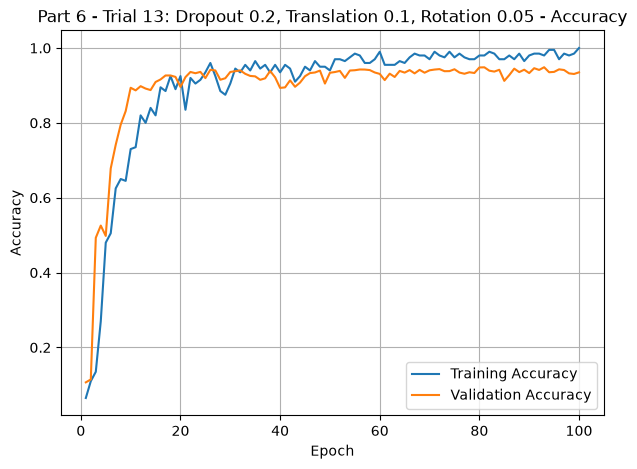

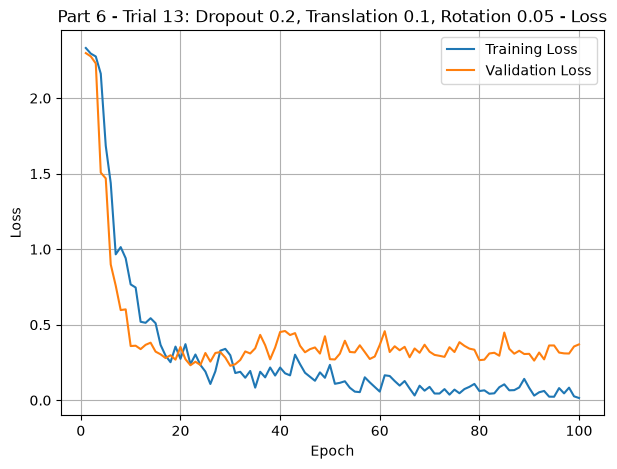

In [111]:
# 重新建立模型與增強層，從原本的固定初始化開始。
combined_model_13 = create_rotation_translation_model(
    weight_decay=COMBINED_WEIGHT_DECAY_13,
    dropout_rate=COMBINED_DROPOUT_RATE_13,
    translation_factor=COMBINED_TRANSLATION_FACTOR_13,
    rotation_factor=COMBINED_ROTATION_FACTOR_13
)

combined_model_13.summary()

print("Parameters:", combined_model_13.count_params())
print("Weight decay:", COMBINED_WEIGHT_DECAY_13)
print("Dropout rate:", COMBINED_DROPOUT_RATE_13)
print("Translation factor:", COMBINED_TRANSLATION_FACTOR_13)
print("Rotation factor:", COMBINED_ROTATION_FACTOR_13)
print(
    "Rotation range:",
    f"±{COMBINED_ROTATION_FACTOR_13 * 360:.1f}°"
)
print("Zoom: disabled")
print(
    "Initial optimizer updates:",
    int(combined_model_13.optimizer.iterations.numpy())
)

# 重新建立資料集，沿用相同的洗牌與 batch 設定。
combined_train_ds_13 = (
    tf.data.Dataset.from_tensor_slices((x_train, y_train))
    .shuffle(
        buffer_size=len(x_train),
        seed=2026,
        reshuffle_each_iteration=True
    )
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

# 獨立記錄第十三次的最佳驗證準確率與權重。
combined_best_13 = BestValidationAccuracy()

combined_history_13 = combined_model_13.fit(
    combined_train_ds_13,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    callbacks=[combined_best_13],
    verbose=2
)

# 還原最高 Validation Accuracy 的權重。
combined_model_13.set_weights(
    combined_best_13.best_weights
)

completed_epochs_13 = len(combined_history_13.history["loss"])
batches_per_epoch_13 = (
    len(x_train) + BATCH_SIZE - 1
) // BATCH_SIZE

print("\n=== Part 6: Combined Methods Trial 13 ===")
print("Completed epochs:", completed_epochs_13)
print(
    "Expected updates for a fresh model:",
    completed_epochs_13 * batches_per_epoch_13
)
print(
    "Actual optimizer updates:",
    int(combined_model_13.optimizer.iterations.numpy())
)
print(
    "Best Validation Accuracy:",
    f"{combined_best_13.best_accuracy:.2%}"
)
print("Best Epoch:", combined_best_13.best_epoch)
print("Best validation weights restored.")

plot_history(
    combined_history_13,
    title="Part 6 - Trial 13: Dropout 0.2, Translation 0.1, Rotation 0.05"
)

## Trial 14–16 — Weight Decay 比較

Fixed learning rate: 0.001
Fixed dropout rate: 0.2
Fixed translation factor: 0.1
Fixed rotation factor: 0.04
Zoom: disabled
Batch Normalization: disabled

Trial 14 - Weight decay = 0.0


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rotation_translation_augmentat… │ (None, 28, 28, 1)      │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2048)           │    12,847,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rotation_combined_dropout_1     │ (None, 2048)           │             0 │
│ (Dropout)                       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1024)           │     2,098,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rotation_combined_dropout_2     │ (None, 1024)           │             0 │
│ (Dropout)                       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rotation_combined_dropout_3     │ (None, 512)            │             0 │
│ (Dropout)                       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,734,218 (60.02 MB)

 Trainable params: 15,734,218 (60.02 MB)

 Non-trainable params: 0 (0.00 B)

Parameters: 15734218
Initial optimizer updates: 0
Epoch 1/100


2026-10-04 21:22:12.373925: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


7/7 - 6s - 804ms/step - accuracy: 0.0650 - loss: 2.3319 - val_accuracy: 0.2056 - val_loss: 2.2976
Epoch 2/100
7/7 - 4s - 510ms/step - accuracy: 0.1100 - loss: 2.2949 - val_accuracy: 0.1320 - val_loss: 2.2658
Epoch 3/100
7/7 - 4s - 519ms/step - accuracy: 0.2000 - loss: 2.2698 - val_accuracy: 0.3782 - val_loss: 2.2151
Epoch 4/100
7/7 - 3s - 493ms/step - accuracy: 0.2500 - loss: 2.1195 - val_accuracy: 0.4964 - val_loss: 1.4877
Epoch 5/100
7/7 - 4s - 609ms/step - accuracy: 0.4700 - loss: 1.6057 - val_accuracy: 0.5168 - val_loss: 1.4614
Epoch 6/100
7/7 - 4s - 521ms/step - accuracy: 0.5300 - loss: 1.4036 - val_accuracy: 0.6542 - val_loss: 0.9810
Epoch 7/100
7/7 - 4s - 519ms/step - accuracy: 0.6250 - loss: 0.9975 - val_accuracy: 0.7176 - val_loss: 0.7644
Epoch 8/100
7/7 - 3s - 494ms/step - accuracy: 0.6800 - loss: 0.8922 - val_accuracy: 0.7736 - val_loss: 0.6271
Epoch 9/100
7/7 - 3s - 492ms/step - accuracy: 0.7200 - loss: 0.7683 - val_accuracy: 0.8320 - val_loss: 0.5171
Epoch 10/100
7/7 - 4s 

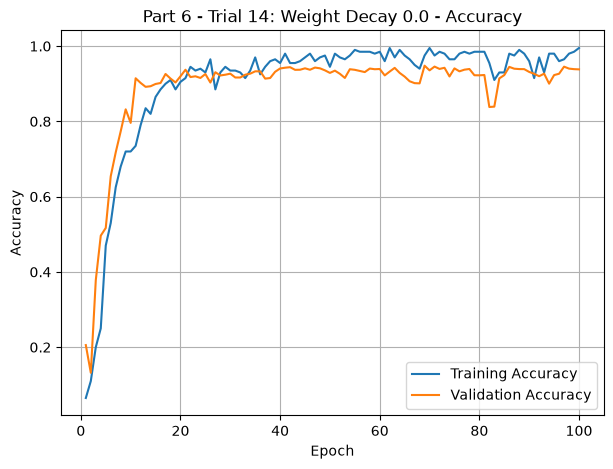

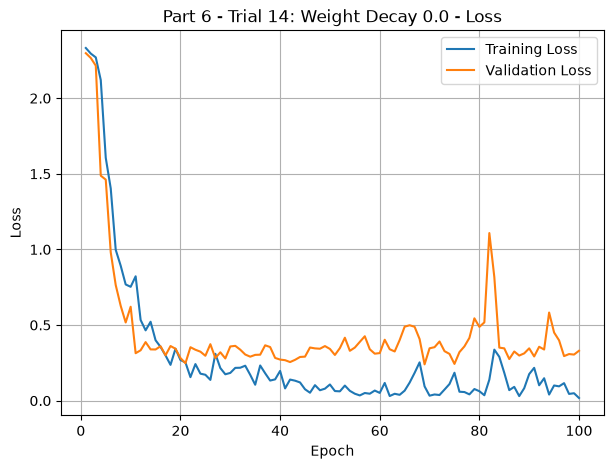


Trial 15 - Weight decay = 0.001


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rotation_translation_augmentat… │ (None, 28, 28, 1)      │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2048)           │    12,847,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rotation_combined_dropout_1     │ (None, 2048)           │             0 │
│ (Dropout)                       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1024)           │     2,098,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rotation_combined_dropout_2     │ (None, 1024)           │             0 │
│ (Dropout)                       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rotation_combined_dropout_3     │ (None, 512)            │             0 │
│ (Dropout)                       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,734,218 (60.02 MB)

 Trainable params: 15,734,218 (60.02 MB)

 Non-trainable params: 0 (0.00 B)

Parameters: 15734218
Initial optimizer updates: 0
Epoch 1/100


2026-10-04 21:29:25.814320: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


7/7 - 7s - 941ms/step - accuracy: 0.0650 - loss: 2.3319 - val_accuracy: 0.2014 - val_loss: 2.2976
Epoch 2/100
7/7 - 5s - 676ms/step - accuracy: 0.1150 - loss: 2.2950 - val_accuracy: 0.1288 - val_loss: 2.2644
Epoch 3/100
7/7 - 5s - 666ms/step - accuracy: 0.1750 - loss: 2.2713 - val_accuracy: 0.3876 - val_loss: 2.2156
Epoch 4/100
7/7 - 5s - 652ms/step - accuracy: 0.2500 - loss: 2.1221 - val_accuracy: 0.5200 - val_loss: 1.4786
Epoch 5/100
7/7 - 5s - 660ms/step - accuracy: 0.4800 - loss: 1.5968 - val_accuracy: 0.5392 - val_loss: 1.4065
Epoch 6/100
7/7 - 5s - 651ms/step - accuracy: 0.5400 - loss: 1.4012 - val_accuracy: 0.6598 - val_loss: 0.9317
Epoch 7/100
7/7 - 5s - 671ms/step - accuracy: 0.6300 - loss: 0.9623 - val_accuracy: 0.7208 - val_loss: 0.7856
Epoch 8/100
7/7 - 5s - 669ms/step - accuracy: 0.6850 - loss: 0.8825 - val_accuracy: 0.8360 - val_loss: 0.5429
Epoch 9/100
7/7 - 5s - 653ms/step - accuracy: 0.7800 - loss: 0.7413 - val_accuracy: 0.8718 - val_loss: 0.4162
Epoch 10/100
7/7 - 5s 

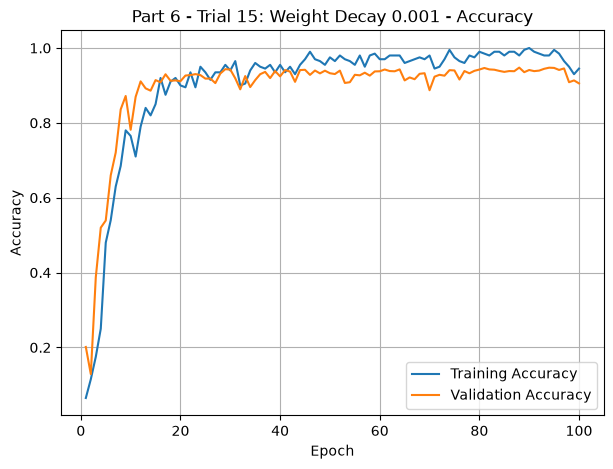

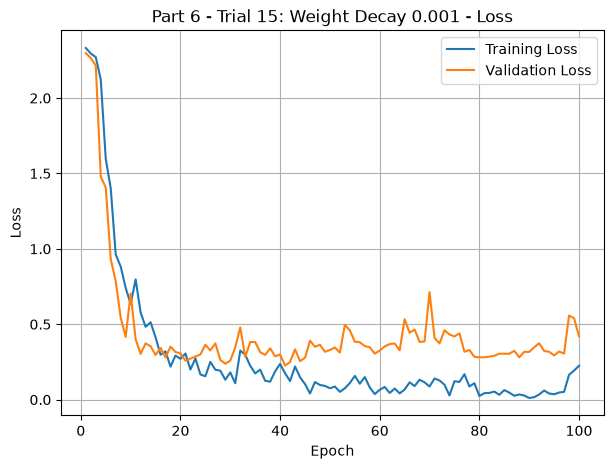


Trial 16 - Weight decay = 0.01


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rotation_translation_augmentat… │ (None, 28, 28, 1)      │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2048)           │    12,847,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rotation_combined_dropout_1     │ (None, 2048)           │             0 │
│ (Dropout)                       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1024)           │     2,098,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rotation_combined_dropout_2     │ (None, 1024)           │             0 │
│ (Dropout)                       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rotation_combined_dropout_3     │ (None, 512)            │             0 │
│ (Dropout)                       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,734,218 (60.02 MB)

 Trainable params: 15,734,218 (60.02 MB)

 Non-trainable params: 0 (0.00 B)

Parameters: 15734218
Initial optimizer updates: 0
Epoch 1/100


2026-10-04 21:37:18.424976: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


7/7 - 7s - 1s/step - accuracy: 0.0650 - loss: 2.3319 - val_accuracy: 0.2078 - val_loss: 2.2976
Epoch 2/100
7/7 - 5s - 737ms/step - accuracy: 0.1100 - loss: 2.2949 - val_accuracy: 0.1272 - val_loss: 2.2672
Epoch 3/100
7/7 - 5s - 709ms/step - accuracy: 0.1600 - loss: 2.2721 - val_accuracy: 0.3866 - val_loss: 2.2208
Epoch 4/100
7/7 - 5s - 684ms/step - accuracy: 0.2650 - loss: 2.1262 - val_accuracy: 0.4888 - val_loss: 1.5233
Epoch 5/100
7/7 - 5s - 683ms/step - accuracy: 0.4500 - loss: 1.6240 - val_accuracy: 0.5362 - val_loss: 1.4243
Epoch 6/100
7/7 - 5s - 704ms/step - accuracy: 0.5300 - loss: 1.4165 - val_accuracy: 0.6480 - val_loss: 0.9539
Epoch 7/100
7/7 - 5s - 672ms/step - accuracy: 0.6300 - loss: 1.0200 - val_accuracy: 0.7250 - val_loss: 0.7184
Epoch 8/100
7/7 - 5s - 667ms/step - accuracy: 0.6500 - loss: 0.9297 - val_accuracy: 0.7670 - val_loss: 0.6380
Epoch 9/100
7/7 - 5s - 687ms/step - accuracy: 0.7200 - loss: 0.8101 - val_accuracy: 0.8264 - val_loss: 0.5191
Epoch 10/100
7/7 - 5s - 6

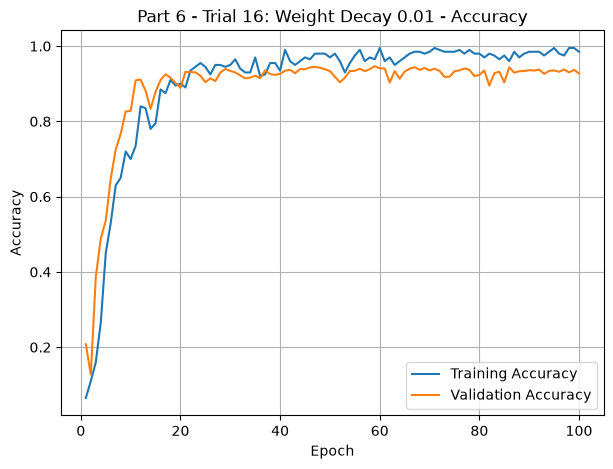

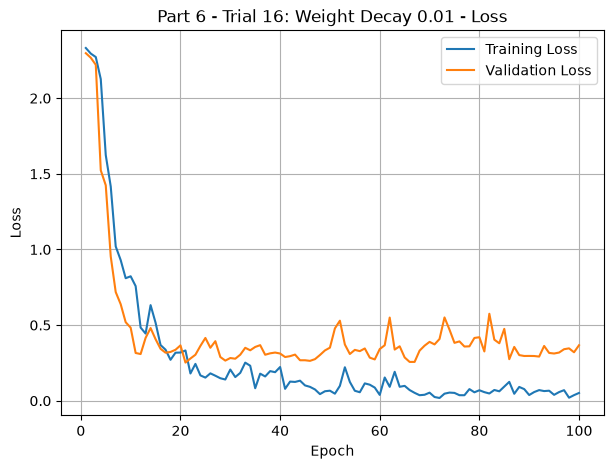


=== Weight Decay Comparison ===
 Trial  Weight Decay  Best Validation Accuracy (%)  Best Epoch  Val Loss at Best Accuracy
     9        0.0001                         95.32          71                     0.2708
    14        0.0000                         94.80          69                     0.2400
    15        0.0010                         94.76          88                     0.2807
    16        0.0100                         94.68          59                     0.2732

=== Selected Candidate by Validation Accuracy ===
Selected Trial: 9
Weight decay: 0.0001
Best Validation Accuracy: 95.32%
Best Epoch: 71


In [112]:
# 這輪只比較 Weight decay。
# 其他設定固定為目前最佳的第九次組合。
WD_SEARCH_DROPOUT_RATE = COMBINED_DROPOUT_RATE_9
WD_SEARCH_TRANSLATION_FACTOR = COMBINED_TRANSLATION_FACTOR_9
WD_SEARCH_ROTATION_FACTOR = COMBINED_ROTATION_FACTOR_9

weight_decay_candidates = [
    (14, 0.0),
    (15, 1e-3),
    (16, 1e-2)
]

weight_decay_trial_records = []

# 先保留第九次作為基準；相同準確率時維持第九次。
weight_decay_selected_trial = {
    "Trial": 9,
    "Weight Decay": COMBINED_WEIGHT_DECAY_9,
    "Model": combined_model_9,
    "History": combined_history_9,
    "Best": combined_best_9
}

print("Fixed learning rate: 0.001")
print("Fixed dropout rate:", WD_SEARCH_DROPOUT_RATE)
print("Fixed translation factor:", WD_SEARCH_TRANSLATION_FACTOR)
print("Fixed rotation factor:", WD_SEARCH_ROTATION_FACTOR)
print("Zoom: disabled")
print("Batch Normalization: disabled")

for trial_id, weight_decay in weight_decay_candidates:
    print("\n" + "=" * 60)
    print(f"Trial {trial_id} - Weight decay = {weight_decay}")
    print("=" * 60)

    # 每組都重新建立模型、增強層與 optimizer。
    trial_model = create_rotation_translation_model(
        weight_decay=weight_decay,
        dropout_rate=WD_SEARCH_DROPOUT_RATE,
        translation_factor=WD_SEARCH_TRANSLATION_FACTOR,
        rotation_factor=WD_SEARCH_ROTATION_FACTOR
    )

    trial_model.summary()

    print("Parameters:", trial_model.count_params())
    print(
        "Initial optimizer updates:",
        int(trial_model.optimizer.iterations.numpy())
    )

    # 每組重新建立資料集，維持相同的洗牌設定。
    trial_train_ds = (
        tf.data.Dataset.from_tensor_slices((x_train, y_train))
        .shuffle(
            buffer_size=len(x_train),
            seed=2026,
            reshuffle_each_iteration=True
        )
        .batch(BATCH_SIZE)
        .prefetch(tf.data.AUTOTUNE)
    )

    trial_best = BestValidationAccuracy()

    trial_history = trial_model.fit(
        trial_train_ds,
        validation_data=(x_val, y_val),
        epochs=EPOCHS,
        callbacks=[trial_best],
        verbose=2
    )

    # 還原該組最高 Validation Accuracy 的權重。
    trial_model.set_weights(trial_best.best_weights)

    completed_epochs = len(trial_history.history["loss"])
    batches_per_epoch = (
        len(x_train) + BATCH_SIZE - 1
    ) // BATCH_SIZE

    print("Completed epochs:", completed_epochs)
    print(
        "Expected updates for a fresh model:",
        completed_epochs * batches_per_epoch
    )
    print(
        "Actual optimizer updates:",
        int(trial_model.optimizer.iterations.numpy())
    )
    print(
        "Best Validation Accuracy:",
        f"{trial_best.best_accuracy:.2%}"
    )
    print("Best Epoch:", trial_best.best_epoch)
    print("Best validation weights restored.")

    trial_record = {
        "Trial": trial_id,
        "Weight Decay": weight_decay,
        "Model": trial_model,
        "History": trial_history,
        "Best": trial_best
    }

    weight_decay_trial_records.append(trial_record)

    # 必須嚴格高於目前候選，才更新選擇。
    if (
        trial_best.best_accuracy
        > weight_decay_selected_trial["Best"].best_accuracy
    ):
        weight_decay_selected_trial = trial_record

    plot_history(
        trial_history,
        title=f"Part 6 - Trial {trial_id}: Weight Decay {weight_decay}"
    )

# 整理第九次與本輪三組的驗證結果。
comparison_records = [
    {
        "Trial": 9,
        "Weight Decay": COMBINED_WEIGHT_DECAY_9,
        "Model": combined_model_9,
        "History": combined_history_9,
        "Best": combined_best_9
    }
] + weight_decay_trial_records

weight_decay_comparison = pd.DataFrame([
    {
        "Trial": record["Trial"],
        "Weight Decay": record["Weight Decay"],
        "Best Validation Accuracy (%)":
            record["Best"].best_accuracy * 100,
        "Best Epoch": record["Best"].best_epoch,
        "Val Loss at Best Accuracy":
            record["History"].history["val_loss"][
                record["Best"].best_epoch - 1
            ]
    }
    for record in comparison_records
])

print("\n=== Weight Decay Comparison ===")
print(
    weight_decay_comparison.round({
        "Best Validation Accuracy (%)": 2,
        "Val Loss at Best Accuracy": 4
    }).to_string(index=False)
)

print("\n=== Selected Candidate by Validation Accuracy ===")
print("Selected Trial:", weight_decay_selected_trial["Trial"])
print("Weight decay:", weight_decay_selected_trial["Weight Decay"])
print(
    "Best Validation Accuracy:",
    f'{weight_decay_selected_trial["Best"].best_accuracy:.2%}'
)
print("Best Epoch:", weight_decay_selected_trial["Best"].best_epoch)

## Trial 17 — Dropout 0.1

沿用第九次的 weight decay 0.0001、Translation 0.1、Rotation 0.04，僅降低 Dropout 至 0.1，從全新模型訓練 100 epochs。最佳 Validation Accuracy 為 95.20%，出現在 epoch 88，低於第九次的 95.32%；因此保留第九次，未對第十七次另行評估 Test。

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rotation_translation_augmentat… │ (None, 28, 28, 1)      │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2048)           │    12,847,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rotation_combined_dropout_1     │ (None, 2048)           │             0 │
│ (Dropout)                       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1024)           │     2,098,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rotation_combined_dropout_2     │ (None, 1024)           │             0 │
│ (Dropout)                       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rotation_combined_dropout_3     │ (None, 512)            │             0 │
│ (Dropout)                       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,734,218 (60.02 MB)

 Trainable params: 15,734,218 (60.02 MB)

 Non-trainable params: 0 (0.00 B)

Parameters: 15734218
Weight decay: 0.0001
Dropout rate: 0.1
Translation factor: 0.1
Rotation factor: 0.04
Zoom / BN / Early Stopping: disabled
Initial optimizer updates: 0
Epoch 1/100


/Users/c2838/NCHU/115-1 中興作業/computer_vision/c3_hw/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
2026-10-04 22:37:01.643450: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. 

7/7 - 6s - 826ms/step - accuracy: 0.0850 - loss: 2.3306 - val_accuracy: 0.1610 - val_loss: 2.2953
Epoch 2/100
7/7 - 3s - 493ms/step - accuracy: 0.1300 - loss: 2.2860 - val_accuracy: 0.0974 - val_loss: 2.2806
Epoch 3/100
7/7 - 3s - 474ms/step - accuracy: 0.1700 - loss: 2.2134 - val_accuracy: 0.5292 - val_loss: 1.8661
Epoch 4/100
7/7 - 3s - 493ms/step - accuracy: 0.4000 - loss: 1.8015 - val_accuracy: 0.4780 - val_loss: 1.5356
Epoch 5/100
7/7 - 3s - 496ms/step - accuracy: 0.4150 - loss: 1.6458 - val_accuracy: 0.5678 - val_loss: 1.0834
Epoch 6/100
7/7 - 4s - 512ms/step - accuracy: 0.5900 - loss: 1.1705 - val_accuracy: 0.6446 - val_loss: 0.9116
Epoch 7/100
7/7 - 3s - 473ms/step - accuracy: 0.6200 - loss: 0.9260 - val_accuracy: 0.8474 - val_loss: 0.5185
Epoch 8/100
7/7 - 3s - 480ms/step - accuracy: 0.7550 - loss: 0.7925 - val_accuracy: 0.8576 - val_loss: 0.4579
Epoch 9/100
7/7 - 3s - 492ms/step - accuracy: 0.7850 - loss: 0.6056 - val_accuracy: 0.9008 - val_loss: 0.3348
Epoch 10/100
7/7 - 4s 

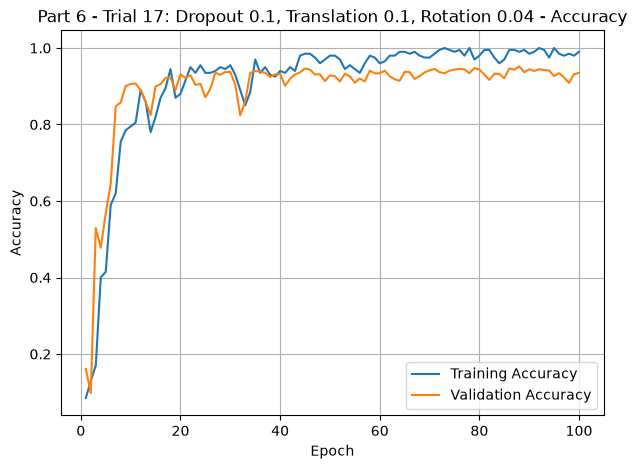

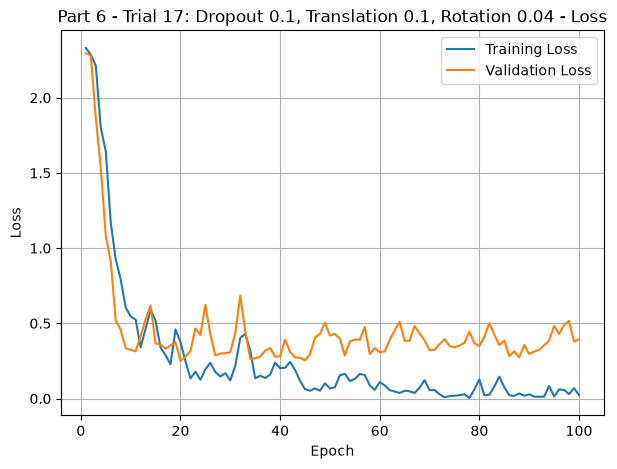

In [122]:
# 第十七次只降低 Dropout，其餘沿用第九次。
COMBINED_WEIGHT_DECAY_17 = COMBINED_WEIGHT_DECAY_9
COMBINED_DROPOUT_RATE_17 = 0.1
COMBINED_TRANSLATION_FACTOR_17 = COMBINED_TRANSLATION_FACTOR_9
COMBINED_ROTATION_FACTOR_17 = COMBINED_ROTATION_FACTOR_9

# 重新建立模型，從原本的固定初始化開始。
combined_model_17 = create_rotation_translation_model(
    weight_decay=COMBINED_WEIGHT_DECAY_17,
    dropout_rate=COMBINED_DROPOUT_RATE_17,
    translation_factor=COMBINED_TRANSLATION_FACTOR_17,
    rotation_factor=COMBINED_ROTATION_FACTOR_17
)

combined_model_17.summary()

print("Parameters:", combined_model_17.count_params())
print("Weight decay:", COMBINED_WEIGHT_DECAY_17)
print("Dropout rate:", COMBINED_DROPOUT_RATE_17)
print("Translation factor:", COMBINED_TRANSLATION_FACTOR_17)
print("Rotation factor:", COMBINED_ROTATION_FACTOR_17)
print("Zoom / BN / Early Stopping: disabled")
print(
    "Initial optimizer updates:",
    int(combined_model_17.optimizer.iterations.numpy())
)

# 每次重新建立資料集，維持相同的洗牌與 batch 設定。
combined_train_ds_17 = (
    tf.data.Dataset.from_tensor_slices((x_train, y_train))
    .shuffle(
        buffer_size=len(x_train),
        seed=2026,
        reshuffle_each_iteration=True
    )
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

combined_best_17 = BestValidationAccuracy()

combined_history_17 = combined_model_17.fit(
    combined_train_ds_17,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    callbacks=[combined_best_17],
    verbose=2
)

# 還原最高 Validation Accuracy 的權重。
combined_model_17.set_weights(
    combined_best_17.best_weights
)

completed_epochs_17 = len(combined_history_17.history["loss"])
batches_per_epoch_17 = (
    len(x_train) + BATCH_SIZE - 1
) // BATCH_SIZE

print("\n=== Part 6: Combined Methods Trial 17 ===")
print("Completed epochs:", completed_epochs_17)
print(
    "Expected updates for a fresh model:",
    completed_epochs_17 * batches_per_epoch_17
)
print(
    "Actual optimizer updates:",
    int(combined_model_17.optimizer.iterations.numpy())
)
print(
    "Best Validation Accuracy:",
    f"{combined_best_17.best_accuracy:.2%}"
)
print("Best Epoch:", combined_best_17.best_epoch)
print("Best validation weights restored.")

# 使用 callback 的完整數值比較，不使用四捨五入後的百分比。
is_trial17_better = (
    combined_best_17.best_accuracy
    > combined_best_9.best_accuracy
)

print(
    "\nTrial 9 Best Validation Accuracy:",
    f"{combined_best_9.best_accuracy:.2%}"
)
print(
    "Validation improvement over Trial 9:",
    f"{(combined_best_17.best_accuracy - combined_best_9.best_accuracy) * 100:+.2f}"
    " percentage points"
)
print(
    "Selected candidate:",
    "Trial 17" if is_trial17_better else "Trial 9"
)

plot_history(
    combined_history_17,
    title="Part 6 - Trial 17: Dropout 0.1, Translation 0.1, Rotation 0.04"
)

## Part 6 — 全部候選的驗證結果比較

以下表格整理各組已完成的訓練紀錄，候選比較以最佳 Validation Accuracy 為依據。第九次為本次驗證表現最高的設定，保留其最佳 epoch 權重。

In [124]:
def make_part6_summary(trial_id, settings, history, best):
    return {
        "Trial": trial_id,
        "Settings": settings,
        "Completed Epochs": len(history.history["loss"]),
        "Best Validation Accuracy (%)": best.best_accuracy * 100,
        "Best Epoch": best.best_epoch
    }


part6_summary_rows = [
    make_part6_summary(1, "WD=1e-4, Dropout=0.5, Translation=0.1", combined_history, combined_best),
    make_part6_summary(2, "WD=1e-4, Dropout=0.2, Translation=0.1", combined_history_2, combined_best_2),
    make_part6_summary(3, "Trial 2 + EarlyStopping(val_accuracy, patience=10)", combined_history_3, combined_best_3),
    make_part6_summary(4, "Trial 2 + BN(momentum=0.9)", combined_history_4, combined_best_4),
    make_part6_summary(5, "Trial 2, Translation=0.15", combined_history_5, combined_best_5),
    make_part6_summary(6, "Trial 2, Translation=0.2", combined_history_6, combined_best_6),
    make_part6_summary(7, "Trial 5 + BN(momentum=0.9)", combined_history_7, combined_best_7),
    make_part6_summary(8, "Trial 2 + Rotation=0.03", combined_history_8, combined_best_8),
    make_part6_summary(9, "Trial 2 + Rotation=0.04", combined_history_9, combined_best_9),
    make_part6_summary(10, "Trial 9, Dropout=0.3", combined_history_10, combined_best_10),
    make_part6_summary(11, "Trial 9, Dropout=0.4 + Zoom=0.05", combined_history_11, combined_best_11),
    make_part6_summary(12, "Trial 9, Dropout=0.3 + Zoom=0.05", combined_history_12, combined_best_12),
    make_part6_summary(13, "Trial 9, Rotation=0.05", combined_history_13, combined_best_13)
]

for record in weight_decay_trial_records:
    part6_summary_rows.append(
        make_part6_summary(
            record["Trial"],
            f'Trial 9, WD={record["Weight Decay"]:g}',
            record["History"],
            record["Best"]
        )
    )

part6_summary_rows.append(
    make_part6_summary(
        17,
        "Trial 9, Dropout=0.1",
        combined_history_17,
        combined_best_17
    )
)

part6_comparison = pd.DataFrame(part6_summary_rows)

print("=== Part 6: Validation Comparison ===")
print(
    part6_comparison.round({
        "Best Validation Accuracy (%)": 2
    }).to_string(index=False)
)

best_summary = max(
    part6_summary_rows,
    key=lambda row: row["Best Validation Accuracy (%)"]
)

print("\nSelected Trial by Validation Accuracy:", best_summary["Trial"])
print("Best Epoch:", best_summary["Best Epoch"])

=== Part 6: Validation Comparison ===
 Trial                                           Settings  Completed Epochs  Best Validation Accuracy (%)  Best Epoch
     1              WD=1e-4, Dropout=0.5, Translation=0.1               100                         94.08          99
     2              WD=1e-4, Dropout=0.2, Translation=0.1               100                         94.32          52
     3 Trial 2 + EarlyStopping(val_accuracy, patience=10)                41                         94.30          31
     4                         Trial 2 + BN(momentum=0.9)               100                         93.28          45
     5                          Trial 2, Translation=0.15               100                         94.10          97
     6                           Trial 2, Translation=0.2               100                         93.16          94
     7                         Trial 5 + BN(momentum=0.9)               100                         93.80          86
     8            

## Part 6 — 最終模型評估

所有候選比較完成後，列出選定第九次模型的設定、既有 Test 結果與相對教師 baseline 的提升。

In [120]:
# 依目前實驗的最佳 Validation Accuracy，選擇第九次。
combined_selected_model = combined_model_9
combined_selected_history = combined_history_9
combined_selected_best = combined_best_9

# 評估前再次明確還原最佳驗證權重，不需要重新訓練。
combined_selected_model.set_weights(
    combined_selected_best.best_weights
)

print("Selected Trial: 9")
print("Weight decay:", COMBINED_WEIGHT_DECAY_9)
print("Dropout rate:", COMBINED_DROPOUT_RATE_9)
print("Translation factor:", COMBINED_TRANSLATION_FACTOR_9)
print("Rotation factor:", COMBINED_ROTATION_FACTOR_9)
print("Batch Normalization: No")
print("Best Epoch:", combined_selected_best.best_epoch)

# 使用老師提供的函式，評估未經增強的 Train、Validation、Test。
evaluate_model(
    "Part 6 - Combined Methods",
    combined_selected_model,
    combined_selected_history
)

# 將最終選擇與設定記錄在結果中。
results["Part 6 - Combined Methods"].update({
    "Selected Trial": 9,
    "Weight Decay": COMBINED_WEIGHT_DECAY_9,
    "Dropout Rate": COMBINED_DROPOUT_RATE_9,
    "Translation Factor": COMBINED_TRANSLATION_FACTOR_9,
    "Rotation Factor": COMBINED_ROTATION_FACTOR_9,
    "Best Epoch": combined_selected_best.best_epoch
})

# 依老師原始範例的 Test Accuracy 92.70% 計算提升。
TEACHER_BASELINE_TEST_ACCURACY = 0.9270

final_test_accuracy = (
    results["Part 6 - Combined Methods"]["Test Accuracy"]
)

improvement_pp = (
    final_test_accuracy - TEACHER_BASELINE_TEST_ACCURACY
) * 100

print(
    "\nTeacher baseline Test Accuracy:",
    f"{TEACHER_BASELINE_TEST_ACCURACY:.2%}"
)
print("Final Test Accuracy:", f"{final_test_accuracy:.2%}")
print("Improvement:", f"{improvement_pp:.2f} percentage points")

Selected Trial: 9
Weight decay: 0.0001
Dropout rate: 0.2
Translation factor: 0.1
Rotation factor: 0.04
Batch Normalization: No
Best Epoch: 71


2026-10-04 22:14:55.815459: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


Part 6 - Combined Methods
Train Accuracy      : 0.9950
Validation Accuracy : 0.9532
Best Val Accuracy   : 0.9532
Test Accuracy       : 0.9555
Train-Val Gap       : 0.0418

Teacher baseline Test Accuracy: 92.70%
Final Test Accuracy: 95.55%
Improvement: 2.85 percentage points


## Part 6 — 最終設定與結果分析

| 項目 | 最終設定 |
|---|---|
| 選定實驗 | Trial 9 |
| 原始 CNN | 維持範例的 Conv、Pooling、Dense 與固定初始化設定 |
| Optimizer | Adam，learning rate = 0.001 |
| Weight decay | 0.0001 |
| Dropout | 三個隱藏 Dense activation 後各加入 0.2 |
| Data Augmentation | Rotation → Translation，僅用於訓練 |
| Rotation | factor = 0.04，範圍 ±14.4°，seed = 4102 |
| Translation | height/width factor = 0.1，seed = 4101 |
| 增強填補與插值 | constant、fill value = 0.0、bilinear |
| Zoom / BN / Early Stopping | 最終模型未使用 |
| Batch size / Epochs | 32 / 100 |
| Dataset shuffle | seed = 2026，每個 epoch 重新洗牌 |
| 模型參數 | 15,734,218 |
| 權重選擇 | 最高 Validation Accuracy；最佳 epoch = 71 |
| Best Validation Accuracy | 95.32% |
| Final Test Accuracy | 95.55% |
| 教師 Baseline Test Accuracy | 92.70% |
| Improvement | 95.55% − 92.70% = 2.85 個百分點 |

1. 本實驗維持範例原始 CNN 的架構與訓練設定，組合 optimizer weight decay、隱藏 Dense 層後的 Dropout，以及訓練資料的隨機旋轉與平移。
2. 平移與小幅旋轉用來模擬書寫位置及傾斜的差異，Dropout 與權重衰減則用來降低模型對少量訓練樣本和特定特徵組合的依賴。
3. 比較各候選的最佳 Validation Accuracy 後，選定 weight decay 0.0001、Dropout 0.2、Translation 0.1、Rotation 0.04 的第九次實驗，較高 Dropout、Zoom、較大旋轉及其他 weight decay 候選皆未超過其驗證準確率，最後補測 Dropout 0.1 的第十七次實驗亦僅達 95.20%，因此維持第九次為最終模型。
4. 最終模型還原第 71 個 epoch 的權重，Validation Accuracy 為 95.32%，Test Accuracy 為 95.55%，相較教師提供的 baseline 92.70% 提升 2.85 個百分點。
5. 最終模型在原始訓練資料上的 Accuracy 為 99.50%，與 Validation 的差距為 4.18 個百分點，且訓練後期仍可見 Validation Loss 上升，因此過擬合仍存在，但泛化差距小於本機 baseline 的 9.44 個百分點。

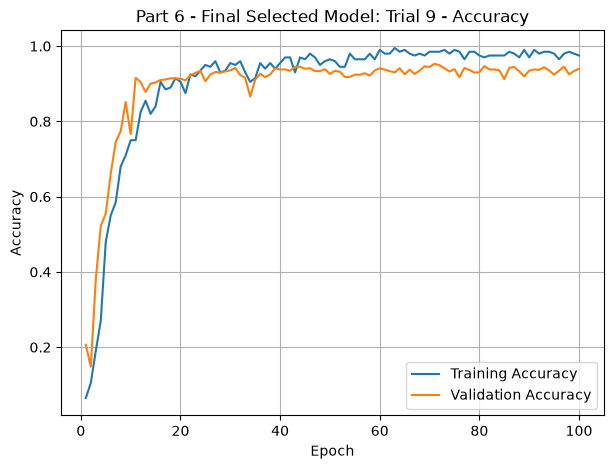

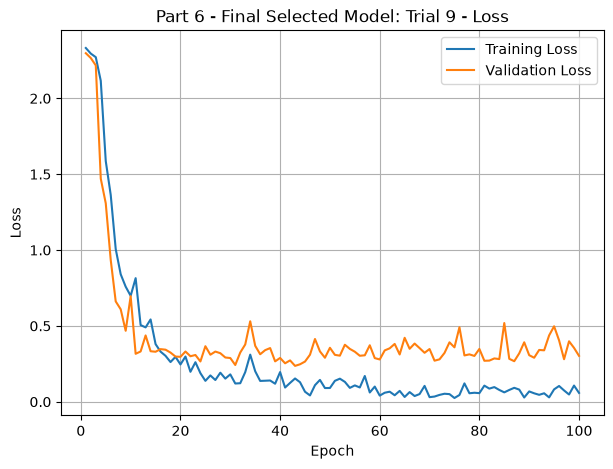

In [115]:
plot_history(combined_history_9, title="Part 6 - Final Selected Model: Trial 9")

## Part 0–6 — 最終結果比較

Part 0 的 Test Accuracy 是本機執行結果 92.09%；Part 6 的評分 Improvement 使用教師提供的參考值 92.70%。Part 0 沿用範例以第 100 個 epoch 的權重評估，Part 1–3、5、6 採最高 Validation Accuracy 的權重，Part 4 採最低 Validation Loss 的權重。

In [116]:
part_result_order = [
    ("Part 0 - Baseline", "Baseline"),
    ("Part 1 - Weight Decay", "Part 1 - Weight Decay"),
    ("Part 2 - Dropout", "Part 2 - Dropout"),
    ("Part 3 - Translation", "Part 3 - Translation"),
    ("Part 4 - Early Stopping", "Part 4 - Early Stopping"),
    ("Part 5 - Batch Normalization", "Part 5 - Batch Normalization"),
    ("Part 6 - Combined Methods", "Part 6 - Combined Methods")
]

missing_parts = [
    key for _, key in part_result_order if key not in results
]
if missing_parts:
    raise RuntimeError(f"results 尚缺少：{missing_parts}")

final_summary_rows = []
for label, key in part_result_order:
    result = results[key]
    final_summary_rows.append({
        "Part": label,
        "Train Accuracy (%)": result["Train Accuracy"] * 100,
        "Validation Accuracy (%)": result["Validation Accuracy"] * 100,
        "Best Validation Accuracy (%)": result["Best Validation Accuracy"] * 100,
        "Test Accuracy (%)": result["Test Accuracy"] * 100,
        "Train-Val Gap (pp)": result["Train-Val Gap"] * 100
    })

final_summary = pd.DataFrame(final_summary_rows)
print(final_summary.round(2).to_string(index=False))

                        Part  Train Accuracy (%)  Validation Accuracy (%)  Best Validation Accuracy (%)  Test Accuracy (%)  Train-Val Gap (pp)
           Part 0 - Baseline               100.0                    90.56                         90.58              92.09                9.44
       Part 1 - Weight Decay               100.0                    91.06                         91.06              92.90                8.94
            Part 2 - Dropout               100.0                    92.48                         92.48              93.54                7.52
        Part 3 - Translation               100.0                    94.32                         94.32              95.10                5.68
     Part 4 - Early Stopping                99.0                    89.46                         89.46              90.64                9.54
Part 5 - Batch Normalization               100.0                    89.98                         89.98              91.32               10.02

## 整體比較

在單一方法實驗中，Translation 的 Test Accuracy 為 95.10%，是 Part 1–5 中最高的結果；Early Stopping 與 BN 在本次設定下未超過本機 baseline。Part 6 的組合模型依 Validation Accuracy 選定後，Test Accuracy 為 95.55%，但不能因此推論所有改進方法疊加都會提高表現。各方法的效果取決於資料量、增強幅度與其他正規化設定，失敗候選也保留於本 notebook 作為比較紀錄。